# 土地と知財と借金
## ── 2019年の資産市場シミュレーションの解剖

## 第 0 章 このノートについて

文責: JRF ( http://jrf.cocolog-nifty.com/statuses/ )<br>
解析・執筆の補助: Claude Opus 5.5 (Anthropic)<br>
2026年10月

---

### この文書について

この文書は、同じ作者の経済シミュレーションを読み直すシリーズの三冊目である。

- ノート 1「価格を最適化で決める経済 ── 2020年までの micro_economy モデルの解剖」は、2018〜2020 年の商品市場のシミュレーション `micro_economy_*.py` を解剖した。
- ノート O「経済の中で経済が育つ ── 2011年の外作用モデルと『埋め込み』の遷移」は、その前の 2011 年に Perl で作られた小さな経済シミュレーションを解剖し、そこから「経済の中で別の経済が育ち、全体に格上げされる」遷移を考えた。

この文書が扱うのは、2019 年に作られた「**資産市場の簡易シミュレーション**」(`simple_market_a1_*.py`)である。2011 年のモデルの後継として、土地と知的財産(以下、知財)の市場を作り、それを、賃金と贅沢品だけの商品市場とからめた。作者は、いずれこれを `micro_economy_*.py` と組み合わせるつもりだった。

作者は、このモデルを作った動機を次のように書いている。`micro_economy_*.py` では、貯蓄の初期値を指数分布にしていたが、シミュレーションを進めると、貯蓄はだんだん平等になり、指数分布でなくなった。「定常状態が初期値と同じ形になれば、モデルは安定するのではないか」。富の分布が指数分布になるのは、二人がランダムに富を分け合う交換を繰り返すときだと知り、では、資産の取引を別に考えたらどうか、と考えた。

そして、作者は、二つの記事の終わりに、いくつかの問いを残した。

- 資産を売って得た現金で贅沢品を買えば、お金は資産市場から商品市場へ流れ出る(作者はこれを **Erosion**、取り崩し、と呼んだ)。賃金から借金を返せば、お金は商品市場から資産市場へ戻る(**返済**)。この二つが、なぜか釣り合い、全員の借金の合計は、際限なく増えも減りもしなかった。作者は「おそらく平均への回帰のため」と書き、「それがどういう額で釣り合うかも示せればカッコイイが、私には手にあまる」と書いた。
- 返済率を変えても、贅沢品の需要がほとんど変わらなかった。「金融政策」(手元で借りられる余地を増やす)の効果は一時的で、「消費税」(価格を変える)の効果は長く続いた。
- 富の分布は、指数分布にも正規分布にも落ち着かなかった。

この文書では、これらの問いに答える。さらに、作者が 2021〜22 年に「ひとこと」に書いた構想(資本主義の基礎等式、知財総額 = 株価総額、担保としての土地)を、式にして検討する。

### このシリーズ

同じ作者(JRF)の、AI 以前の経済の模型と構想を、今の目で読み直すシリーズである。書かれた順に並べる(読む順の勧めも同じ)。ノート O の O は Origin(始まり)で、作者の経済のシミュレーションの始まりにあたる 2011 年の模型を扱う。

- ノート 1「価格を最適化で決める経済 ── 2020年までの micro_economy モデルの解剖」(`micro_economy_anatomy.ipynb`)
- ノート O「経済の中で経済が育つ ── 2011年の外作用モデルと『埋め込み』の遷移」(`embedded_economy.ipynb`)
- ノート 2「土地と知財と借金 ── 2019年の資産市場シミュレーションの解剖」(`asset_market.ipynb`) ← **この文書**
- ノート P「ポイントと年金と信用 ── ネットの小さな通貨の設計(2006〜2018)」(`points_pension.ipynb`)
- ノート I「必需品と贅沢品の宇宙的独立関係 ── 絶滅の確率、0 × ∞、ナイト的不確実性、そして学習」(`cosmic_independence.ipynb`)
- ノート 3「誰が一家離散するのか ── シミュレーション仏教の経済と、裾の重い運」(`simbd_economy.ipynb`)
- ノート M「雑多なモデルの再検討 ── 必需品と贅沢品、縁故主義、投票、AI と弾圧」(`misc_models.ipynb`)
- ノート 4「2026年の経済モデル統合 ── 価格と信用と土地と災害、そして一人の暮らし」(`integrated_model.ipynb`)

### 系譜

| 年 | モデル | このシリーズ |
|---|---|---|
| 2011 | 外作用的簡易経済シミュレーション(Perl、`simple_market_0.pl`)。現金をマイナスの負債として書く | ノート O |
| 2018〜2020 | ミクロ経済学の我流シミュレーション(`micro_economy_*.py`)。価格を最適化で決める商品市場 | ノート 1 |
| 2019 | **資産市場の簡易シミュレーション(`simple_market_a1_*.py`)**。土地と知財の市場 + 賃金と贅沢品の商品市場 | **この文書** |
| 2021〜22 | 「ひとこと」での構想。資本主義の基礎等式、知財総額 = 株価総額、担保としての土地 | この文書の第 6 章 |
| 2026 | 信用循環モデル(「信用創造はどこで止まるのか」「信用の世界経済は一つか」) | 第 7 章で小さくつなぐ |

作者は、公開した日の「ひとこと」に、このモデルが 2011 年のモデルの後継でありながら、多くの考えを失ったと書いている。入れ子の構造、カタストロフィックな遷移(ノート O の主題)、そして greed(借金が多い者は、必需品の値を上げようとする。借金を増やさない方向へのインセンティブ)である。また、2011 年のモデルは、当時盛んだったベーシックインカム論の影響を受けて、働くのはランダムに選ばれた者だけだったが、2019 年のモデルは `micro_economy_*.py` にならって、働くのが基本になった。ただし、借金がかなり自由にできる点は、そのまま残った。

### この文書で考える問い

1. 2019 年のモデルは何をしていたのか。今の目で見て、どこが筋が良く、どこが足りなかったのか。
2. 全 Erosion と全返済は、なぜ釣り合うのか。どういう額で釣り合うのか。借金の合計は、なぜ際限なく増えないのか。
3. 返済率を変えても、なぜ贅沢品の需要が変わらないのか。お金の操作の効果が一時的で、価格の効果が長く続くのは、なぜか。
4. 富の分布は、どういう形に落ち着くのか。初期値と同じ形に戻る分布は、どういうものか。
5. 土地(減価しない資産)と知財(減価する資産)は、何が違うのか。知財を買うのは誰か。免許と懲罰的罰金は、知識の蓄積をどう変えるか。
6. 2021〜22 年の構想は、どう式にできるのか。信用循環モデルの「株式的な富」を、土地と知財に分けると何が見えるのか。

### 答えの見通し

結論を先に書いておく(詳しくは各章と、第 8 章のまとめで)。

1. **元のコードは、今の Python でもそのまま動き、書き直した版でぴったり同じ計算ができる**(第 1 章)。記事の実験は、乱数の種を変えて多数回走らせても、すべて記事の記述どおりに再現される。
2. **帳簿は、モデルの外にいる相手方(企業・国・銀行)を部門として置けば閉じる**(第 2 章)。そのとき、企業が失業手当の分だけ黒字を貯め込み、お金が経済から漏れていることがわかる。作者が 2022 年に「商品市場の現金バランスを見ていなかった」と書いたのは、このことである。
3. **贅沢品の需要が返済率によらず 500 前後なのは、「(賃金 − 必需品)× 働く人数 ÷ 贅沢品の値段」で決まるからである**(第 3 章)。正味の金融資産が落ち着く限り、流れは所得で決まり、返済率や借り入れの余地はストックを動かすだけである。「金融政策は一時的、消費税は持続」も、これで説明できる。
4. **全 liability は、「Erosion の曲線」と「返済の曲線」の交点で釣り合う**(第 3 章)。二つの曲線は、全 liability を留め置く実験で測れる。釣り合いを生むのは、平均への回帰ではなく、流れがストックに応じて変わる負のフィードバックである。返済率 0.1 でも、増加はいずれ終わる。このモデルは、ゼロ金利で借入に上限のない経済で、利子を入れると借入の上限と貸倒れの仕組みが要る。
5. **知財はガンマ分布、貯蓄は 0 のかたまりと 5 の倍数のとがり、正味資産はガンマ分布に近い形に落ち着く**(第 4 章)。初期値をこの形にそろえれば、モデルは最初から定常状態で動く。逆転のしやすさは、主に「誰が売り手になって代金を受け取るか」で決まる。
6. **知財の切り下げは、総額を保つ内生的な減耗率である。知財の評価は、積まれたのと同じ期のうちに全体として消える**(第 5 章)。土地には値段がなく、値段を動かすと、手元のお金の多さで決まる。2020 年の「免許と懲罰的罰金」は、「免許のほうが平等で、知見を多く生む」の部分が数で確かめられた。
7. **2021〜22 年の「資本主義の基礎等式」の最初の形は、ピケティの第二基本法則と同じ構造である**(第 6 章)。「担保としての土地」は、取引できる土地を増やすと、担保のある経済でだけ信用が増える形で現れる。「国庫からの持ち出しは純現金増になる」は、政府の赤字 = 民間の黒字の恒等式そのものである。
8. **信用循環モデル(v6)に土地を担保として足すと、担保の上限が外れ、好況も崩れも大きくなる**(第 7 章)。本格的な統合は、ノート 4 で行った。

### 読み方

- 上から順にコードのセルを実行すれば、全部動く。使うのは numpy、scipy、matplotlib である。
- 2019 年の元のコードは、GitHub から決まった版を取ってきて、中身が同じことを sha256 で確かめてから走らせる。
- 元のコードを書き直した版(`sma1.py`)も作り、元のコードとぴったり同じ計算をすることを確かめてから使う。

### 目次

- 第 0 章 このノートについて
- 第 1 章 2019 年のモデルを動かす
- 第 2 章 解剖
- 第 3 章 借金はなぜ際限なく増えないのか
- 第 4 章 富の分布と、逆転のチャンス
- 第 5 章 土地と知財
- 第 6 章 2021〜22 年の構想を式にする
- 第 7 章 信用循環モデルとつなぐ
- 第 8 章 まとめと、続くノートへ
- 付録 A: 再現のために
- 付録 B: 用語集
- 付録 C: 過去の議論
- 参考文献

### Lean による証明

v0.1 では Lean を使わなかった。v0.2 で、議論の要の命題のいくつかを、**Lean 4**(と Mathlib)で証明した。章ごとに `%%writefile -a asset_market.lean` で書き足し、第 8 章の最後で一括して確かめる。

| 章 | 定理 | 中身 |
|---|---|---|
| 3 | `demand_pinned`、`unique_crossing` | 正味の資産が落ち着けば、贅沢品の需要は (賃金 − 必需品) × 人数 / 値段 に決まる。借り入れが右下がり、返済が右上がりなら、落ち着き先は高々一つ |
| 5 | `stock_steady`、`stock_steady_antitone`、`capitalized_value_antitone` | 減耗する資産の定常の量は 流入 ÷ 減耗率 で、減耗が速いほど小さい。値打ち = 利回りの元 ÷ (金利 + 減耗) は、減耗しない土地のほうが高い |

In [1]:
%%writefile asset_market.lean
/-
  「土地と知財と借金」(ノート 2)の Lean による定式化
  文責: JRF / 定式化・証明: Claude Opus 5.5
  Lean 4 v4.34.1 + Mathlib
-/
import Mathlib

namespace AssetMarket

Writing asset_market.lean


### 準備

In [2]:
import os, time, importlib, multiprocessing as mp
import numpy as np
import matplotlib.pyplot as plt

FAST = False                       # True にすると回数を減らして速く回す
N_JOBS = int(os.environ.get('NB_JOBS', max(1, (os.cpu_count() or 2) - 1)))   # 並列の数(環境変数 NB_JOBS で減らせる)

PAL = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
INK, INK2, GRID = '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.edgecolor': INK2, 'axes.labelcolor': INK, 'xtick.color': INK2, 'ytick.color': INK2,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
    'axes.spines.top': False, 'axes.spines.right': False,
    'lines.linewidth': 2.0, 'font.size': 10, 'axes.titlesize': 11, 'legend.frameon': False,
    'figure.dpi': 100,
})


def pmap(f, jobs):
    """jobs を並列に f で計算する。f は %%writefile で書いたモジュールの関数にする。"""
    with mp.get_context('fork').Pool(min(N_JOBS, len(jobs))) as pool:
        return pool.map(f, jobs)


import sys, scipy, matplotlib
print('Python', sys.version.split()[0], '/ numpy', np.__version__, '/ scipy', scipy.__version__,
      '/ matplotlib', matplotlib.__version__, '/ CPU', os.cpu_count())

Python 3.14.4 / numpy 2.5.4 / scipy 1.18.1 / matplotlib 3.11.2 / CPU 28


## 第 1 章 2019 年のモデルを動かす

### 1.1 モデルの部品

1000 人のプレイヤーがいる。一人一人が、次の四つを持つ。

| 変数 | 意味 |
|---|---|
| `savings`(貯蓄) | 商品市場で使うお金。0 より小さくはならない |
| `liability`(借金) | 資産市場の貸し借り。**マイナスなら現金を持っている**(2011 年のモデルと同じ書き方) |
| `land`(土地) | 一単位 10 で売り買いされる。値段は 10 に固定。減りも増えもしない |
| `intellprop`(知財) | 売っても減らず、何度でも売れる。買うと、払った値段より高い評価で積み上がる |

最初の値は、貯蓄が平均 10 の指数分布、土地が平均 20 の指数分布(10 単位に丸める)、知財が平均 20 の指数分布、借金が平均 0 の正規分布(全員の和が 0 になるように、プラスの側を縮める)である。

一期の流れは、次のとおりである。

1. **働く人を決める**。600〜900 人のあいだの数を乱数で決め、その人数が働く。前の期に働いた人が先に選ばれる(後で述べる)。
2. **土地の市場**: 300 件の売り買い。売り手が土地を一単位(10)以上持っていれば、値段 10 で一単位を売る。買い手の借金が 10 増え、売り手の借金が 10 減る(現金が 10 増える)。
3. **知財の市場**: 300 件の売り買い。値段は、0 から「売り手の知財 + 売り手の土地から決まる額」までの一様乱数で決まる。買い手は、その値段以上の評価額(値段から「値段 + $\sqrt{0.25 \times \text{値段} \times \text{買い手の知財}}$」までの一様乱数)を、自分の知財に積む。借金は、値段の分だけ、買い手から売り手へ移る。
4. **商品市場**: 賃金は 30、必需品は一つ 10 で二つ要る、贅沢品は 15。働く人は、賃金から必需品を引いた 10 のうち、借金があれば半分(返済率 0.5)を返す。贅沢品を買うかどうかは、手元のお金(貯蓄 + 現金)で決まる。働かない人の必需品は、「社会的負債」が払う(失業手当)。
5. 貯蓄が足りずに 0 を割ったら、その分を借金に足す(現金を持っていれば、現金が減る)。これが **Erosion**(取り崩し)である。

**貯蓄が増えるのは、働く人が贅沢品を買わなかった期だけである。** 一期の貯蓄の動きを、場合ごとに書くと次のとおりである(返済は、借金のある働く人だけが、10 × 返済率 = 5 を払う)。

| 場合 | 貯蓄の変化(一期) |
|---|---|
| 働く人、贅沢品を買わない | +10(借金があれば、返済を引いて +5) |
| 働く人、贅沢品を買う | −5(借金があれば、返済を引いて −10) |
| 働かない人、贅沢品を買わない | 0(必需品は失業手当で賄われる) |
| 働かない人、贅沢品を買う | −15 |

贅沢品を買うのは、手元のお金(貯蓄 + 現金)が基準額 30 を超えるとき(働く人は、その期の「賃金 − 必需品 − 返済」も足して数える)なので、貯蓄は 30 に近づくと贅沢品に使われて下がり、0 を割ると、現金を取り崩すか借りて、0 に戻される。資産を売った代金は、貯蓄ではなく liability の側(現金)に入る。つまり、**貯蓄は商品市場の財布で、資産市場の財布(liability)とは別になっている**。二つの財布のあいだを行き来するのが、Erosion(貯蓄が足りないとき、資産市場の財布から出す)と返済(貯蓄から、資産市場の財布の借金を返す)である。
6. **知財の切り下げ**(オプション): 知財の総額が、前の期の値に戻るように、全員の知財に同じ倍率をかける。
7. 働いた人を前に、働かなかった人を後ろに並べ直す(それぞれの中はランダムな順)。

誰が売り、誰が買うかは、少し変わった方法で決まる。まず、ある基準(たとえば借金の多さ)で全員を並べる。次に、$i$ 番目の人に、0 から $(a / 1000)\,i + 1$ までの一様乱数を振り、その乱数の大きい順に並べ直して、上位 300 人を選ぶ。$a$(作者は「傾斜」coeff と呼んだ)が大きいほど、並べた順の後ろの人が選ばれやすい。その1 では、土地も知財も、借金のある人ほど売りやすく、現金のある人ほど買いやすくした。

### 1.2 元のコードを、そのまま走らせる

元のコードは、GitHub の `JRF-2018/simple_market_a1` にある。決まった版(commit)を取ってきて、中身を sha256 で確かめる。

元のコードは、毎期、matplotlib で四つのヒストグラムを描き、一秒止まる。そこで、図を描かず、止まらず、乱数の種を固定して走らせる包みを使う(`random.seed` で種を決めるだけで、元のコードには一行も手を入れない)。作者がその1 の記事で示した実行(100 期、知財の切り下げあり)を、乱数の種 0 で走らせる。

In [3]:
%%writefile sma1_orig.py
"""sma1_orig.py -- 2019 年の simple_market_a1 の元のコードを取ってきて、そのまま走らせる道具。"""
import os, re, sys, hashlib, subprocess, urllib.request

COMMIT = '563669b3e0ddee2e02473f0a1b0705b7e10fd157'
SHA256 = {'simple_market_a1_01.py': '05138843f48c4f9161c48f17b47cf95944e0f05827b824d88adcc06bd3f85d0c',
          'simple_market_a1_02.py': '4767348c0dff9dafcaac793fbd8e3a08798c303de0bed7e630c6335f3347907c',
          'exp_01_01.py': 'e75288e189ef0ec36ac0cc8250c80d358cd4dbb1075400692417b6f113c652c9'}
CACHE = 'orig_cache'
# 元のコードは、毎期 matplotlib で図を描いて一時停止する。図を描かず、止まらず、乱数の種を固定して走らせるための包み。
WRAPPER = r'''
import sys, random, runpy, matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
plt.pause = lambda *a, **k: None
plt.show = lambda *a, **k: None
random.seed(int(sys.argv[2]))
sys.argv = [sys.argv[1]] + sys.argv[3:]
runpy.run_path(sys.argv[0], run_name='__main__')
'''


def fetch(name):
    os.makedirs(CACHE, exist_ok=True)
    path = os.path.join(CACHE, name)
    if not os.path.exists(path):
        url = f'https://raw.githubusercontent.com/JRF-2018/simple_market_a1/{COMMIT}/{name}'
        with urllib.request.urlopen(url, timeout=60) as r:
            open(path, 'wb').write(r.read())
    if hashlib.sha256(open(path, 'rb').read()).hexdigest() != SHA256[name]:
        raise ValueError(f'{name}: sha256 が違う')
    return path


def run_raw(name, seed, args):
    """元のコードを、乱数の種 seed とコマンドラインの引数 args で走らせ、標準出力をそのまま返す。"""
    path = fetch(name)
    return subprocess.run([sys.executable, '-I', '-c', WRAPPER, path, str(seed)] + list(args),
                          capture_output=True, text=True, check=True).stdout


def parse(out):
    """出力を、期ごとの dict のリストにする。「名前1:名前2 : 値1:値2」の行は、名前の並び(行の左側)を鍵にして、
    値(文字列)のリストを入れる。「名前: 値」の行は、名前を鍵にして値を入れる。"""
    terms = []
    for block in re.split(r'^Term: \d+\n', out, flags=re.M)[1:]:
        d = {}
        for line in block.strip().split('\n'):
            if ' : ' in line:
                keys, vals = line.split(' : ', 1)
                d[keys.strip()] = vals.strip().split(':')
            elif ': ' in line:
                k, v = line.split(': ', 1)
                d[k.strip()] = v.strip()
        terms.append(d)
    return terms


def run(a):
    """(ファイル名, seed, 引数のリスト) → 期ごとの dict のリスト。"""
    name, seed, args = a
    return parse(run_raw(name, seed, args))

Overwriting sma1_orig.py


In [4]:
import sma1_orig
importlib.reload(sma1_orig)
out = sma1_orig.run_raw('simple_market_a1_01.py', 0, ['--trials=100', '--devaluation-of-intellprop'])
print('\n'.join(out.split('\n')[:9]))
print('……')
print('\n'.join(out.split('\n')[-9:]))

Term: 1
Increase of Intellprop:Savings:Liability : 5538.09318326462:1900.7862119654565:-1449.2137880345372
Total Intellprop:Land:Savings:Liability : 26042.59814539076:20140.0:12120.566684704429:-1449.2137880345344
Working: 818
Demand of Luxuries: 322
Total Erosion:Repay : 310.28646558772834:1759.5002536222653
MinLiability == MaxIntellprop ? : False
MaxLiability == MaxIntellprop ? : False

……
Increase of Intellprop:Savings:Liability : 6006.362063364941:164.92037250537396:-270.07962749461785
Total Intellprop:Land:Savings:Liability : 26510.86702549105:20140.0:10713.65872526117:-8346.121747477777
Working: 801
Demand of Luxuries: 505
Total Erosion:Repay : 783.3444453394134:1053.4240728340362
MinLiability == MaxIntellprop ? : False
MaxLiability == MaxIntellprop ? : True




出力の見方は、次のとおりである(記事の説明による)。

- `Increase` は前の期からの増分、`Total` は全員の合計。どちらも、知財の切り下げの**前**に計算している。
- `Working` は働いた人数、`Demand of Luxuries` は贅沢品を買った人数。
- `Total Erosion:Repay` は、全員の Erosion と返済の合計。

100 期目の全 liability(`Total ... Liability` の 4 つ目)は、記事の「−8000 から −9000 の間で落ち着き、一方に向かってずっと増えていったりはしない」とよく合う。全 liability がマイナスなのは、プレイヤー全体として、借金より現金のほうが多いということである。

### 1.3 Python で書き直す: ぴったり同じ計算にする

あとの章では、モデルの中をのぞいたり、規則を少しずつ変えたりする。そのために、元のコードを書き直す(`sma1.py`)。書き直すときに大事なのは、**元のコードとぴったり同じ計算をすること**である。そうすれば、書き直しで何かを変えてしまったのではないか、という疑いを持たずに済む。

元のコードは、乱数を Python の `random` だけで引いている。だから、同じ順に、同じ種類の乱数を引けば、同じ計算になる。浮動小数点数の足し算の順序も、元のコードと同じにする。

その2 の記事で使われた `simple_market_a1_02.py` は、その1 の `simple_market_a1_01.py` に選択肢を足したものである。その2 の記事は、「前回に相当するような実行」をするためのオプションの組み合わせを示している。実際に試すと、そのオプションを付けたその2 の版は、同じ乱数の種で、その1 の版と**全期にわたってぴったり同じ出力**をする。そこで、書き直しはその2 の版だけにし、その1 はそのオプションの組み合わせ(`sma1.V01`)として扱う。

一致を確かめる。その1 とその2 について、知財の切り下げ、借金の切り下げ、返済率の変更、知財の評価の形(log)、並べ方の違い、30 期目と 40 期目のインパクト(手元で借りられる余地、賃金、贅沢品の値段)などを組み合わせ、乱数の種を変えて、元のコードの出力と、書き直しの出力(同じ形の文字列にしたもの)を比べる。

In [5]:
%%writefile sma1.py
"""sma1.py -- 2019 年の資産市場の簡易シミュレーション(simple_market_a1_02.py)の書き直し。

元のコードと同じ順に、Python の random で乱数を引く。同じ乱数の種なら、元のコードとぴったり同じ計算をする。
その1(simple_market_a1_01.py)は、その2 にオプション(V01)を付けたものと同じ計算になる。
"""
import random
from types import SimpleNamespace
import numpy as np

DEFAULTS = dict(   # simple_market_a1_02.py の既定値
    trials=50, population=1000, land_unit=10.0, initial_land_mean=20.0, initial_intellprop_mean=20.0,
    initial_liability_sigma=20.0, max_working=900, min_working=600,
    transactions_of_land=300, transactions_of_intellprop=300, repayment_rate=0.5,
    coeff_of_intellprop_buyer=0.8, coeff_of_intellprop_seller=0.8, coeff_of_land_buyer=0.3, coeff_of_land_seller=0.8,
    sort_of_intellprop_buyer='liability', sort_of_intellprop_seller='ascend', sort_of_land_buyer='cash', sort_of_land_seller='land',
    asset_rank='net', cash_on_hand='loose',
    devaluation_of_intellprop=False, devaluation_of_liability=False, intellprop_transform='sqrt',
    needs_of_necessaries=2.0, price_of_wages=30.0, price_of_necessaries=10.0, price_of_luxuries=15.0,
    intellprop_mag=1.0, intellprop_land_mag=1.0, cash_margin=0.0,
    add_cash_margin_30=0.0, add_repayment_rate_30=0.0, add_price_of_wages_30=0.0, add_price_of_luxuries_30=0.0)

# その1 と同じ計算にするためのオプション(その2 の記事の「前回に相当する」実行)
V01 = dict(asset_rank='net', cash_on_hand='rigid',
           sort_of_intellprop_buyer='cash', sort_of_intellprop_seller='liability',
           sort_of_land_buyer='cash', sort_of_land_seller='liability',
           coeff_of_intellprop_buyer=0.3, coeff_of_intellprop_seller=0.3, coeff_of_land_buyer=0.8, coeff_of_land_seller=0.8)


def params(**kw):
    bad = set(kw) - set(DEFAULTS)
    if bad:
        raise KeyError(bad)
    return SimpleNamespace(**dict(DEFAULTS, **kw))


def to_args(**kw):
    """オプションの dict を、元のコードのコマンドラインの引数に直す(元のコードと比べるため)。"""
    out = []
    for k, v in kw.items():
        name = '--' + k.replace('_', '-')
        if isinstance(v, bool):
            if v:
                out.append(name)
        else:
            out.append(f'{name}={v}')
    return out

Overwriting sma1.py


In [6]:
%%writefile -a sma1.py
class Player:
    def __init__(self):
        self.working = False
        self.savings = 0.0
        self.liability = 0.0          # 借金。マイナスなら現金を持っている
        self.land = 0.0
        self.intellprop = 0.0         # 知的財産(知財)
        self.cur_sell = 0             # その期に資産を売って得た代金(手元の現金、cash_on_hand='loose' のとき)
        self.num = None               # 名前の番号
        self.max = None               # これまでの順位の最大・最小(Rank Change Mean 用)
        self.min = None
        self.luxuries = 0             # これまでに買った贅沢品の数

    def net_asset(self):
        return self.savings + self.land + self.intellprop - self.liability


class Economy:
    def __init__(self, P, seed):
        self.P = P
        self.R = random.Random(seed)
        self.social_debt = 0
        self.players = []
        self.wages, self.necessaries, self.luxuries = P.price_of_wages, P.price_of_necessaries, P.price_of_luxuries
        self.log = None                # 帳簿を付けるときは、受け払いごとに self.log(種類, ...) を呼ぶ(計算には影響しない)
        self.land_price = None         # 土地の値段を動かす版(第 5 章)。None なら元のとおり、一単位の値段は land_unit
        self.land_check = False        # True なら、土地の買い手は、手元のお金(貯蓄 + 現金)が値段以上のときだけ買う
        self.land_stat = (0, 0, 0)     # その期の (手元のお金が足りた買い手の数, 土地を持っていた売り手の数, 成立した数)
        self.buy_ok = None             # 買えるかどうかを決める関数 buy_ok(種類 'land'/'ip', 買い手, 値段) → bool(第 6 章の担保の版)。None なら制限なし

    def initialize(self):
        P, R = self.P, self.R
        numWorking = R.randint(P.min_working, P.max_working)
        s = self.wages - self.necessaries * P.needs_of_necessaries
        plus, minus = 0.0, 0.0
        for i in range(P.population):
            x = Player(); x.num = i
            self.players.append(x)
            if i < numWorking:
                x.working = True
            x.savings = R.expovariate(1.0 / s)
            l = R.expovariate(1.0 / (P.initial_land_mean / P.land_unit))
            x.land = np.round(l) * P.land_unit
            x.intellprop = R.expovariate(1.0 / P.initial_intellprop_mean)
            x.liability = R.normalvariate(0.0, P.initial_liability_sigma)
            if x.liability > 0:
                plus += x.liability
            else:
                minus += - x.liability
        r = minus / plus                       # 借金の合計と現金の合計をそろえる(全員の liability の和を 0 にする)
        for x in self.players:
            if x.liability > 0:
                x.liability *= r

    def pick(self, coeff, key):
        """順位で並べ、i 番目の者に 0〜(coeff/人数)·i + 1 の一様乱数を振り、その大きい順に並べ直す。"""
        P, R = self.P, self.R
        a, b = coeff / P.population, 1
        l = sorted(R.sample(self.players, P.population), key=key, reverse=False)
        l = [(R.uniform(0.0, a * i + b), x) for i, x in enumerate(l)]
        l = sorted(l, key=lambda x: x[0], reverse=True)
        return [x[1] for x in l]

    def step(self):
        P, R = self.P, self.R
        numWorking = R.randint(P.min_working, P.max_working)
        curD = P.needs_of_necessaries
        curS = self.wages - self.necessaries * curD        # 賃金から必需品を引いた残り
        for i, x in enumerate(self.players):
            x.cur_sell = 0
            x.working = i < numWorking
        prev = self.totals()

        ipSellerA = P.land_unit / np.log(1 + P.land_unit)
        ipSellerF = lambda s: s.intellprop + P.intellprop_land_mag * ipSellerA * np.log(1 + s.land)
        key = {'cash': lambda x: - x.liability, 'liability': lambda x: x.liability,
               'poor': lambda x: - x.net_asset(), 'rich': lambda x: x.net_asset(),
               'land': lambda x: - x.land}[P.sort_of_land_buyer]
        landBuyer = self.pick(P.coeff_of_land_buyer, key)[:P.transactions_of_land]
        key = {'cash': lambda x: - x.liability, 'liability': lambda x: x.liability,
               'land': lambda x: x.land}[P.sort_of_land_seller]
        landSeller = self.pick(P.coeff_of_land_seller, key)[:P.transactions_of_land]
        landSeller = R.sample(landSeller, len(landSeller))
        key = {'cash': lambda x: - x.liability, 'liability': lambda x: x.liability,
               'rich': lambda x: x.net_asset(), 'poor': lambda x: - x.net_asset(),
               'hybrid': lambda x: (x.liability - x.savings if x.liability - x.savings > 0 else 0) + x.intellprop,
               'descend': lambda x: - ipSellerF(x), 'ascend': ipSellerF}[P.sort_of_intellprop_buyer]
        ipBuyer = self.pick(P.coeff_of_intellprop_buyer, key)[:P.transactions_of_intellprop]
        key = {'cash': lambda x: - x.liability, 'liability': lambda x: x.liability,
               'descend': lambda x: - ipSellerF(x), 'ascend': ipSellerF}[P.sort_of_intellprop_seller]
        ipSeller = self.pick(P.coeff_of_intellprop_seller, key)[:P.transactions_of_intellprop]
        ipSeller = R.sample(ipSeller, len(ipSeller))

        ipTrans, landTrans = 0, 0
        lp = P.land_unit if self.land_price is None else self.land_price
        okb, oks, done = 0, 0, 0
        for i in range(P.transactions_of_land):           # 土地: 一単位(10)ずつ、値段 10 で売り買いする
            buyer, seller = landBuyer[i], landSeller[i]
            can_buy = ((not self.land_check) or buyer.savings - buyer.liability >= lp) and \
                (self.buy_ok is None or self.buy_ok('land', buyer, lp))
            okb += can_buy; oks += seller.land >= P.land_unit
            if seller.land >= P.land_unit and can_buy:
                done += 1
                buyer.land += P.land_unit; seller.land -= P.land_unit
                buyer.liability += lp
                if P.cash_on_hand == 'rigid':
                    seller.liability -= lp
                else:
                    seller.cur_sell += lp
                landTrans += lp
                if self.log:
                    self.log('land', buyer, seller, lp)
        self.land_stat = (okb, oks, done)
        for i in range(P.transactions_of_intellprop):      # 知財: 売り手の知財と土地から値段、買い手は値段以上の評価で積む
            buyer, seller = ipBuyer[i], ipSeller[i]
            price = R.uniform(0, ipSellerF(seller)) * P.intellprop_mag
            if P.intellprop_transform == 'log':
                a = price / (2 * np.log(1 + price))
                y = a * np.log(1 + buyer.intellprop) + price
            else:
                a = 0.25 * price
                y = np.sqrt(a * buyer.intellprop) + price
            valuation = R.uniform(price, y)
            if self.buy_ok is not None and not self.buy_ok('ip', buyer, price):
                continue                                   # 担保の版: 借りられる上限を超えるなら買わない(乱数は同じだけ引く)
            buyer.intellprop += valuation
            buyer.liability += price
            if P.cash_on_hand == 'rigid':
                seller.liability -= price
            else:
                seller.cur_sell += price
            ipTrans += price
            if self.log:
                self.log('ip', buyer, seller, price, valuation)

        totalRepay, totalErosion, demand = 0.0, 0.0, 0
        base = curS * 3.0
        boughtByRepayer, numErosion, numErosionBoughtByRepayer = 0, 0, 0
        for x in self.players:                              # 商品市場: 返済、贅沢品、取り崩し(Erosion)
            curRepay = 0
            if x.working and x.liability > 0:
                curRepay = curS * P.repayment_rate
                if curRepay >= x.liability:
                    curRepay = x.liability
                totalRepay += curRepay
                x.liability -= curRepay
                if self.log:
                    self.log('repay', x, curRepay)
            curCash = x.savings + x.cur_sell
            if - x.liability + P.cash_margin > 0:
                curCash += - x.liability + P.cash_margin
            if x.working:
                if curCash + curS - curRepay >= base and ((curCash + curS - curRepay - base) / 3) + base >= self.luxuries:
                    demand += 1; x.luxuries += 1
                    x.savings += self.wages - self.necessaries * curD - self.luxuries - curRepay
                    if self.log:
                        self.log('work', x, self.wages, self.necessaries * curD, self.luxuries)
                    if curRepay > 0:
                        boughtByRepayer += 1
                else:
                    x.savings += self.wages - self.necessaries * curD - curRepay
                    if self.log:
                        self.log('work', x, self.wages, self.necessaries * curD, 0.0)
            else:
                self.social_debt += self.necessaries * curD   # 失業者の必需品は「社会的負債」で賄う
                if self.log:
                    self.log('dole', x, self.necessaries * curD)
                if curCash >= base and ((curCash - base) / 3) + base >= self.luxuries:
                    demand += 1; x.luxuries += 1
                    x.savings -= self.luxuries
                    if self.log:
                        self.log('work', x, 0.0, 0.0, self.luxuries)
            if x.savings < 0:                                # 貯蓄が足りなければ、現金を取り崩すか、借りる
                if self.log:
                    self.log('erosion', x, - x.savings)
                x.liability += - x.savings
                totalErosion += - x.savings
                x.savings = 0
                numErosion += 1
                if curRepay > 0:
                    numErosionBoughtByRepayer += 1
            x.liability -= x.cur_sell

        tot = self.totals()
        lia = [x.liability for x in self.players]
        minL, maxL = int(np.argmin(lia)), int(np.argmax(lia))
        maxIP = int(np.argmax([x.intellprop for x in self.players]))
        maxLand = int(np.argmax([x.land for x in self.players]))
        key = {'intellprop': lambda x: x.intellprop, 'land': lambda x: x.land, 'liability': lambda x: x.liability,
               'cash': lambda x: - x.liability, 'gross': lambda x: x.land + x.intellprop,
               'net': lambda x: x.net_asset()}[P.asset_rank]
        l = sorted(self.players, key=key)
        for i, x in enumerate(l):
            if x.min is None or i < x.min:
                x.min = i
            if x.max is None or x.max < i:
                x.max = i
        num = self.players[maxLand].num
        rep = dict(
            prev=prev, total=tot, ip_trans=ipTrans, land_trans=landTrans, working=numWorking,
            erosion=totalErosion, repay=totalRepay, demand=demand,
            bought_by_repayer=boughtByRepayer, num_erosion=numErosion,
            other=demand - boughtByRepayer - numErosion + numErosionBoughtByRepayer,
            n=len(self.players), num_plus=sum(int(x.liability >= 0) for x in self.players),
            nums=(self.players[minL].num, self.players[maxL].num, self.players[maxIP].num, self.players[maxLand].num, l[-1].num),
            minmax_liability=(self.players[minL].liability, self.players[maxL].liability),
            lux_of=(self.players[minL].luxuries, self.players[maxL].luxuries, self.players[maxIP].luxuries,
                    self.players[maxLand].luxuries, l[-1].luxuries),
            lux_mean=np.mean([x.luxuries for x in self.players]), lux_min=np.min([x.luxuries for x in self.players]),
            maxland_sell=any(x.num == num for x in landSeller), maxland_buy=any(x.num == num for x in landBuyer),
            rank_change=np.mean([x.max - x.min for x in self.players]),
            minL_is_maxIP=(minL == maxIP), maxL_is_maxIP=(maxL == maxIP))

        if P.devaluation_of_intellprop:                     # 知財の切り下げ: 総額を前の期の値に戻す
            r = prev[0] / tot[0]
            for x in self.players:
                if self.log:
                    self.log('ip_deval', x, x.intellprop * (1 - r))
                x.intellprop *= r
        if P.devaluation_of_liability:                      # liability の切り下げ: Erosion − 返済を、借金(または現金)から按分して消す
            y = totalErosion - totalRepay
            sign = 1 if y > 0 else -1
            l_ = 0.0
            for x in self.players:
                if sign * x.liability > 0:
                    l_ += sign * x.liability
            if l_ > 0:
                r = (l_ - sign * y) / l_
                if r < 0:
                    for x in self.players:
                        if self.log:
                            self.log('liab_deval', x, x.liability)
                        x.liability = 0.0
                else:
                    for x in self.players:
                        if sign * x.liability > 0:
                            if self.log:
                                self.log('liab_deval', x, x.liability * (1 - r))
                            x.liability *= r
        working, notWorking = [], []                        # 働く者を前に、そうでない者を後ろに(それぞれランダムな順に)
        for x in R.sample(self.players, len(self.players)):
            (working if x.working else notWorking).append(x)
        self.players = working + notWorking
        return rep

    def totals(self):
        ti, tl, ts, tli = 0, 0, 0, 0
        for x in self.players:
            ti += x.intellprop; tl += x.land; ts += x.savings; tli += x.liability
        return (ti, tl, ts, tli)

Appending to sma1.py


In [7]:
%%writefile -a sma1.py
def simulate(seed, **kw):
    """乱数の種と、オプション(既定は simple_market_a1_02.py と同じ)で走らせ、期ごとの報告のリストを返す。
    30 期目と 40 期目のインパクト(add_*_30)も元のコードと同じに扱う。"""
    P = params(**kw)
    e = Economy(P, seed)
    e.initialize()
    reps = []
    for i in range(P.trials):
        if i + 1 == 30:
            P.cash_margin += P.add_cash_margin_30; P.repayment_rate += P.add_repayment_rate_30
            e.wages += P.add_price_of_wages_30; e.luxuries += P.add_price_of_luxuries_30
        elif i + 1 == 40:
            P.cash_margin -= P.add_cash_margin_30; P.repayment_rate -= P.add_repayment_rate_30
            e.wages -= P.add_price_of_wages_30; e.luxuries -= P.add_price_of_luxuries_30
        reps.append(e.step())
    return reps, e


def as_printed(rep, version='02'):
    """報告を、元のコードの出力と同じ形(parse の結果と同じ dict)にする。"""
    t, p = rep['total'], rep['prev']
    s = lambda *v: [f'{x}' for x in v]
    if version == '01':
        return {'Increase of Intellprop:Savings:Liability': s(t[0] - p[0], t[2] - p[2], t[3] - p[3]),
                'Total Intellprop:Land:Savings:Liability': s(*t), 'Working': f"{rep['working']}",
                'Demand of Luxuries': f"{rep['demand']}", 'Total Erosion:Repay': s(rep['erosion'], rep['repay']),
                'MinLiability == MaxIntellprop ?': s(rep['minL_is_maxIP']), 'MaxLiability == MaxIntellprop ?': s(rep['maxL_is_maxIP'])}
    return {'Increase of Intellprop:Savings:Liability': s(t[0] - p[0], t[2] - p[2], t[3] - p[3]),
            'Total Intellprop:Land:Savings:Liability': s(*t),
            'Gross Transactions of Intellprop:Land': s(rep['ip_trans'], rep['land_trans']),
            'Working': f"{rep['working']}", 'Total Erosion:Repay': s(rep['erosion'], rep['repay']),
            'Demand of Luxuries': f"{rep['demand']}",
            'Luxuries Bought By Repayer:Number of Erosion:Other': s(rep['bought_by_repayer'], rep['num_erosion'], rep['other']),
            'Number of Liability Minus:Plus': s(rep['n'] - rep['num_plus'], rep['num_plus']),
            'MinLiability:MaxLiability:MaxIntellprop:MaxLand:MaxAsset': s(*rep['nums']),
            'Value of MinLiability:MaxLiability': s(*rep['minmax_liability']),
            'Luxuries of MinLiability:MaxLiability:MaxIntellprop:MaxLand:MaxAsset': s(*rep['lux_of']),
            'Luxuries Mean:Min': s(rep['lux_mean'], rep['lux_min']),
            'MaxLand Sell:MaxLand Buy ?': s(rep['maxland_sell'], rep['maxland_buy']),
            'Rank Change Mean': f"{rep['rank_change']}"}


def summary(a):
    """(seed, オプションの dict) → 期ごとの数値の配列の dict: 全 liability、知財の総額(切り下げ前)、貯蓄の総額、
    Erosion、返済、贅沢品の需要、借金のある人数、働く人数。"""
    seed, kw = a
    reps, e = simulate(seed, **kw)
    g = lambda f: np.array([f(r) for r in reps], float)
    out = dict(L=g(lambda r: r['total'][3]), IP=g(lambda r: r['total'][0]), S=g(lambda r: r['total'][2]),
               erosion=g(lambda r: r['erosion']), repay=g(lambda r: r['repay']), demand=g(lambda r: r['demand']),
               plus=g(lambda r: r['num_plus']), working=g(lambda r: r['working']), rank=g(lambda r: r['rank_change']),
               maxL=g(lambda r: r['minmax_liability'][1]), lux_min=g(lambda r: r['lux_min']), lux_mean=g(lambda r: r['lux_mean']),
               ip_trans=g(lambda r: r['ip_trans']), land_trans=g(lambda r: r['land_trans']))
    out['final'] = {k: np.array([getattr(x, k) for x in e.players]) for k in ('land', 'intellprop', 'savings', 'liability')}
    return out

Appending to sma1.py


In [8]:
%%writefile -a sma1.py
def check(a):
    """(元のファイル名, オプションの dict, seed) → 書き直しが元のコードと全期で同じ出力をするか、と期数。
    その1(simple_market_a1_01.py)と比べるときは、書き直しには V01 のオプションを足して走らせる。"""
    import sma1_orig
    name, kw, seed = a
    orig = sma1_orig.run((name, seed, to_args(**kw)))
    ver = '01' if name.endswith('01.py') else '02'
    reps, _ = simulate(seed, **(dict(V01, **kw) if ver == '01' else kw))
    mine = [as_printed(r, ver) for r in reps]
    return orig == mine, len(orig)

Appending to sma1.py


In [9]:
import sma1
importlib.reload(sma1)
CHECKS = [
    ('simple_market_a1_01.py', dict(trials=50, devaluation_of_intellprop=True)),
    ('simple_market_a1_01.py', dict(trials=50)),
    ('simple_market_a1_01.py', dict(trials=50, devaluation_of_intellprop=True, devaluation_of_liability=True, repayment_rate=0.1)),
    ('simple_market_a1_02.py', dict(trials=50, devaluation_of_intellprop=True)),
    ('simple_market_a1_02.py', dict(trials=50, devaluation_of_intellprop=True, sort_of_intellprop_buyer='hybrid', cash_on_hand='rigid',
                                    add_cash_margin_30=30.0, intellprop_transform='log')),
    ('simple_market_a1_02.py', dict(trials=50, devaluation_of_intellprop=True, devaluation_of_liability=True, sort_of_intellprop_buyer='poor',
                                    add_price_of_wages_30=3.0, add_price_of_luxuries_30=-2.0, asset_rank='intellprop')),
]
seeds = (0, 1) if FAST else (0, 1, 2, 3)
jobs = [(n, kw, s) for n, kw in CHECKS for s in seeds]
t0 = time.time()
R = pmap(sma1.check, jobs)
print(f'({time.time() - t0:.0f} 秒)')
for (n, kw, s), (ok, T) in zip(jobs, R):
    if s == seeds[0]:
        print(f'{n}  {kw}')
    print(f'    seed {s}: {T} 期、{"全期で一致" if ok else "不一致"}')
print(f'一致: {sum(ok for ok, _ in R)} / {len(R)}')

(8 秒)
simple_market_a1_01.py  {'trials': 50, 'devaluation_of_intellprop': True}
    seed 0: 50 期、全期で一致
    seed 1: 50 期、全期で一致
    seed 2: 50 期、全期で一致
    seed 3: 50 期、全期で一致
simple_market_a1_01.py  {'trials': 50}
    seed 0: 50 期、全期で一致
    seed 1: 50 期、全期で一致
    seed 2: 50 期、全期で一致
    seed 3: 50 期、全期で一致
simple_market_a1_01.py  {'trials': 50, 'devaluation_of_intellprop': True, 'devaluation_of_liability': True, 'repayment_rate': 0.1}
    seed 0: 50 期、全期で一致
    seed 1: 50 期、全期で一致
    seed 2: 50 期、全期で一致
    seed 3: 50 期、全期で一致
simple_market_a1_02.py  {'trials': 50, 'devaluation_of_intellprop': True}
    seed 0: 50 期、全期で一致
    seed 1: 50 期、全期で一致
    seed 2: 50 期、全期で一致
    seed 3: 50 期、全期で一致
simple_market_a1_02.py  {'trials': 50, 'devaluation_of_intellprop': True, 'sort_of_intellprop_buyer': 'hybrid', 'cash_on_hand': 'rigid', 'add_cash_margin_30': 30.0, 'intellprop_transform': 'log'}
    seed 0: 50 期、全期で一致
    seed 1: 50 期、全期で一致
    seed 2: 50 期、全期で一致
    seed 3: 50 期、全期で一致
simple_market_a1_02.

すべての組み合わせで、全期の出力が文字列として一致した。書き直しは、元のコードとぴったり同じ計算をしている。以下では、書き直し(`sma1.simulate`)を使う。

ここで、一つだけ、記事とコードの食い違いを書いておく。その1 の記事は、借金の初期値を「分散 σ = 100.0 の正規分布が基本」(`--initial-liability-sigma=100.0`)と書いている。しかし、コードの既定値は σ = 20 である。記事の数値は、既定値の σ = 20 で再現できる。記事を書いたあとで既定値を変えたのかもしれない。以下では、コードの既定値(20)を使う。

### 1.4 記事の実験を、多数回で見る

元の記事は、それぞれの設定を一回ずつ走らせて、結果を読んでいた。同じ設定でも、乱数の種によって結果はばらつく。記事の実験を、乱数の種を変えて 20 回ずつ走らせ、51〜100 期の全 liability の平均と、贅沢品の需要の平均を見る。どれも、その1 の設定(`V01`)に、記事の実験の設定を足したものである。

In [10]:
EXP = {
    '基本(知財の切り下げあり)': dict(devaluation_of_intellprop=True),
    '土地の取引なし': dict(devaluation_of_intellprop=True, initial_land_mean=0.1),
    '売りやすさの傾斜 0': dict(devaluation_of_intellprop=True, coeff_of_intellprop_buyer=0.0, coeff_of_intellprop_seller=0.0,
                         coeff_of_land_buyer=0.0, coeff_of_land_seller=0.0),
    '売りやすさの傾斜 0.8': dict(devaluation_of_intellprop=True, coeff_of_intellprop_buyer=0.8, coeff_of_intellprop_seller=0.8,
                           coeff_of_land_buyer=0.8, coeff_of_land_seller=0.8),
    '返済率 0.1': dict(devaluation_of_intellprop=True, repayment_rate=0.1),
    '返済率 0.9': dict(devaluation_of_intellprop=True, repayment_rate=0.9),
    '知財の切り下げなし': dict(),
}
ARTICLE = {'基本(知財の切り下げあり)': '−8000〜−9000 で落ち着く', '土地の取引なし': '大きな効果はない',
           '売りやすさの傾斜 0': '−3000〜−6000 をふらふら', '売りやすさの傾斜 0.8': '−9000〜−11000 をふらふら',
           '返済率 0.1': '基本的には増加傾向が続く', '返済率 0.9': '−11000〜−13000 で釣り合う',
           '知財の切り下げなし': '借金・現金はとめどなく大きくなる。需要は 600 ぐらい'}
n_seed = 6 if FAST else 20
t0 = time.time()
RES = {k: pmap(sma1.summary, [(s, dict(sma1.V01, trials=100, **kw)) for s in range(n_seed)]) for k, kw in EXP.items()}
print(f'({time.time() - t0:.0f} 秒)')
print('設定                       全 liability(51〜100 期の平均)  回ごとの平均の範囲          贅沢品の需要   記事の記述')
for k, R in RES.items():
    L = np.array([r['L'][50:] for r in R]); D = np.array([r['demand'][50:] for r in R])
    print(f'{k:22s}  {L.mean():10.0f}                  [{L.mean(1).min():8.0f}, {L.mean(1).max():8.0f}]      {D.mean():6.0f}       {ARTICLE[k]}')

(10 秒)
設定                       全 liability(51〜100 期の平均)  回ごとの平均の範囲          贅沢品の需要   記事の記述
基本(知財の切り下げあり)                -8471                  [   -8956,    -7668]         499       −8000〜−9000 で落ち着く
土地の取引なし                      -9320                  [   -9700,    -8796]         500       大きな効果はない
売りやすさの傾斜 0                   -4984                  [   -6493,    -3661]         500       −3000〜−6000 をふらふら
売りやすさの傾斜 0.8                -10112                  [  -10580,    -9661]         499       −9000〜−11000 をふらふら
返済率 0.1                      13525                  [   12543,    15324]         506       基本的には増加傾向が続く
返済率 0.9                     -11995                  [  -12604,   -11357]         499       −11000〜−13000 で釣り合う
知財の切り下げなし                    76385                  [   61537,    89729]         589       借金・現金はとめどなく大きくなる。需要は 600 ぐらい


すべて、記事の記述と合う。

- 基本の設定では、全 liability は −8500 前後で落ち着く。
- 売りやすさの傾斜を 0 にすると −5000 前後、0.8 にすると −10000 前後に移る。
- 返済率 0.9 では −12000 前後で釣り合い、返済率 0.1 では、マイナスからプラスに転じて増え続ける。
- 知財の切り下げをしないと、知財の総額が 10 の 12 乗を超えるほど膨らみ、全 liability も膨らみ続ける。贅沢品の需要は 600 近くに上がる。
- 贅沢品の需要は、切り下げなしの場合を除いて、どの設定でも 500 前後で、ほとんど変わらない。

全 liability の動きを図で見る。

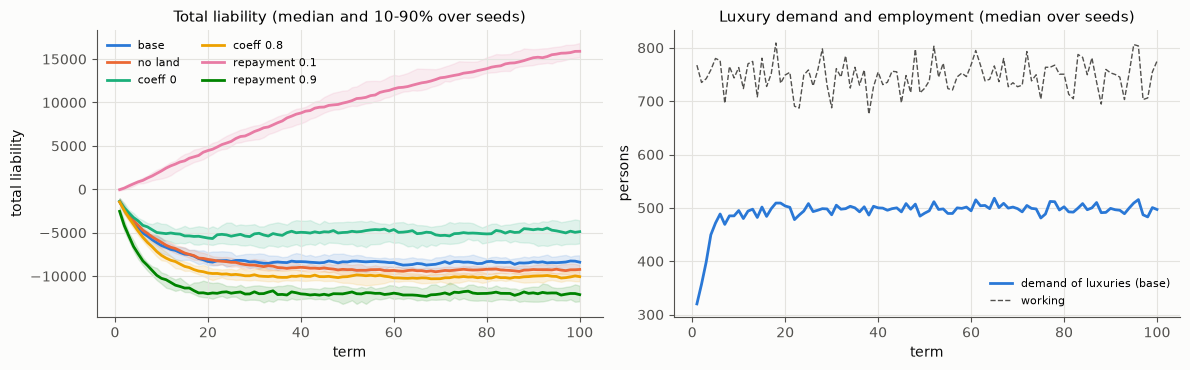

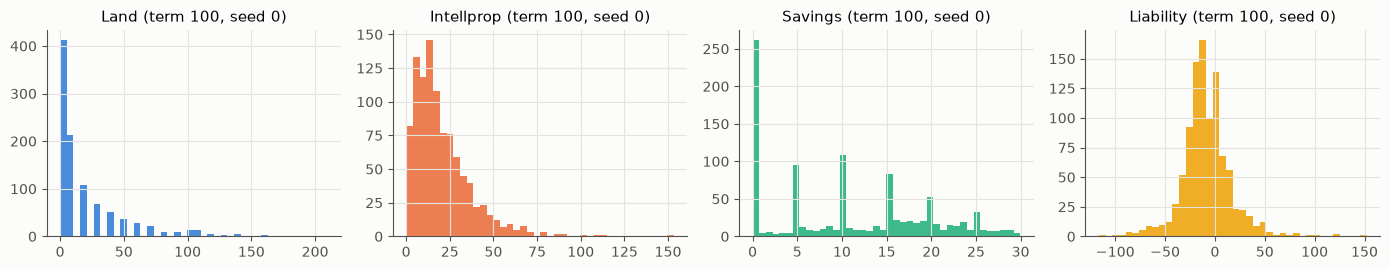

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
t = np.arange(1, 101)
for j, k in enumerate(EXP):
    if k == '知財の切り下げなし':
        continue
    L = np.array([r['L'] for r in RES[k]])
    lab = {'基本(知財の切り下げあり)': 'base', '土地の取引なし': 'no land', '売りやすさの傾斜 0': 'coeff 0', '売りやすさの傾斜 0.8': 'coeff 0.8',
           '返済率 0.1': 'repayment 0.1', '返済率 0.9': 'repayment 0.9'}[k]
    ax[0].plot(t, np.median(L, 0), color=PAL[j], label=lab)
    ax[0].fill_between(t, np.percentile(L, 10, 0), np.percentile(L, 90, 0), color=PAL[j], alpha=0.12)
ax[0].axhline(0, color=INK2, lw=0.6, zorder=0)
ax[0].set(xlabel='term', ylabel='total liability', title='Total liability (median and 10-90% over seeds)'); ax[0].legend(fontsize=8, ncol=2)
Dm = np.array([r['demand'] for r in RES['基本(知財の切り下げあり)']])
ax[1].plot(t, np.median(Dm, 0), color=PAL[0], label='demand of luxuries (base)')
W = np.array([r['working'] for r in RES['基本(知財の切り下げあり)']])
ax[1].plot(t, np.median(W, 0), color=INK2, lw=1, ls='--', label='working')
ax[1].set(xlabel='term', ylabel='persons', title='Luxury demand and employment (median over seeds)'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
F = RES['基本(知財の切り下げあり)'][0]['final']
fig, ax = plt.subplots(1, 4, figsize=(14, 2.8))
for j, (key, lab) in enumerate((('land', 'Land'), ('intellprop', 'Intellprop'), ('savings', 'Savings'), ('liability', 'Liability'))):
    ax[j].hist(F[key], bins=40, color=PAL[j], alpha=0.85)
    ax[j].set(title=f'{lab} (term 100, seed 0)')
plt.tight_layout(); plt.show()

上の左の図: 全 liability は、最初の 20〜30 期で大きく動いたあと、設定ごとに違う水準のまわりで落ち着く(返済率 0.1 の場合だけは、増え続ける)。記事が「フラフラする」と書いたのは、この水準のまわりの揺れである。右の図は、基本の設定での贅沢品の需要と、働く人数である。働く人数は 600〜900 の一様乱数(平均 750)だが、贅沢品の需要は 500 前後にとどまる。

下の図は、基本の設定の 100 期目の分布(乱数の種 0)で、記事の図に相当する。

- **土地**は、指数分布に近い形のまま。
- **知財**は、0 の近くで少し下がる山の形(記事の言う「0 で少し下がる山型」)。
- **貯蓄**は、0 から 30 までのあいだに広がり、0 と 5 の倍数のところにとがりがある(賃金・必需品・贅沢品・返済が、どれも 5 の倍数だからである)。
- **liability** は、0 を中心とした山の形で、0 にとがりがある(借金をちょうど返し終えた人)。

どれも、最初の指数分布や正規分布の形からは変わっている。作者が「定常状態を求めるのは、あまりうまくいっていない」と書いたのは、このことである。これらの形が何であり、なぜそうなるのかは、第 4 章で考える。

次の第 2 章では、このモデルの部品を一つずつ調べる。

## 第 2 章 解剖

第 1 章で、2019 年のモデルが、記事に書かれたとおりに動くことを確かめた。この章では、モデルの部品を一つずつ調べる。

### 2.1 会計: お金はどこから来て、どこへ行くのか

このモデルのお金の流れは、三つの層に分けられる。

1. **資産市場**(土地と知財の売り買い): 買い手の liability が増え、売り手の liability が同じだけ減る。全員の liability の和は変わらない。2011 年のモデルの「現金はマイナスの負債」という書き方が、ここでは保存を保証している。
2. **商品市場**(賃金、必需品、贅沢品): 働く人は賃金 30 を受け取り、必需品 20 と贅沢品 15 を払う。働かない人の必需品は「社会的負債」が払う。賃金の払い手と、商品の売り手は、モデルの中にいない。
3. **二つの市場のあいだ**: 返済(賃金から借金を返す)と、Erosion(貯蓄が足りないとき、現金を取り崩すか、借りる)。

ノート O の第 4 章と同じように、すべての受け払いを仕訳として記録する帳簿を付けてみる。モデルの外にいる相手方を、三つの部門として置く。

- **FIRM**(商品の売り手であり、賃金の払い手。micro_economy の「企業」にあたる)
- **STATE**(失業者の必需品を払う。社会的負債の持ち主)
- **BANK**(プレイヤーの liability の相手。liability がプラスの人には貸し、マイナスの人からは預かっている)

プレイヤーの勘定は、貯蓄(`sav`)、銀行の口座(`bank` = −liability。マイナスなら借金)、土地、知財、正味資産(`eq`)とする。知財の売り買いで、買い手が払った値段より高い評価を積むとき、その差は、買い手の正味資産の増加(評価益)として書く。

書き直しの計算(`sma1.Economy`)に、受け払いのたびに帳簿へ知らせる口(`log`)を付けた。計算そのものは変えていない(第 1 章の一致試験は、口を付けたあとの版で行っている)。基本の設定(その1、知財の切り下げあり、100 期)で帳簿を付ける。

In [12]:
%%writefile anat2.py
"""anat2.py -- 2019 年の資産市場モデルの解剖: 帳簿、雇用の続き方、売り手・買い手の選ばれやすさ。"""
from collections import defaultdict
import numpy as np
import sma1


class Books:
    """sma1.Economy の受け払いを、複式簿記の仕訳として記録する。仕訳は {(主体, 勘定): 金額} で、借方を正、貸方を負で書く。
    主体: プレイヤー(番号)、FIRM(商品の売り手であり賃金の払い手)、STATE(失業者の必需品を払う)、BANK(借金と現金の相手)。
    勘定: sav(貯蓄)、bank(銀行への預け = −liability。マイナスなら借金)、land、ip、eq(正味資産)、cash(FIRM・STATE・BANK の手元のお金)、
    dep(BANK がプレイヤーに負う額 = −Σ bank)。"""
    def __init__(self, e):
        self.bal = defaultdict(float)
        self.n, self.max_gap = 0, 0.0
        self.flow = defaultdict(float)          # その期の流れの合計
        for x in e.players:                     # 開始の仕訳
            self.post({(x.num, 'sav'): x.savings, (x.num, 'land'): x.land, (x.num, 'ip'): x.intellprop,
                       (x.num, 'eq'): -(x.savings + x.land + x.intellprop)})
            self.post({(x.num, 'bank'): -x.liability, (x.num, 'eq'): x.liability,
                       ('BANK', 'dep'): x.liability, ('BANK', 'eq'): -x.liability})
        e.log = self.log

    def post(self, entry):
        if isinstance(entry, list):             # 同じ勘定が二度出てくる仕訳(自分から買う取引など)は、足し合わせる
            d = defaultdict(float)
            for k, v in entry:
                d[k] += v
            entry = {k: v for k, v in d.items() if v != 0.0} or {('BANK', 'eq'): 0.0}
        gap = 0.0
        for v in entry.values():
            gap += v
        self.max_gap = max(self.max_gap, abs(gap) / max(1.0, max(abs(v) for v in entry.values())))
        for k, v in entry.items():
            self.bal[k] += v
        self.n += 1

    def log(self, kind, *a):
        f = self.flow
        if kind == 'land':
            b, s, u = a
            f['self_trade'] += u if b is s else 0.0
            self.post([((b.num, 'land'), u), ((b.num, 'bank'), -u), ((s.num, 'land'), -u), ((s.num, 'bank'), u)])
            f['land_trade'] += u
        elif kind == 'ip':
            b, s, p, v = a
            f['self_trade'] += p if b is s else 0.0
            self.post([((b.num, 'ip'), v), ((b.num, 'bank'), -p), ((s.num, 'bank'), p), ((s.num, 'eq'), -p), ((b.num, 'eq'), -(v - p))])
            f['ip_trade'] += p; f['ip_created'] += v
        elif kind == 'work':
            x, w, n, l = a
            for amt, k, sgn in ((w, 'wages', 1), (n, 'necessaries', -1), (l, 'luxuries', -1)):
                if amt:
                    self.post({(x.num, 'sav'): sgn * amt, (x.num, 'eq'): -sgn * amt, ('FIRM', 'cash'): -sgn * amt, ('FIRM', 'eq'): sgn * amt})
                    f[k] += amt
        elif kind == 'dole':
            x, n = a
            self.post({('STATE', 'cash'): -n, ('STATE', 'eq'): n, ('FIRM', 'cash'): n, ('FIRM', 'eq'): -n})
            f['dole'] += n
        elif kind == 'repay':
            x, r = a
            self.post({(x.num, 'sav'): -r, (x.num, 'bank'): r, ('BANK', 'cash'): r, ('BANK', 'dep'): -r})
            f['repay'] += r
        elif kind == 'erosion':
            x, e_ = a
            self.post({(x.num, 'sav'): e_, (x.num, 'bank'): -e_, ('BANK', 'cash'): -e_, ('BANK', 'dep'): e_})
            f['erosion'] += e_
        elif kind == 'ip_deval':
            x, loss = a
            self.post({(x.num, 'ip'): -loss, (x.num, 'eq'): loss})
            f['ip_deval'] += loss
        elif kind == 'liab_deval':
            x, d = a
            self.post({(x.num, 'bank'): d, (x.num, 'eq'): -d, ('BANK', 'dep'): -d, ('BANK', 'eq'): d})
            f['liab_deval'] += d

    def sector(self):
        """主体を、プレイヤー全員 / FIRM / STATE / BANK にまとめた残高。"""
        out = defaultdict(float)
        for (a, k), v in self.bal.items():
            out[('PLAYERS' if isinstance(a, int) else a, k)] += v
        return dict(out)


def booked(a):
    """(seed, オプションの dict) → 帳簿を付けて走らせた結果: 元の計算と同じか、仕訳の数と貸借のずれの最大、
    帳簿の値がプレイヤーの値と一致するか、期ごとの流れ、最後の主体ごとの残高。"""
    seed, kw = a
    P = sma1.params(**kw)
    e = sma1.Economy(P, seed); e.initialize()
    bk = Books(e)
    ref, _ = sma1.simulate(seed, **kw)
    same, flows = True, []
    for t in range(P.trials):
        bk.flow = defaultdict(float)
        rep = e.step()
        same &= rep['total'] == ref[t]['total']
        flows.append(dict(bk.flow))
    ok = all(abs(bk.bal[(x.num, 'sav')] - x.savings) < 1e-6 and abs(-bk.bal[(x.num, 'bank')] - x.liability) < 1e-6
             and abs(bk.bal[(x.num, 'land')] - x.land) < 1e-6 and abs(bk.bal[(x.num, 'ip')] - x.intellprop) < 1e-6 for x in e.players)
    return dict(same=same, read_ok=ok, n=bk.n, max_gap=bk.max_gap, flows=flows, sector=bk.sector(),
                social_debt=e.social_debt, L=sum(x.liability for x in e.players))

Overwriting anat2.py


In [13]:
import anat2
importlib.reload(anat2)
BK = pmap(anat2.booked, [(s, dict(sma1.V01, trials=100, devaluation_of_intellprop=True)) for s in range(4 if FAST else 8)])
print(f'帳簿を付けても計算が同じ: {sum(b["same"] for b in BK)}/{len(BK)}、帳簿の値がプレイヤーの値と一致: {sum(b["read_ok"] for b in BK)}/{len(BK)}')
print(f'仕訳の数(一回あたり): {np.mean([b["n"] for b in BK]):.0f}、仕訳の貸借のずれの最大: {max(b["max_gap"] for b in BK):.1e}')
b = BK[0]
print('\n100 期目の残高(乱数の種 0。借方が正、貸方が負):')
name = {'sav': '貯蓄', 'bank': '銀行の口座(−liability)', 'land': '土地', 'ip': '知財', 'eq': '正味資産', 'cash': '手元のお金', 'dep': 'プレイヤーへの負い'}
for sec in ('PLAYERS', 'BANK', 'FIRM', 'STATE'):
    for (s_, k), v in sorted(b['sector'].items()):
        if s_ == sec and abs(v) > 1e-6:
            print(f'  {sec:8s} {name[k]:22s} {v:12.1f}')
print(f'  すべての残高の和: {sum(b["sector"].values()):.1e}   (全 liability {b["L"]:.1f}、社会的負債 {b["social_debt"]:.0f})')

帳簿を付けても計算が同じ: 8/8、帳簿の値がプレイヤーの値と一致: 8/8
仕訳の数(一回あたり): 409895、仕訳の貸借のずれの最大: 0.0e+00

100 期目の残高(乱数の種 0。借方が正、貸方が負):
  PLAYERS  銀行の口座(−liability)            8346.1
  PLAYERS  正味資産                       -59704.3
  PLAYERS  知財                          20504.5
  PLAYERS  土地                          20140.0
  PLAYERS  貯蓄                          10713.7
  BANK     手元のお金                        8346.1
  BANK     プレイヤーへの負い                   -8346.1
  FIRM     手元のお金                      501740.0
  FIRM     正味資産                      -501740.0
  STATE    手元のお金                     -510580.0
  STATE    正味資産                       510580.0
  すべての残高の和: 1.2e-10   (全 liability -8346.1、社会的負債 510580)


帳簿は閉じる。どの仕訳も貸借が一致し、帳簿の値は、全員の貯蓄・liability・土地・知財と一致する。ここから、三つのことが読み取れる。

- **BANK は、ただの仲介役である。** BANK の手元のお金は、ちょうど −(全 liability) に等しい。全 liability が −8346 なら、BANK はプレイヤーに 8346 を負い、手元に 8346 を持っている。全 liability が最初の 0 から −8346 に下がったのは、それまでの返済の合計が Erosion の合計を 8346 上回ったからである。資産市場の売り買いは全 liability を動かさないので、

$$
\Delta(\text{全 liability}) = \text{Erosion} - \text{返済}
$$

がいつも成り立つ。全 liability が落ち着くことと、Erosion と返済が釣り合うことは、同じことである。

- **FIRM は、毎期、STATE の払う失業手当の分だけ黒字になり、その黒字をどこにも使わない。** FIRM の手元のお金は 50 万を超え、STATE は同じだけ赤字(社会的負債)を積む。作者が 2022 年の「ひとこと」で「micro_economy において、商品市場の現金バランスをチェックするのをしていなかった」と書いたのは、このことにあたる。ノート 1 で、micro_economy の社会的負債が政府部門の赤字だったのと同じ形が、ここにもある。
- **プレイヤーの貯蓄は落ち着いている。** 50 期以降、プレイヤー全体の貯蓄はほとんど増えも減りもしない。

最後の点を、期ごとの流れで確かめる。51〜100 期の平均である。

In [14]:
F = [f for b in BK for f in b['flows'][50:]]
mean = lambda k: np.mean([f.get(k, 0.0) for f in F])
rows = [('賃金(FIRM → 働く人)', 'wages'), ('必需品(働く人 → FIRM)', 'necessaries'), ('失業手当(STATE → FIRM)', 'dole'),
        ('贅沢品(プレイヤー → FIRM)', 'luxuries'), ('返済(プレイヤー → BANK)', 'repay'), ('Erosion(BANK → プレイヤー)', 'erosion'),
        ('土地の売り買いの額', 'land_trade'), ('知財の売り買いの額', 'ip_trade'), ('知財の評価額(積まれた額)', 'ip_created'),
        ('知財の切り下げ', 'ip_deval'), ('自分から買った額', 'self_trade')]
print('一期あたりの流れ(51〜100 期の平均、乱数の種 8 通り)')
for lab, k in rows:
    print(f'  {lab:28s} {mean(k):9.1f}')
print(f'\n  賃金 − 必需品 = {mean("wages") - mean("necessaries"):.1f}、贅沢品 + 返済 − Erosion = {mean("luxuries") + mean("repay") - mean("erosion"):.1f}')
print(f'  FIRM の黒字 = 必需品 + 失業手当 + 贅沢品 − 賃金 = {mean("necessaries") + mean("dole") + mean("luxuries") - mean("wages"):.1f}')

一期あたりの流れ(51〜100 期の平均、乱数の種 8 通り)
  賃金(FIRM → 働く人)                 22242.2
  必需品(働く人 → FIRM)                14828.1
  失業手当(STATE → FIRM)              5171.9
  贅沢品(プレイヤー → FIRM)               7418.3
  返済(プレイヤー → BANK)                 919.9
  Erosion(BANK → プレイヤー)            923.6
  土地の売り買いの額                       1749.2
  知財の売り買いの額                       4692.0
  知財の評価額(積まれた額)                   5768.4
  知財の切り下げ                         5768.4
  自分から買った額                           5.9

  賃金 − 必需品 = 7414.1、贅沢品 + 返済 − Erosion = 7414.6
  FIRM の黒字 = 必需品 + 失業手当 + 贅沢品 − 賃金 = 5176.1


- プレイヤーの商品市場での収支は、ほぼ釣り合っている。賃金から必需品を引いた額(約 7410)が、贅沢品と返済から Erosion を引いた額にほぼ等しい。**贅沢品に使われる額は、働く人の「賃金 − 必需品」の合計で決まっている。** 第 1 章で、贅沢品の需要が、どの設定でもほぼ 500 人だったのは、このためである。一人 15 の贅沢品を、合計約 7500 で買えば、ちょうど 500 人分になる。このことは、第 3 章で詳しく扱う。
- 返済と Erosion は、どちらも約 920 で釣り合っている。
- FIRM の黒字は、失業手当の額(約 5170)に等しい。

### 2.2 値段の決め方

#### 土地には値段がない

土地は、いつも一単位 10 を値段 10 で売り買いする。値段は変わらない。だから、土地を買うことは、銀行の口座の 10 を土地の 10 に替えることにすぎず、土地を持つ人の正味資産は、土地を買っても売っても変わらない。この意味で、**このモデルの土地は、利子のつかない預金と同じもの**である。作者は「土地は減価しないかわりに増価しない」と書いた。

それでも土地は、知財の値段に効く。知財を売るときの値段の上限は、「売り手の知財 + $a \log(1 + \text{土地})$」($a = 10 / \log 11$、土地 10 で上限が 10 増える)である。土地を持つ人は、知財を高く売れる。作者が言う「土地があれば、知財がなくても高めに知財を生産できる」である。

土地の値段が動かないことは、第 5・6 章で大事になる。土地の値段が上がって、それを担保に借りられる額が増える、という仕組みが、このモデルにはない。

#### 知財は、買った瞬間に増える

知財の値段は、0 から「売り手の知財 + 土地の効き目」までの一様乱数で決まる。買い手は、払った値段より高い評価額(値段から「値段 + $\sqrt{0.25 \times \text{値段} \times \text{買い手の知財}}$」までの一様乱数)を、自分の知財に積む。売り手の知財は減らない。

つまり、**知財の売り買いのたびに、評価額の分だけ、経済全体の知財が増える**。上の表のとおり、一期に約 5800 の知財が積まれ、それと同じ額が切り下げで消される。切り下げの前の知財の総額は 26000 前後なので、一期に約 2 割が切り下げで消えていることになる。

これは、ノート O の第 4 章で見た「自分で付けた値段で、自分の資産が増える」と同じ形の、**評価による資産の創出**である。作者は「知的資産は、一度発見すると、それを何度でも売れる」ことを、売っても減らないことで表した。そして、増えすぎないように、総額を毎期もとに戻した。切り下げの意味は、第 5 章で考える。

なお、上の表の「自分から買った額」のとおり、買い手と売り手が同じ人になる取引もわずかにある(一期あたりの額で 6 ほど、件数にして 1 件に満たない)。

#### 贅沢品を買う条件は、手元のお金だけで決まる

贅沢品を買う条件は、元のコードでは二段になっている(作者が micro_economy から持ってきた規則)。働く人の場合、手元のお金(貯蓄 + 現金)に「賃金 − 必需品 − 返済」を足したものを $c$ とし、基準額を「賃金 − 必需品」の 3 倍(= 30)とすると、

1. $c \geq 30$、かつ
2. $(c - 30)/3 + 30 \geq$ 贅沢品の値段(15)。

ところが、1 が成り立てば、2 の左辺は 30 以上なので、贅沢品の値段が 30 以下である限り、2 はいつも成り立つ。今の値段では、**条件は $c \geq 30$ の一つだけ**である。贅沢品の値段が、買うかどうかの判断に直接効くのは、値段が基準額 30 を超えたときだけである。値段は、買ったあとの貯蓄の減り方を通じてだけ効く。

### 2.3 誰が売り、誰が買うか

#### 傾斜のついた選び方

作者の言う「**傾斜**」(coeff)とは、**並べた順位によって、選ばれやすさがどれだけ違うか**の度合いである。傾斜が 0 なら、順位によらず、誰もが同じ確率で選ばれる(くじ)。傾斜が大きいほど、並べた順の後ろの人(たとえば「借金の多さ」で並べたなら、借金の多い人)が選ばれやすくなる。作者は、「土地を売るのは借金のある人に偏る」「知財を買うのは才能の問題なので、借金の多さにはあまり偏らない」といった、選ばれ方の偏りの強さを、この一つの数で表した。

1.1 で述べたとおり、売り手と買い手は、ある基準で並べた順位 $i$ に、0 から $(a/1000)\,i + 1$ までの一様乱数を振り、その大きい順に 300 人を取って選ぶ。順位ごとの選ばれる確率を計算する。

この確率は、簡単な式で近似できる。300 人目の乱数の値を $c$ とすると、順位 $i$ の人の乱数が $c$ を超える確率は、$w_i = (a/1000)\,i + 1$ として $\max(0,\, 1 - c / w_i)$ である。$c$ は、この確率の和がちょうど 300 になるように決まる。

In [15]:
%%writefile -a anat2.py
def pick_prob(a):
    """(傾斜 coeff, 試行の回数, seed) → 順位 i(0〜999)の人が、上位 300 人に選ばれる確率。
    元のコードと同じく、i 番目の人に 0〜(coeff/1000)·i + 1 の一様乱数を振り、大きい順に 300 人を取る。"""
    coeff, trials, seed = a
    rng = np.random.default_rng(seed)
    N, top = 1000, 300
    hit = np.zeros(N)
    width = coeff / N * np.arange(N) + 1
    for _ in range(trials):
        u = rng.uniform(0, width)
        hit[np.argpartition(-u, top)[:top]] += 1
    return hit / trials

Appending to anat2.py


傾斜 0.0: 順位 0・500・999 の人が選ばれる確率  シミュレーション 0.295 / 0.297 / 0.303、近似の式 0.300 / 0.300 / 0.300


傾斜 0.3: 順位 0・500・999 の人が選ばれる確率  シミュレーション 0.197 / 0.301 / 0.386、近似の式 0.200 / 0.304 / 0.384


傾斜 0.8: 順位 0・500・999 の人が選ばれる確率  シミュレーション 0.044 / 0.317 / 0.475、近似の式 0.048 / 0.320 / 0.471


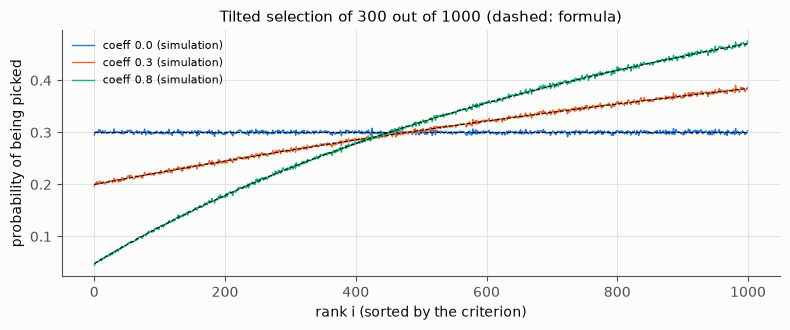

元の実験スクリプト exp_01_01.py(1000 回、乱数の種 0): {'0.3': '0.201 0.311 0.389', '0.8': '0.046 0.327 0.491'}


In [16]:
from scipy.optimize import brentq
importlib.reload(anat2)
fig, ax = plt.subplots(figsize=(8, 3.4))
ii = np.arange(1000)
for j, a in enumerate((0.0, 0.3, 0.8)):
    p = np.mean(pmap(anat2.pick_prob, [(a, 1000 if FAST else 4000, s) for s in range(8)]), 0)
    w = a / 1000 * ii + 1
    c = brentq(lambda c: np.clip(1 - c / w, 0, None).sum() - 300, 0, w.max())
    ax.plot(ii, p, color=PAL[j], lw=1, label=f'coeff {a} (simulation)')
    ax.plot(ii, np.clip(1 - c / w, 0, None), color=INK, ls='--', lw=0.8)
    print(f'傾斜 {a}: 順位 0・500・999 の人が選ばれる確率  シミュレーション {p[0]:.3f} / {p[500]:.3f} / {p[999]:.3f}、近似の式 {1 - c / w[0]:.3f} / {1 - c / w[500]:.3f} / {1 - c / w[999]:.3f}')
ax.set(xlabel='rank i (sorted by the criterion)', ylabel='probability of being picked', title='Tilted selection of 300 out of 1000 (dashed: formula)')
ax.legend(fontsize=8); plt.tight_layout(); plt.show()
out = {a: sma1_orig.run_raw('exp_01_01.py', 0, [f'--a={a}']).strip() for a in ('0.3', '0.8')}
print('元の実験スクリプト exp_01_01.py(1000 回、乱数の種 0):', out)

近似の式(黒い点線)は、シミュレーションとよく合う。傾斜 0.3 では、順位の最下位の人も 2 割、最上位の人も 4 割で、差は 2 倍しかない。傾斜 0.8 にすると、最下位は 5%、最上位は 5 割に開く。作者が「0.3 だとそれほど有利にならず、0.8 だとはっきり有利になる」と書いたとおりである。

ただし、作者がその1 の記事に載せた数値(傾斜 0.3 で 0.19 / 0.304 / 0.359、傾斜 0.8 で 0.061 / 0.313 / 0.457)とは、少しずれる。元の実験スクリプトをそのまま走らせても、上のとおり、こちらの計算と同じ値になる。記事の数値は、別の版か別の設定で出したものかもしれない。いずれにせよ、傾斜 0.3 と 0.8 の違いの大きさについての作者の読みは、変わらない。

もう一つ、作者が注意していたように、この選び方は**順位**だけを見る。借金が 10 の人と 1000 の人でも、順位が隣どうしなら、ほとんど同じ確率で選ばれる。

#### 働く人は、働き続けやすい

1.1 で、働く人は「前の期に働いた人が先に選ばれる」と書いた。元のコードは、期の終わりに、働いた人を前に、働かなかった人を後ろに並べ直す。次の期は、その並びの先頭から、600〜900 の乱数の人数が働く。だから、働く人数が前の期より増えれば、前の期に働いた人は全員また働き、失業していた人の一部が新たに働く。減れば、前の期に働いた人の一部だけが失業する。失業は、いったん始まると続きやすい。

In [17]:
%%writefile -a anat2.py
def employment(a):
    """(seed, オプションの dict) → 失業していた人が次の期にも失業している割合、働いていた人が次の期に失業する割合、
    失業の続く期間の平均、一度も失業しなかった人の割合。"""
    seed, kw = a
    P = sma1.params(**kw)
    e = sma1.Economy(P, seed); e.initialize()
    W = []
    for t in range(P.trials):
        e.step()
        w = np.zeros(P.population, bool)
        for x in e.players:
            w[x.num] = x.working
        W.append(w)
    W = np.array(W)
    uu = (~W[:-1] & ~W[1:]).sum() / max(1, (~W[:-1]).sum())
    wu = (W[:-1] & ~W[1:]).sum() / max(1, W[:-1].sum())
    spells = []
    for i in range(P.population):
        run = 0
        for t in range(len(W)):
            if not W[t, i]:
                run += 1
            elif run:
                spells.append(run); run = 0
        if run:
            spells.append(run)
    return uu, wu, (np.mean(spells) if spells else 0.0), W.all(0).mean()

Appending to anat2.py


In [18]:
importlib.reload(anat2)
EM = np.array(pmap(anat2.employment, [(s, dict(sma1.V01, trials=100, devaluation_of_intellprop=True)) for s in range(8)]))
uu, wu, spell, never = EM.mean(0)
print(f'失業していた人が、次の期も失業している割合: {uu:.2f}')
print(f'働いていた人が、次の期に失業する割合: {wu:.3f}')
print(f'失業が続く期間の平均: {spell:.1f} 期、100 期のあいだ一度も失業しなかった人の割合: {never:.3f}')

失業していた人が、次の期も失業している割合: 0.80
働いていた人が、次の期に失業する割合: 0.068
失業が続く期間の平均: 4.8 期、100 期のあいだ一度も失業しなかった人の割合: 0.001


失業していた人の 8 割は、次の期も失業している。失業が続く期間は、平均で 5 期近くになる。一方、働いていた人が失業するのは、一期あたり 7% ほどである。100 期のあいだに、ほとんど全員が、一度は失業を経験する。

失業していると、賃金がなく、手元のお金が 30 以上なければ贅沢品も買えない。失業が続きやすいことは、誰が贅沢品を買えなくなるか(作者がその2 で「Luxuries Min」として気にしていたこと)に効いているはずである。作者は、その1 の結論で「資産があるほうが失業する可能性が高いということを、システムに組み込むべきではないか」とも書いていた。今のモデルでは、誰が失業するかは、資産と無関係である。

### 2.4 その2 の「現実的」モデルたち

その2 の記事で、作者は、値段の決め方の性質から「現実的」な売り手と買い手の選び方を考え、モデルを四段階で「進化」させた。

| | 知財の買い手 | 知財の売り手 | 土地の買い手 | 土地の売り手 | 考え方 |
|---|---|---|---|---|---|
| その1 相当 | 現金のある人(0.3) | 借金のある人(0.3) | 現金のある人(0.8) | 借金のある人(0.8) | 借金のある人ほど売り、現金のある人ほど買う |
| 第一 | 知財の多い人(0.3) | 知財の多い人(0.8) | 現金のある人(0.8) | 土地の多い人(0.3) | 知財を多く持つ人の知財は高く評価されるので、強く求められる |
| 第二 | 知財の多い人(0.8) | 知財の多い人(0.8) | 現金のある人(0.8) | 土地の多い人(0.3) | 知財を買うのは、価値を保つために買い増す人 |
| 第三 | 知財の多い人(0.8) | 知財の多い人(0.8) | 現金のある人(0.3) | 土地の多い人(0.8) | 土地を持たない人も、逆転のために土地を買おうとする |
| 第四 | 借金のある人(0.8) | 知財の多い人(0.8) | 現金のある人(0.3) | 土地の多い人(0.8) | 知財を買うのは、手元の現金が欲しい借金持ち。資産を売った代金でその期に贅沢品を買える |

(かっこの中は傾斜。第四だけ、資産を売った代金を、その期の手元のお金に数える `cash_on_hand='loose'`。)

その2 の版の既定値は、第四「現実的」モデルになっている。作者は、逆転のしやすさを Rank Change Mean(各人の、これまでの純資産の順位の最大と最小の差の平均)で測った。四つのモデルを、乱数の種 20 通りで 50 期走らせる。

In [19]:
base = dict(devaluation_of_intellprop=True, asset_rank='net', cash_on_hand='rigid', trials=50,
            sort_of_intellprop_seller='ascend', sort_of_land_buyer='cash', sort_of_land_seller='land', coeff_of_intellprop_seller=0.8)
MODELS = {
    'その1 相当': (dict(sma1.V01, devaluation_of_intellprop=True, trials=50), None),
    '第一「現実的」': (dict(base, sort_of_intellprop_buyer='ascend', coeff_of_intellprop_buyer=0.3, coeff_of_land_buyer=0.8, coeff_of_land_seller=0.3), 656.367),
    '第二「現実的」': (dict(base, sort_of_intellprop_buyer='ascend', coeff_of_intellprop_buyer=0.8, coeff_of_land_buyer=0.8, coeff_of_land_seller=0.3), 669.082),
    '第三「現実的」': (dict(base, sort_of_intellprop_buyer='ascend', coeff_of_intellprop_buyer=0.8, coeff_of_land_buyer=0.3, coeff_of_land_seller=0.8), 713.207),
    '第四「現実的」': (dict(base, cash_on_hand='loose', sort_of_intellprop_buyer='liability', coeff_of_intellprop_buyer=0.8,
                       coeff_of_land_buyer=0.3, coeff_of_land_seller=0.8), 735.212),
}
print('モデル            Rank Change Mean(50 期目): 平均 [範囲]   記事     全 liability(31〜50 期)  最大の借金  贅沢品の最少  需要')
MR = {}
for k, (kw, art) in MODELS.items():
    R = pmap(sma1.summary, [(s, kw) for s in range(n_seed)]); MR[k] = R
    g = lambda key: np.array([r[key] for r in R])
    rk = g('rank')[:, -1]
    print(f'{k:14s}   {rk.mean():6.1f} [{rk.min():.0f}, {rk.max():.0f}]   {("%.1f" % art) if art else "  ― ":>6s}   {g("L")[:, 30:].mean():10.0f}            {g("maxL")[:, -1].mean():6.0f}      {g("lux_min")[:, -1].mean():5.1f}     {g("demand")[:, 30:].mean():4.0f}')
print('第四「現実的」とその2 の既定値が同じ計算か:', sma1.summary((0, MODELS['第四「現実的」'][0]))['L'].tolist() == sma1.summary((0, dict(devaluation_of_intellprop=True, trials=50)))['L'].tolist())

モデル            Rank Change Mean(50 期目): 平均 [範囲]   記事     全 liability(31〜50 期)  最大の借金  贅沢品の最少  需要


その1 相当            661.1 [640, 676]       ―         -8329               118        3.4      497


第一「現実的」           665.6 [643, 679]    656.4        -5418               233        3.0      498


第二「現実的」           658.5 [645, 678]    669.1        -5157               255        3.0      499


第三「現実的」           706.7 [692, 721]    713.2        -4429               241        3.3      499


第四「現実的」           733.1 [710, 756]    735.2         2236               272        6.4      504


第四「現実的」とその2 の既定値が同じ計算か: True


記事の Rank Change Mean(一回ずつの実行)は、どれも、乱数の種 20 通りの範囲の中にある。作者の観察は、乱数のたまたまではなかった。

- 第三「現実的」モデルで、Rank Change Mean がはっきり上がる(660 前後から 707 へ)。土地を持たない人も土地を買おうとし、土地の多い人が売るようにしたことで、順位が入れ替わりやすくなった。作者が「貧しい者の抵抗をある程度、組み入れたからであろう」と書いたとおりである。
- 第四「現実的」モデルで、贅沢品を一番少なくしか買えなかった人の数(50 期の合計)が、3 個から 6 個に倍増する。資産を売った代金で、その期に贅沢品を買えるようにしたからである。作者は、失業者の消費の機会を増やそうとして、この変更を入れた。
- 全 liability の水準は、モデルによって大きく違う(第四では、借金のほうが多くなる)。それでも、**贅沢品の需要は、どのモデルでも 500 前後で変わらない**。2.1 で見たとおり、贅沢品に使われる額は、働く人の「賃金 − 必需品」の合計で決まっているからである。

作者は、その2 の結論で、「一つの指針を決めて、それで人工知能なり遺伝的アルゴリズムなりで経済が自動的に構成されたならまだしも、今回は、曖昧な基準で『中庸』の結果を出したに過ぎない」と書いた。ノート O の 2.5 で見たとおり、何を良しとするか(利得)を決めて戦略を対戦させる、という道は、ここでも開いている。各人が、自分の得になるように売り買いの相手を選ぶとしたら、どの「現実的」モデルに行き着くのか。これは、残る問いとして第 8 章に回す。

### 2.5 2011 年のモデルから失われたもの

作者は、公開した日の「ひとこと」で、2011 年のモデルから失われたものを挙げていた。

- **入れ子の構造とカタストロフィックな遷移**: ノート O で、正面から扱った。このモデルの知財の切り下げ(毎期、総額をもとに戻す)は、ノート O の言葉で言えば、遷移ではなく、なめらかな減耗である。第 5 章で、この二つを並べる。
- **greed**: 2011 年のモデルでは、借金の多い人は必需品の値を上げようとした。借金そのものに罰がなくても、借金が社会に悪い影響を及ぼすので、借金を増やさない方向へのインセンティブを付けるつもりだった。2019 年のモデルでは、値段が固定なので、これは消えた。
- **ベーシックインカム論の影響**: 2011 年のモデルでは、働くのはランダムに選ばれた者だけだった。2019 年のモデルでは、働くのが基本になったが、借金がかなり自由にできる点は残った。

作者は、その 2 の公開後の追記で、もう一つ書いている。知財の多さで売り手や買い手を選ぶのは、「借金を多くしたほうが有利にする」という初期の考え方に反していた、と。その1 は、借金のある人ほど資産を売りやすく、現金のある人ほど買いやすくしていた。その2 で、知財の多い人ほど売りやすくしたことで、この考え方は薄れた。第四「現実的」モデルで、知財の買い手を「借金のある人」に戻したのは、この考え方への、半ば無意識の回帰とも読める。

次の第 3 章では、作者が「手にあまる」とした問い、全 liability がどこで落ち着くのかに、式で答える。

## 第 3 章 借金はなぜ際限なく増えないのか

作者は、その1 の記事の結論に、次のように書いた。

> 全 Erosion と全返済はバランスする。おそらくそれは「平均への回帰」があるためである。そのためには返済率が一定以上は必要なようである。(…)今後の課題としては、全 Erosion と全返済のバランスの理由をハッキリさせ、それがどういう額でバランスするかも示せればカッコイイが、それは私には手があまる問題のように思う。

その2 の記事では、さらに二つの謎を残した。返済率を変えても贅沢品の需要がほとんど変わらないこと。そして、30 期目に手元の借り入れの余地を増やす「金融政策」の効果は一時的で、贅沢品の値段を変える「消費税」の効果は続くこと。

この章では、これらに答える。答えの鍵は、二つの恒等式である。

### 3.1 二つの恒等式

第 2 章の帳簿から、次の二つの式が、毎期、厳密に成り立つ。

**一つ目: 全 liability の変化 = Erosion − 返済。** 資産市場の売り買いは、買い手の liability を増やし、売り手の liability を同じだけ減らすので、全 liability を動かさない。全 liability を動かすのは、商品市場との境の二つの流れだけである。

**二つ目: プレイヤー全体の正味の金融資産の変化 = (賃金 − 必需品)× 働く人数 − 贅沢品の値段 × 贅沢品の需要。** プレイヤー全体の正味の金融資産を $A$ = 全貯蓄 − 全 liability とする。返済は貯蓄を減らして liability を減らすので $A$ を変えず、Erosion も貯蓄を増やして liability を増やすので $A$ を変えない。資産市場の売り買いも、全 liability と全貯蓄を変えない。$A$ を動かすのは、働く人が受け取る「賃金 − 必需品」(一人 10)と、贅沢品に払うお金(一つ 15)だけである。

$$
\Delta A_t = 10\,W_t - 15\,D_t
$$

($W_t$ は働く人数、$D_t$ は贅沢品の需要)。シミュレーションで確かめる。

In [20]:
%%writefile stockflow.py
"""stockflow.py -- 全 liability はどこで落ち着くのか: 留め置きの実験、ショックからの戻り、利子を付けた版。"""
import numpy as np
import sma1


def run_clamp(a):
    """(seed, オプション, 留め置く全 liability L_target, 期数) → 毎期の終わりに、全員の liability に同じ額を足して、
    全 liability を L_target に戻し続けたときの、後半の期の Erosion と返済の平均、借金のある人数の平均。
    (全 liability の水準を外から決めて、そのときの二つの流れを測る。流れが釣り合う水準が、自由に走らせたときの落ち着き先になるはず。)"""
    seed, kw, Lt, T = a
    P = sma1.params(**dict(kw, trials=T))
    e = sma1.Economy(P, seed); e.initialize()
    N = len(e.players)
    E, R, nd = [], [], []
    for t in range(T):
        rep = e.step()
        L = 0.0
        for x in e.players:
            L += x.liability
        d = (Lt - L) / N
        for x in e.players:
            x.liability += d
        if t >= T // 2:
            E.append(rep['erosion']); R.append(rep['repay']); nd.append(rep['num_plus'])
    return np.mean(E), np.mean(R), np.mean(nd)

Overwriting stockflow.py


In [21]:
%%writefile -a stockflow.py
def run_shock(a):
    """(seed, オプション, ショックの期, ショックの大きさ s, 期数) → 全 liability の経路。ショックの期の終わりに、
    全員の liability に s/人数 を足す(全 liability が s だけ動く)。"""
    seed, kw, t0, s, T = a
    P = sma1.params(**dict(kw, trials=T))
    e = sma1.Economy(P, seed); e.initialize()
    N = len(e.players)
    out = []
    for t in range(T):
        rep = e.step()
        if t == t0:
            for x in e.players:
                x.liability += s / N
        L = 0.0
        for x in e.players:
            L += x.liability
        out.append(L)
    return np.array(out)

Appending to stockflow.py


In [22]:
%%writefile -a stockflow.py
def run_interest(a):
    """(seed, オプション, 利率 r, 現金にも利子を付けるか, 期数) → 毎期のはじめに、借金に利率 r の利子を付けた版
    (cash=True なら、現金にも同じ利率の利子を付ける)。全 liability の経路と、最後の期に「返済しきれない借金」
    (毎期の返済の上限 = (賃金 − 必需品) × 返済率 を、利子が上回る借金。借金 > 上限 / r)を持つ人数を返す。"""
    seed, kw, r, cash, T = a
    P = sma1.params(**dict(kw, trials=T))
    e = sma1.Economy(P, seed); e.initialize()
    cap = (e.wages - e.necessaries * P.needs_of_necessaries) * P.repayment_rate
    out = []
    for t in range(T):
        for x in e.players:
            if x.liability > 0 or cash:
                x.liability *= (1 + r)
        e.step()
        L = 0.0
        for x in e.players:
            L += x.liability
        out.append(L)
    over = sum(1 for x in e.players if r > 0 and x.liability > cap / r)
    return np.array(out), over

Appending to stockflow.py


In [23]:
import stockflow
importlib.reload(stockflow)
reps, e = sma1.simulate(0, **dict(sma1.V01, trials=100, devaluation_of_intellprop=True))
err1, err2 = 0.0, 0.0
for r in reps:
    dL = r['total'][3] - r['prev'][3]
    dA = (r['total'][2] - r['total'][3]) - (r['prev'][2] - r['prev'][3])
    err1 = max(err1, abs(dL - (r['erosion'] - r['repay'])))
    err2 = max(err2, abs(dA - (10 * r['working'] - 15 * r['demand'])))
print(f'一つ目の式のずれの最大: {err1:.1e}、二つ目の式のずれの最大: {err2:.1e}(100 期、乱数の種 0)')

一つ目の式のずれの最大: 2.4e-11、二つ目の式のずれの最大: 2.2e-11(100 期、乱数の種 0)


どちらも、計算機の丸めの誤差の範囲で成り立つ。

### 3.2 贅沢品の需要は、なぜ 500 なのか

二つ目の式を、期について足し合わせると、

$$
A_T - A_0 = \sum_{t=1}^{T} \left( 10\,W_t - 15\,D_t \right)
$$

になる。正味の金融資産 $A$ が、際限なく増えも減りもしない(ある範囲で落ち着く)なら、右辺を $T$ で割ったものは 0 に近づく。つまり、長い目で見れば、

$$
\overline{D} = \frac{(\text{賃金} - \text{必需品}) \times \overline{W}}{\text{贅沢品の値段}} = \frac{10 \times 750}{15} = 500
$$

でなければならない。**贅沢品の需要の平均は、働く人数と値段だけで決まり、返済率にも、売りやすさの傾斜にも、知財の市場にもよらない。** これが、作者の「返済率を変えても、贅沢品の需要がほとんど変わらない」の答えである。

これは、ストック・フロー一貫モデル(第 2 章で触れた、すべての流れとストックに相手方を書くモデル)でよく知られた性質と同じである。**定常状態では、流れ(どれだけ買うか)は所得で決まり、借りる・返す性向は、ストック(誰がどれだけ借りているか、どれだけ持っているか)を変えるだけである**(Godley and Lavoie 2007)。

例外は、$A$ が落ち着かない場合である。知財の切り下げをしない場合には、全 liability が膨らみ続け($A$ が下がり続け)、その分だけ需要が 500 を上回る。逆に言えば、需要が 500 からずれた分から、$A$ の動く速さがわかる。

いろいろな設定で、予想($10 \times \overline{W} / 15$、$\overline{W}$ はその回の働く人数の平均)と、実際の需要を比べる。賃金や贅沢品の値段を、最初から変えた場合も加える。

In [24]:
SET = {
    '基本': dict(),
    '返済率 0.1': dict(repayment_rate=0.1),
    '返済率 0.9': dict(repayment_rate=0.9),
    '売りやすさの傾斜 0': dict(coeff_of_intellprop_buyer=0.0, coeff_of_intellprop_seller=0.0, coeff_of_land_buyer=0.0, coeff_of_land_seller=0.0),
    '第四「現実的」モデル': None,
    '賃金 33': dict(price_of_wages=33.0),
    '贅沢品の値段 12': dict(price_of_luxuries=12.0),
    '知財の切り下げなし': 'nodev',
}
print('設定                     需要(51〜100 期)   予想 (賃金−必需品)×W/値段    A の一期あたりの変化')
for k, kw in SET.items():
    if kw is None:
        kk = dict(MODELS['第四「現実的」'][0], trials=100)
    elif kw == 'nodev':
        kk = dict(sma1.V01, trials=100)
    else:
        kk = dict(sma1.V01, trials=100, devaluation_of_intellprop=True, **kw)
    R = pmap(sma1.summary, [(s, kk) for s in range(n_seed)])
    P = sma1.params(**kk)
    D = np.mean([r['demand'][50:].mean() for r in R]); W = np.mean([r['working'][50:].mean() for r in R])
    pred = (P.price_of_wages - P.price_of_necessaries * P.needs_of_necessaries) * W / P.price_of_luxuries
    A = np.array([r['S'] - r['L'] for r in R])
    dA = np.mean((A[:, -1] - A[:, 49]) / 50)
    print(f'{k:20s}    {D:7.1f}          {pred:7.1f}                    {dA:8.1f}')

設定                     需要(51〜100 期)   予想 (賃金−必需品)×W/値段    A の一期あたりの変化


基本                        499.3            499.6                         3.6


返済率 0.1                   506.3            499.6                      -100.9


返済率 0.9                   499.5            499.6                         1.8


売りやすさの傾斜 0                499.6            499.6                         0.4


第四「現実的」モデル                502.0            499.6                       -36.6


賃金 33                     649.0            649.5                         7.1


贅沢品の値段 12                 624.1            624.5                         4.7


知財の切り下げなし                 588.9            499.6                     -1339.8


- $A$ が落ち着いている設定では、需要は予想とよく合う(差は 1% 以内)。返済率や傾斜を変えても、モデルを変えても、需要は 500 前後のままである。
- 賃金を 33 にすると、一人あたり 13 が残るので、需要は $13 \times 750 / 15 = 650$ に上がる。贅沢品の値段を 12 にすると、$10 \times 750 / 12 = 625$ に上がる。**値段は、需要を動かす**。
- 知財の切り下げをしないと、$A$ は一期あたり約 1300 ずつ下がり続け、需要はその分(約 1300 / 15 ≈ 90)だけ予想を上回る。返済率 0.1 でも、100 期のあいだは $A$ が少しずつ下がっていて、需要は予想をわずかに上回る。

### 3.3 インパクト実験: 一時的な効果と、続く効果

作者は、その2 で、30 期目に設定を変え、40 期目に戻す「インパクト実験」をした。手元の借り入れの余地(cash margin)を 10 増やす(「金融政策」)と、需要は 30 期に一気に 600 を超えたが、39 期には効果がなくなり、40 期に戻すと 400 を割り込み、50 期には回復した。一方、賃金や贅沢品の値段を変える(「消費税」)と、効果は続いた。ただ、賃金を上げると、30 期には逆に需要が下がった。

作者が使った第二「現実的」モデルで、同じ実験をする(乱数の種 20 通りの平均)。賃金と贅沢品の値段の変化の大きさは記事に書かれていないので、±3 とした。点線は、3.2 の式から予想される、30〜39 期の需要の水準である。

cash margin +10       : 29 期   505、30 期   646、31〜39 期の平均   528(予想 500)、40 期   333、41〜45 期   468、51〜60 期   498


repayment rate +0.3   : 29 期   505、30 期   450、31〜39 期の平均   477(予想 500)、40 期   505、41〜45 期   514、51〜60 期   506


wages +3              : 29 期   505、30 期   330、31〜39 期の平均   566(予想 650)、40 期   800、41〜45 期   570、51〜60 期   514


luxury price -3       : 29 期   505、30 期   486、31〜39 期の平均   569(予想 625)、40 期   594、41〜45 期   531、51〜60 期   509


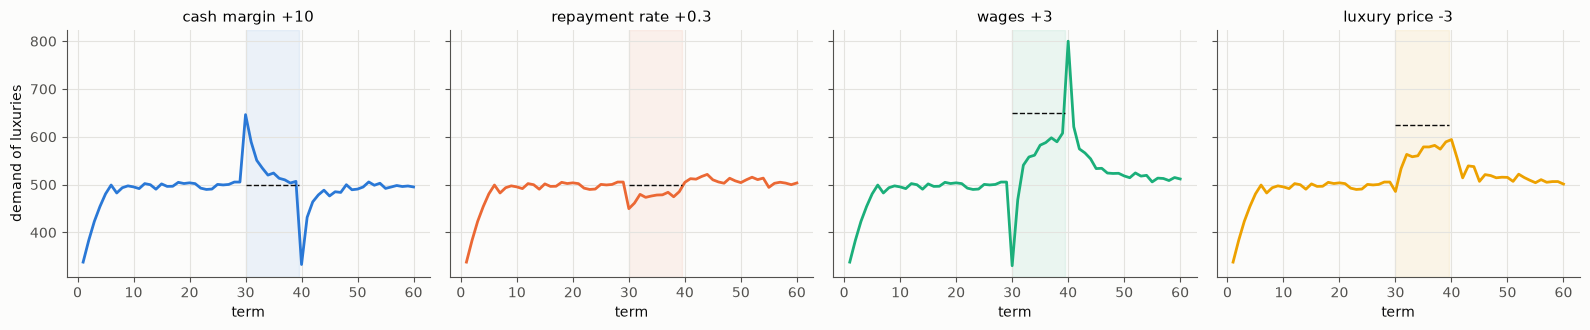

In [25]:
M2 = dict(MODELS['第二「現実的」'][0], trials=60)
IMP = {'cash margin +10': dict(add_cash_margin_30=10.0), 'repayment rate +0.3': dict(add_repayment_rate_30=0.3),
       'wages +3': dict(add_price_of_wages_30=3.0), 'luxury price -3': dict(add_price_of_luxuries_30=-3.0)}
pred = {'cash margin +10': 500, 'repayment rate +0.3': 500, 'wages +3': 13 * 750 / 15, 'luxury price -3': 10 * 750 / 12}
fig, ax = plt.subplots(1, 4, figsize=(16, 3.4), sharey=True)
tt = np.arange(1, 61)
for j, (lab, kw) in enumerate(IMP.items()):
    R = pmap(sma1.summary, [(s, dict(M2, **kw)) for s in range(n_seed)])
    D = np.array([r['demand'] for r in R]).mean(0)
    ax[j].plot(tt, D, color=PAL[j])
    ax[j].axvspan(30, 39.5, color=PAL[j], alpha=0.08)
    ax[j].hlines(pred[lab], 30, 39.5, color=INK, ls='--', lw=1)
    ax[j].axhline(500, color=INK2, lw=0.6, zorder=0)
    ax[j].set(title=lab, xlabel='term')
    print(f'{lab:22s}: 29 期 {D[28]:5.0f}、30 期 {D[29]:5.0f}、31〜39 期の平均 {D[30:39].mean():5.0f}(予想 {pred[lab]:.0f})、40 期 {D[39]:5.0f}、41〜45 期 {D[40:45].mean():5.0f}、51〜60 期 {D[50:].mean():5.0f}')
ax[0].set_ylabel('demand of luxuries')
plt.tight_layout(); plt.show()

作者の観察は、すべて再現される。そして、3.2 の式で説明できる。

- **手元の借り入れの余地(cash margin)**: 余地を増やすと、人々は、正味の金融資産 $A$ を(借りて)下げてまで贅沢品を買える。それは、ストックを一度だけ動かすことで、需要を一時的に押し上げる。$A$ が新しい水準に落ち着けば、需要は 500 に戻る。余地を元に戻すと、今度は $A$ を戻すために、需要が 500 を下回る。**ストックを動かす政策は、動かしているあいだしか効かない。**
- **返済率**: 返済率を上げると、30 期に需要が少し下がり(約 450)、そのあとも 500 をやや下回る。返す額が増えた人の手元(貯蓄)が細り、基準額に届かなくなるからである。40 期に戻すと、逆に 500 をやや上回る。しかし、返済は $A$ を変えない(貯蓄を liability に移すだけ)ので、長い目で見た需要の水準は 500 のままである。返済率は、誰がどれだけ借りているか、誰の手元にどれだけあるかを変えるだけである。
- **賃金**: 賃金を 3 上げると、需要は 650 に向かって上がっていく(10 期のあいだには届かない)。ただ、30 期にはむしろ大きく下がる(約 330)。贅沢品を買う条件の基準額が「(賃金 − 必需品)× 3」なので、賃金を上げると基準額が 30 から 39 に上がり、それまで買えていた人が、一時的に買えなくなるからである(作者の説明のとおり)。40 期に賃金を戻すと、今度は基準額が 30 に下がり、そのあいだに貯まった貯蓄で買える人が一度に増えて、需要は 800 に跳ねる。
- **贅沢品の値段**: 値段を 3 下げると、需要は $10 \times 750 / 12 = 625$ に向かってじわじわ上がる。値段は基準額には効かず、貯蓄の減り方を通じてだけ効くので、「いきなり効くという感じではなくジワジワ効く」(作者)。

作者は、「金融政策は効果が一時的で、消費税の増減が一番効果があり、長期的性質も良い」とまとめたうえで、「これは価格がモデルの外側にあるから言えることで、モデルの内側で価格が決まれば、cash margin や返済率と同じような感じになるのかもしれない」と注意していた。この注意は正しい。3.2 の式で、需要を決めているのは「賃金 − 必需品」と「贅沢品の値段」という、**モデルの外から与えた値段**である。値段がモデルの中で(たとえば、ノート 1 の最適化で)決まるなら、需要の水準は、値段を決める仕組みのほうで決まることになる。

### 3.4 全 liability は、どこで落ち着くのか

二つ目の式が、需要の水準を決めた。では、全 liability の水準を決めるのは何か。一つ目の式から、全 liability が落ち着くのは、Erosion と返済が釣り合うときである。

そこで、次の実験をする。毎期の終わりに、全員の liability に同じ額を足し引きして、全 liability をある値 $L$ に留め置く。そのうえで、Erosion と返済の平均を測る。これで、「全 liability が $L$ のとき、Erosion と返済がそれぞれどれだけになるか」という二つの曲線が得られる。二つの曲線が交わる $L^*$ が、自由に走らせたときの落ち着き先になるはずである。

返済率 0.5(基本)、0.9、0.1 で試す。

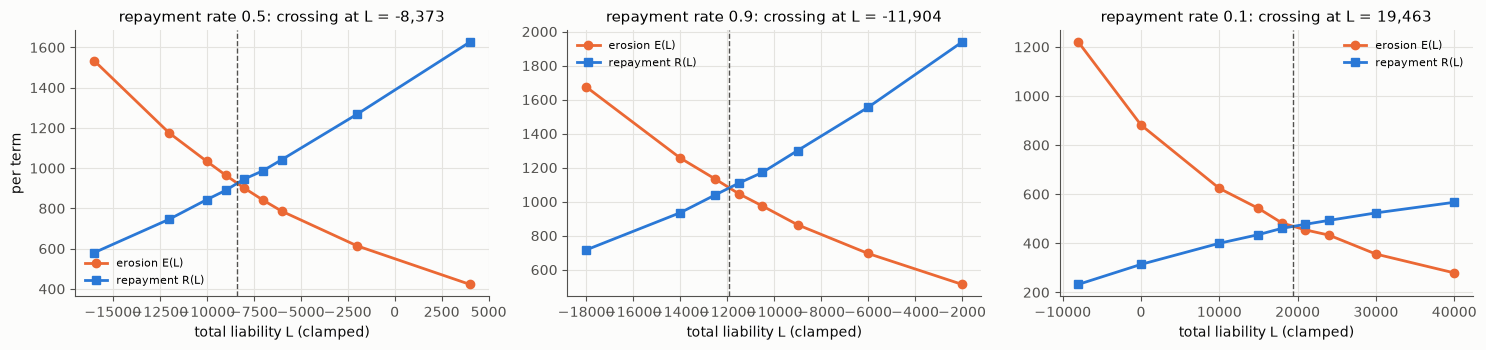

返済率   交点 L*      交点での傾き d(E−R)/dL   自由に走らせたときの全 liability(後半の平均)


 0.5       -8373           -0.122                    -8471


 0.9      -11904           -0.155                   -11995


 0.1       19463           -0.015                    24948


In [26]:
CL = {0.5: [-16000, -12000, -10000, -9000, -8000, -7000, -6000, -2000, 4000],
      0.9: [-18000, -14000, -12500, -11500, -10500, -9000, -6000, -2000],
      0.1: [-8000, 0, 10000, 15000, 18000, 21000, 24000, 30000, 40000]}
n_cl = 2 if FAST else 6
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
CROSS = {}
for j, (rho, Ls) in enumerate(CL.items()):
    kw = dict(sma1.V01, devaluation_of_intellprop=True, repayment_rate=rho)
    R = np.array(pmap(stockflow.run_clamp, [(s, kw, L, 80) for L in Ls for s in range(n_cl)])).reshape(len(Ls), n_cl, 3).mean(1)
    Ls_ = np.array(Ls, float)
    ax[j].plot(Ls_, R[:, 0], 'o-', color=PAL[1], label='erosion E(L)')
    ax[j].plot(Ls_, R[:, 1], 's-', color=PAL[0], label='repayment R(L)')
    g = R[:, 0] - R[:, 1]
    k = np.flatnonzero((g[:-1] > 0) & (g[1:] <= 0))[0]
    Lx = Ls_[k] + g[k] * (Ls_[k + 1] - Ls_[k]) / (g[k] - g[k + 1])
    slope = (g[k + 1] - g[k]) / (Ls_[k + 1] - Ls_[k])
    CROSS[rho] = (Lx, slope)
    ax[j].axvline(Lx, color=INK2, ls='--', lw=1)
    ax[j].set(title=f'repayment rate {rho}: crossing at L = {Lx:,.0f}', xlabel='total liability L (clamped)'); ax[j].legend(fontsize=8)
ax[0].set_ylabel('per term')
plt.tight_layout(); plt.show()
T_long = {0.5: 100, 0.9: 100, 0.1: 300 if FAST else 600}
print('返済率   交点 L*      交点での傾き d(E−R)/dL   自由に走らせたときの全 liability(後半の平均)')
FREE = {}
for rho, (Lx, slope) in CROSS.items():
    T = T_long[rho]
    R = pmap(sma1.summary, [(s, dict(sma1.V01, devaluation_of_intellprop=True, repayment_rate=rho, trials=T)) for s in range(n_seed)])
    FREE[rho] = np.array([r['L'] for r in R])
    print(f' {rho:3.1f}   {Lx:9.0f}         {slope:8.3f}                {FREE[rho][:, T // 2:].mean():9.0f}')

- Erosion の曲線は右下がり、返済の曲線は右上がりである。全 liability が大きい(借金が多く、現金が少ない)ほど、借金のある人が増えて返済が増え、現金を持つ人の手元が細って Erosion が減る。
- 二つの曲線の交点は、自由に走らせたときの全 liability の落ち着き先と、よく合う(返済率 0.5 と 0.9 では 1〜2% の違い)。
- **返済率 0.1 でも、交点はある**(全 liability が約 +2 万のところ)。返済率が低いと、返済の曲線が低くなり、交点が遠くにずれる。そして、交点での傾きが小さいので、そこへの近づき方がとても遅い。自由に走らせると、全 liability は 100 期では増え続けているように見えるが、600 期走らせると、交点(約 1.9 万)より少し上の 2.5 万前後で落ち着く。交点とのずれが少し大きいのは、留め置きの実験が全員を同じ額だけずらすので、借金と現金の分布の形が、自由に走らせたときと違ってくるためである(全 liability がプラスに大きいと、自由に走らせた場合には、大きな借金を抱えた人が増える)。作者が「どこかで増加傾向が終る可能性もあるが」と書いたとおり、**増加はいずれ終わる**。

これが、作者が「手にあまる」とした問いへの答えである。**全 liability は、「全 liability が $L$ のときの Erosion」と「全 liability が $L$ のときの返済」が等しくなる $L^*$ で釣り合う。** 二つの曲線は、留め置きの実験で測れる。返済率を上げれば返済の曲線が上がり、$L^*$ は左(現金の多い側)にずれる。売りやすさの傾斜を変えれば、借金と現金の分布の形が変わり、二つの曲線の形が変わって、$L^*$ が動く。

### 3.5 「平均への回帰」ではなく、負のフィードバック

作者は、釣り合う理由を「平均への回帰」と考えた。そして、それを確かめるために、売りやすさの傾斜を 0 にした(借金のある人ほど売りやすい、という性質を外した)。それでも釣り合ったので、「乱数には何度も尖った選択はなされず、平均への回帰が起きがちであるため」と考えた。

3.4 の曲線が示すのは、別の仕組みである。全 liability が $L^*$ より大きくなると、返済が Erosion を上回り、全 liability は下がる。小さくなると、Erosion が返済を上回り、全 liability は上がる。これは、乱数のばらつきではなく、**流れがストックに応じて変わる、決定論的な負のフィードバック**である。傾斜を 0 にしても、この仕組みは残る(傾斜は曲線の形を変えるだけである)。

確かめるために、60 期目の終わりに、全員の liability に同じ額を足して、全 liability を 5000 だけ押し上げる。ショックのない回との差が、どう消えていくかを見る。3.4 の交点での傾き $s$ から予想すると、差は毎期 $(1 + s)$ 倍ずつ縮むはずである。

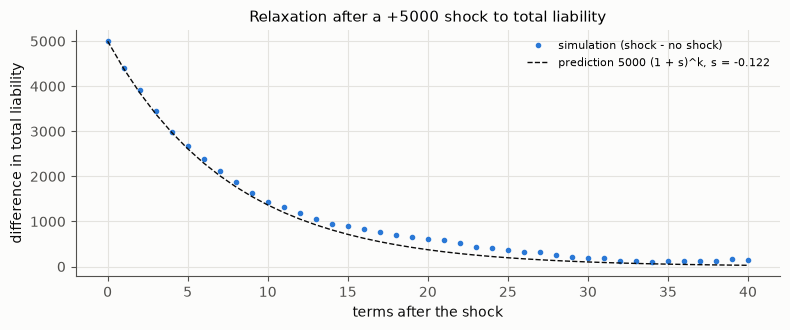

差が一期に縮む倍率: シミュレーション 0.888、3.4 の傾きからの予想 0.878(半分に戻るまで約 5.8 期)


In [27]:
kw = dict(sma1.V01, devaluation_of_intellprop=True)
n_sh = 6 if FAST else 16
d1 = np.array(pmap(stockflow.run_shock, [(s, kw, 60, 5000, 120) for s in range(n_sh)]))
d0 = np.array(pmap(stockflow.run_shock, [(s, kw, 60, 0, 120) for s in range(n_sh)]))
diff = (d1 - d0).mean(0)
s_ = CROSS[0.5][1]
k = np.arange(0, 41)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(k, diff[60:101], 'o', ms=3, color=PAL[0], label='simulation (shock - no shock)')
ax.plot(k, 5000 * (1 + s_) ** k, color=INK, lw=1, ls='--', label=f'prediction 5000 (1 + s)^k, s = {s_:.3f}')
ax.set(xlabel='terms after the shock', ylabel='difference in total liability', title='Relaxation after a +5000 shock to total liability'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
fit = np.polyfit(k[1:15], np.log(np.clip(diff[61:75], 1, None)), 1)[0]
print(f'差が一期に縮む倍率: シミュレーション {np.exp(fit):.3f}、3.4 の傾きからの予想 {1 + s_:.3f}(半分に戻るまで約 {np.log(0.5) / fit:.1f} 期)')

差は、予想どおりの速さで縮む。全 liability を押し上げると、およそ 6 期で半分に戻る。ショックの大きさは乱数のばらつきより大きく、戻り方は乱数によらず決まっている。**釣り合いを生んでいるのは、平均への回帰ではなく、ストックとフローの負のフィードバックである。**

### 3.6 ゼロ金利で、借入に上限のない経済として

最後に、このモデルを、作者のもう一つの古い考えと並べておく。作者は 2011 年、ベーシックインカム(BI)の受け取り資格がはっきりしないとき、BI の給付を担保に貸し付ける場合を考え、「BI を担保にした貸付の利率を $r_1$、一期の BI を $I_1$、貸付の総額を $X$ とすると、少なくとも $r_1 X < I_1$ でなければ担保つきの貸付は成り立たない」と書いた(aboutme:137725)。そして 2026 年に、「マイナス金利だと、貸倒れの判断ができなくなり、借金を積み増すだけで得をする」と気づいた(cocolog:95815240)。

2019 年のモデルは、**利子がなく(ゼロ金利)、借りる額に上限もない**経済である。作者自身、このモデルが、2011 年のモデルの「ベーシックインカム論の影響」を、借金がかなり自由にできる点に残していると書いている。ゼロ金利で、上限がなく、貸倒れもない。それでも全 liability が際限なく増えないのは、3.4・3.5 の負のフィードバックのためである。

では、借金に利子を付けたらどうなるか。毎期のはじめに、借金のある人の liability に利率 $r$ の利子を付ける。現金にも同じ利率の利子を付ける場合も試す。ここで大事なのは、毎期の返済には上限がある(働く人の「賃金 − 必需品」の 10 のうち、返済率 0.5 で 5)ことである。借金が $5 / r$ を超えた人は、利子だけで返済の上限を超え、**いつまでも返しきれない**。これは、作者の不等式 $r_1 X < I_1$(貸付の総額は、毎期返せる額を利率で割った値まで)と同じものである。経済学では「自然な借入制約」と呼ぶ。

In [28]:
print('利子     現金にも利子   全 liability(50・100・150・200 期の中央値)                     200 期目に「返しきれない借金」(> 5/r)を持つ人数')
for cash in (False, True):
    for r in (0.0, 0.01, 0.02, 0.05, 0.1):
        out = pmap(stockflow.run_interest, [(s, kw, r, cash, 200) for s in range(6)])
        L = np.median(np.array([o[0] for o in out])[:, [49, 99, 149, 199]], 0)
        print(f' {r:4.2f}      {"あり" if cash else "なし"}        ' + '  '.join(f'{v:12.4g}' for v in L) + f'          {np.mean([o[1] for o in out]):6.1f}')

利子     現金にも利子   全 liability(50・100・150・200 期の中央値)                     200 期目に「返しきれない借金」(> 5/r)を持つ人数


 0.00      なし               -8245         -8262         -8109         -8454             0.0


 0.01      なし               -7344         -7261         -7331         -7825             0.0


 0.02      なし               -6472         -4966         -4580         -3943             3.3


 0.05      なし                2449     5.998e+04      6.83e+05     7.784e+06           173.5


...

 0.00      あり               -8245         -8262         -8109         -8454             0.0


 0.01      あり               -8657         -8386         -8221         -8635             0.0


 0.02      あり               -8631         -7927         -7712         -6778             2.3


 0.05      あり               -4874     5.254e+04      7.07e+05      8.18e+06           135.3


 0.10      あり           7.332e+04     1.094e+07     1.287e+09     1.511e+11           351.2


- 利率 0.01 では、全 liability の落ち着き先が少し上(借金の側)にずれるだけである。
- 利率 0.02 では、「返しきれない借金」($> 5/0.02 = 250$)を持つ人が出始め、全 liability がゆっくり上がっていく。
- 利率 0.05 以上では、「返しきれない借金」($> 100$)を持つ人が何百人も出て、全 liability は指数関数的に発散する。利子が利子を生み、返済は追いつかない。現金にも利子を付けても、変わらない。

つまり、**利子のある経済では、借入には「毎期返せる額 ÷ 利率」という上限がなければならない。その上限を超えた借金は、貸倒れとして扱うしかない。** 作者が 2011 年に考えた、「利子が担保を食いつぶして 0 になれば、貸倒れと判断する」は、この上限の考え方である。逆に、利率が 0 以下なら、上限は無限大になり、貸倒れを判断する根拠がなくなる。2019 年のモデルがゼロ金利で上限なしでも壊れないのは、負のフィードバックが働いているからであり、利子を入れた途端に、上限と貸倒れの仕組みが必要になる。

このことは、作者のはてなポイントの制度設計(BI が否認されたときに受け取ったポイントをどう返すか)と合わせて、ノート P「ポイントと年金と信用」で改めて扱う(ノート P 第 8 章)。第 6 章では、借入の上限を、土地の担保で決める版を考える。

### 3.7 この章のまとめ

1. 全 liability の変化は「Erosion − 返済」に、正味の金融資産の変化は「10 × 働く人数 − 15 × 贅沢品の需要」に、毎期厳密に等しい。
2. 正味の金融資産が落ち着く限り、贅沢品の需要は「(賃金 − 必需品)× 働く人数 / 贅沢品の値段」= 500 に決まる。返済率や手元の借り入れの余地は、ストックを動かすだけで、需要の水準は変えない。値段は需要を変える。これが、返済率の謎とインパクト実験の答えである。
3. 全 liability は、留め置きの実験で測った Erosion の曲線(右下がり)と返済の曲線(右上がり)の交点で釣り合う。返済率 0.1 でも交点はあり、増加は 300〜600 期で終わる。
4. 釣り合いを生むのは、平均への回帰ではなく、流れがストックに応じて変わる負のフィードバックである。ショックからの戻りの速さは、交点での曲線の傾きで決まる(およそ 6 期で半分)。
5. このモデルは、ゼロ金利で借入の上限がない経済である。利子を入れると、「毎期返せる額 ÷ 利率」を超えた借金が返しきれなくなり、借入の上限と貸倒れの仕組みが必要になる。

### 3.8 Lean: 需要が 500 に決まる理由と、落ち着き先の一意性

3.2 節の「贅沢品の需要は、なぜ 500 なのか」は、恒等式から一行で出る。全体の正味の資産の増分は ΔA = (賃金 − 必需品の代金) × 人数 − 贅沢品の値段 × 需要 なので、A が落ち着けば、需要は (賃金 − 必需品) × 人数 / 値段 に決まる。返済の決まりや傾斜によらない。3.4 節の留め置きの実験(借り入れ E(L) は右下がり、返済 R(L) は右上がり)からは、落ち着き先が高々一つであることが出る。

In [29]:
%%writefile -a asset_market.lean
/-! ## 第 3 章 借金はなぜ際限なく増えないのか

全体の正味の資産 A の毎期の増分は、ΔA = (賃金 − 必需品の代金) × 人数 − 贅沢品の値段 × 贅沢品の需要(恒等式)。
A が落ち着く(ΔA = 0)なら、贅沢品の需要は (賃金 − 必需品) × 人数 / 値段 に決まる。返済の決まりや傾斜によらない。 -/
theorem demand_pinned {w n W pL D : ℝ} (hp : pL ≠ 0) (hA : (w - n) * W - pL * D = 0) :
    D = (w - n) * W / pL := by
  field_simp; linarith

/-- 借り入れ E(L) が全 liability L について右下がり、返済 R(L) が右上がり(真に)なら、
E(L) = R(L) となる L(落ち着き先)は高々一つ。 -/
theorem unique_crossing (E R : ℝ → ℝ) (hE : Antitone E) (hR : StrictMono R) {L₁ L₂ : ℝ}
    (h1 : E L₁ = R L₁) (h2 : E L₂ = R L₂) : L₁ = L₂ := by
  by_contra hne
  rcases lt_or_gt_of_ne hne with h | h
  · have := hR h; have := hE h.le; linarith
  · have := hR h; have := hE h.le; linarith

Appending to asset_market.lean


## 第 4 章 富の分布と、逆転のチャンス

作者がこのモデルを作った出発点は、富の分布だった。`micro_economy_*.py` では貯蓄の初期値を指数分布にしていたが、シミュレーションが進むと、貯蓄はだんだん平等になり、指数分布でなくなった。「定常状態に至るとき、それが初期値と同じようになれば安定するのではないか」。作者は、指数分布が「偶然に出会った二人が、二人の富の総額をランダムに分け合う」交換から生まれることを知り(「富の分布について」、駒澤大学学術機関リポジトリ)、では資産の取引を別に考えたらどうか、と考えた。

この章では、次の三つを調べる。

1. ランダムな交換は、どういう分布を生むのか。2019 年のモデルの分布は、何の分布なのか。
2. 初期値を定常状態の分布にそろえれば、作者の期待したとおり、モデルは最初から安定するのか。
3. 作者がその2 で調べた「逆転のチャンス」(順位の入れ替わりやすさ)は、何で決まるのか。

### 4.1 ランダムな交換と、指数分布・ガンマ分布

作者が参照した模型は、物理学者が「経済物理学」として調べてきたものである。

- **ランダムな分け合い**: 二人を選び、二人の富の合計を、一様乱数の比で分け直す。これを繰り返すと、富の分布は**指数分布**になる(Dragulescu and Yakovenko 2000)。気体の分子がぶつかってエネルギーを分け合うと、エネルギーの分布が指数分布(ボルツマン分布)になるのと、同じ理由である。
- **貯める割合のある交換**: 各自が富の一部 $\lambda$ を手元に残し、残りだけを分け合う。すると、分布は 0 の近くが少なくなり、山の形の**ガンマ分布**になる(Chakraborti and Chakrabarti 2000)。ガンマ分布の形を決める数は、$1 + 3\lambda / (1 - \lambda)$ でよく近似できる(Patriarca, Chakraborti and Kaski 2004)。
- 作者の 2026 年の言葉を借りて、**豊かな人ほど交換に加わりやすい**場合も試す(選ばれる確率を富に比例させる)。

1000 人、20 万回の交換で試す。

In [30]:
%%writefile dist2.py
"""dist2.py -- 富の分布と、逆転のチャンス。ランダムな交換の模型、2019 年のモデルの分布、初期値、移動性。"""
import numpy as np
import sma1


def exchange(a):
    """(seed, 人数, 交換の回数, 貯める割合 lam, 参加の偏り gamma) → 最後の富と、途中の富の記録(順位の移動を見るため)。
    毎回、二人を選び、二人の富のうち (1 − lam) の分を合わせて、一様乱数の比で分け直す(lam は各自が手元に残す割合)。
    gamma > 0 なら、富の多い人ほど交換に選ばれやすい(選ばれる確率 ∝ 富^gamma)。"""
    seed, N, steps, lam, gamma = a
    rng = np.random.default_rng(seed)
    w = np.ones(N)
    snaps = []
    every = steps // 40
    for t in range(steps):
        if gamma:
            p = w ** gamma; p /= p.sum()
            i, j = rng.choice(N, 2, replace=False, p=p)
        else:
            i, j = rng.choice(N, 2, replace=False)
        pool = (1 - lam) * (w[i] + w[j])
        eps = rng.random()
        w[i], w[j] = lam * w[i] + eps * pool, lam * w[j] + (1 - eps) * pool
        if (t + 1) % every == 0:
            snaps.append(w.copy())
    return w, np.array(snaps)

Overwriting dist2.py


random sharing (lam = 0)        : ガンマ分布を当てはめた形の数  0.98(理論 1.00)、変動係数 1.00、上位 1% の取り分 5.7%


saving lam = 0.5                : ガンマ分布を当てはめた形の数  3.99(理論 4.00)、変動係数 0.50、上位 1% の取り分 2.7%


rich trade more (prob ~ wealth) : ガンマ分布を当てはめた形の数  0.27、変動係数 2.92、上位 1% の取り分 22.0%


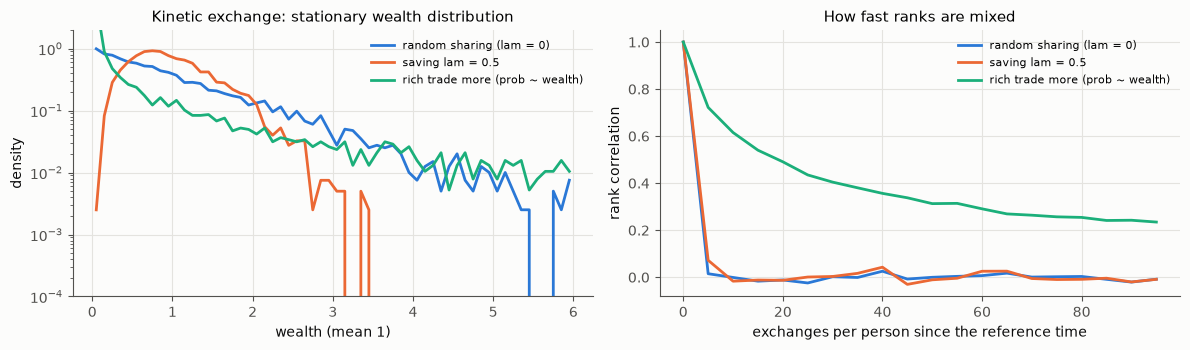

In [31]:
import dist2
from scipy import stats
importlib.reload(dist2)
EXM = {'random sharing (lam = 0)': (0.0, 0.0), 'saving lam = 0.5': (0.5, 0.0), 'rich trade more (prob ~ wealth)': (0.0, 1.0)}
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
EXR = {}
for j, (lab, (lam, g)) in enumerate(EXM.items()):
    out = pmap(dist2.exchange, [(s, 1000, 200000, lam, g) for s in range(4)])
    EXR[lab] = out
    w = np.concatenate([o[0] for o in out])
    k = stats.gamma.fit(w, floc=0)[0]
    top = np.mean([np.sort(o[0])[-10:].sum() / o[0].sum() for o in out])
    xs = np.linspace(0, 6, 61)
    h, _ = np.histogram(w, bins=xs, density=True)
    ax[0].plot((xs[1:] + xs[:-1]) / 2, h, color=PAL[j], label=lab)
    th = f'(理論 {1 + 3 * lam / (1 - lam):.2f})' if g == 0 else ''
    print(f'{lab:32s}: ガンマ分布を当てはめた形の数 {k:5.2f}{th}、変動係数 {w.std() / w.mean():.2f}、上位 1% の取り分 {top:.1%}')
ax[0].set(yscale='log', ylim=(1e-4, 2), xlabel='wealth (mean 1)', ylabel='density', title='Kinetic exchange: stationary wealth distribution'); ax[0].legend(fontsize=8)
for j, (lab, out) in enumerate(EXR.items()):
    rho = []
    for o in out:
        S = o[1]
        R = np.argsort(np.argsort(S, axis=1), axis=1)
        rho.append([np.corrcoef(R[20], R[20 + k])[0, 1] for k in range(0, 20)])
    ax[1].plot(np.arange(20) * 5, np.mean(rho, 0), color=PAL[j], label=lab)
ax[1].set(xlabel='exchanges per person since the reference time', ylabel='rank correlation', title='How fast ranks are mixed'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

- ランダムな分け合いでは、形の数は 1(指数分布)。貯める割合 0.5 では、形の数は 4(ガンマ分布)で、理論とよく合う。貯めると、極端に貧しい人も、極端に豊かな人も減る。
- 豊かな人ほど交換に加わると、富は大きく偏り(上位 1% が 2 割を持つ)、順位も入れ替わりにくくなる(右の図で、順位の相関がなかなか下がらない)。貧しい人は交換に加われず、貧しいまま取り残される。

### 4.2 2019 年のモデルの分布

2019 年のモデルの、51〜100 期の全員の値を集めて、分布の形を調べる。指数分布なら変動係数(標準偏差 / 平均)は 1、一様分布なら超過尖度(裾の重さの指標。正規分布で 0)は −1.2、両側指数分布(ラプラス分布)なら超過尖度は 3 である。

In [32]:
%%writefile -a dist2.py
def pooled(a):
    """(seed, オプション, 期数, 集める最初の期) → その期から後の、全員の土地・知財・貯蓄・liability・正味資産を集めたもの。"""
    seed, kw, T, t0 = a
    P = sma1.params(**dict(kw, trials=T))
    e = sma1.Economy(P, seed); e.initialize()
    out = {k: [] for k in ('land', 'intellprop', 'savings', 'liability', 'net')}
    for t in range(T):
        e.step()
        if t >= t0:
            for x in e.players:
                out['land'].append(x.land); out['intellprop'].append(x.intellprop)
                out['savings'].append(x.savings); out['liability'].append(x.liability); out['net'].append(x.net_asset())
    return {k: np.array(v) for k, v in out.items()}

Appending to dist2.py


変数         平均     変動係数   歪度    超過尖度   ガンマ分布の形の数(正の値に当てはめ)
土地           19.92     1.41     2.15      5.59         1.68
知財           20.08     0.78     1.51      3.41         1.61
貯蓄           11.00     0.82     0.21     -1.19          nan
liability     -8.42     2.83     0.23      5.05          nan
正味資産         59.42     0.64     1.44      3.70         3.06


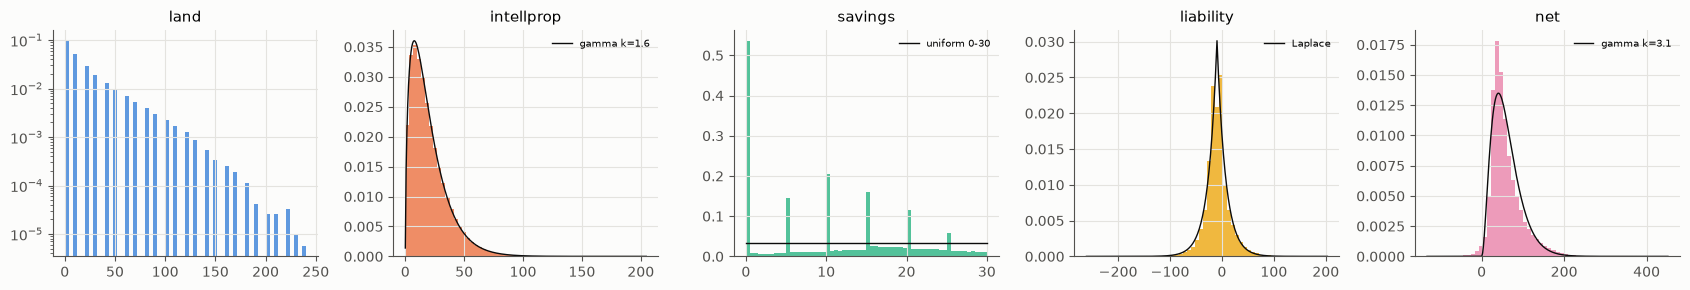

貯蓄: ちょうど 0 の人の割合 26.5%、0 以外の 5 の倍数の割合 30.1%、残りの平均 16.5(0〜30 の一様分布なら 15)、残りの超過尖度 -0.71(一様分布なら −1.2)


In [33]:
importlib.reload(dist2)
POOL = pmap(dist2.pooled, [(s, dict(sma1.V01, devaluation_of_intellprop=True), 100, 50) for s in range(8)])
X = {k: np.concatenate([p[k] for p in POOL]) for k in POOL[0]}
lab = {'land': '土地', 'intellprop': '知財', 'savings': '貯蓄', 'liability': 'liability', 'net': '正味資産'}
print('変数         平均     変動係数   歪度    超過尖度   ガンマ分布の形の数(正の値に当てはめ)')
for k in ('land', 'intellprop', 'savings', 'liability', 'net'):
    x = X[k]
    kk = stats.gamma.fit(x[x > 0], floc=0)[0] if k in ('land', 'intellprop', 'net') else float('nan')
    print(f'{lab[k]:8s}  {x.mean():8.2f}   {x.std() / abs(x.mean()):6.2f}   {stats.skew(x):6.2f}   {stats.kurtosis(x):7.2f}       {kk:6.2f}')
fig, ax = plt.subplots(1, 5, figsize=(17, 3.0))
for j, k in enumerate(('land', 'intellprop', 'savings', 'liability', 'net')):
    x = X[k]
    ax[j].hist(x, bins=60, density=True, color=PAL[j], alpha=0.75)
    xs = np.linspace(x.min(), x.max(), 300)
    if k in ('intellprop', 'net'):
        a_, l_, s_ = stats.gamma.fit(x[x > 0], floc=0); ax[j].plot(xs, stats.gamma.pdf(xs, a_, l_, s_), color=INK, lw=1, label=f'gamma k={a_:.1f}')
    if k == 'savings':
        ax[j].plot(xs, np.where((xs >= 0) & (xs <= 30), 1 / 30, 0), color=INK, lw=1, label='uniform 0-30')
    if k == 'liability':
        m_, b_ = stats.laplace.fit(x); ax[j].plot(xs, stats.laplace.pdf(xs, m_, b_), color=INK, lw=1, label='Laplace')
    if k == 'land':
        ax[j].set_yscale('log')
    ax[j].set(title=k); ax[j].legend(fontsize=7) if k != 'land' else None
plt.tight_layout(); plt.show()
sv = X['savings']
z = np.isclose(sv, 0); m5 = np.isclose(sv % 5, 0) & ~z
rest = sv[~z & ~m5]
print(f'貯蓄: ちょうど 0 の人の割合 {z.mean():.1%}、0 以外の 5 の倍数の割合 {m5.mean():.1%}、残りの平均 {rest.mean():.1f}(0〜30 の一様分布なら 15)、残りの超過尖度 {stats.kurtosis(rest):.2f}(一様分布なら −1.2)')

- **知財**は、形の数が 1.6 のガンマ分布に近い。作者が「0 で少し下がる山型。何分布なのだろうか」と書いたものの答えは、**ガンマ分布**である。知財は、買うたびに払った値段以上の評価で積み上がり(2.2)、全体を毎期同じ倍率で切り下げられる。手元の知財に比例して積み増す、という掛け算型の成長と、全体の切り下げの組み合わせは、ガンマ分布を生みやすい。
- **貯蓄**は、三つの部分からなる。ちょうど 0 の人が約 4 分の 1(現金の取り崩しや借金で 0 に戻された人)、0 以外の 5 の倍数ちょうどの人が約 3 割(賃金・必需品・贅沢品・返済がどれも 5 の倍数なので、取り崩しのない人の貯蓄は 5 刻みで動く)、そして残りは 0〜30 に広く散らばる(一様分布よりは、真ん中がやや厚い)。作者が「30 を上限として 0 以外は一様分布か、整数的なとがりのある分布」と書いたとおりである。贅沢品を買う条件が「手元のお金 ≥ 30」なので、貯蓄は 30 に近づくと贅沢品に使われて下がり、0 を割ると 0 に戻される。(表の超過尖度 −1.2 は、0 のかたまりととがりが混ざった結果で、一様分布の値と一致するのはたまたまである。)
- **liability** は、超過尖度が 5 近くあり、正規分布(0)よりも、両側指数分布(3)よりも、裾が重い。0 にとがりがあるのは、借金をちょうど返し終えた人である。
- **土地**は、変動係数が 1.4 で、指数分布(1)より偏っている(対数目盛の図で、裾がまっすぐより上に反る)。
- **正味資産**は、形の数 3 前後のガンマ分布に近い。

どれも、最初の指数分布・正規分布とは違う形に落ち着く。

### 4.3 初期値を、定常状態の分布にそろえる

作者の動機は、「定常状態が初期値と同じになれば、モデルは安定する」だった。そこで、初期値を三通りに変えて、最初の期の動きを比べる。

- **元のまま**: 元のコードの初期値(指数分布と正規分布)。
- **分布の形だけ**: 別の回で 200 期走らせた定常状態から、各変数の値を取り、人ごとの組み合わせはばらばらにして配る。
- **人ごとの組み合わせごと**: 定常状態の各人の値を、組み合わせのまま配る。

In [34]:
%%writefile -a dist2.py
def snapshot(a):
    """(seed, オプション, 期数) → その期数だけ走らせた後の、全員の (働いているか, 貯蓄, liability, 土地, 知財) を、並びの順に。"""
    seed, kw, T = a
    P = sma1.params(**dict(kw, trials=T))
    e = sma1.Economy(P, seed); e.initialize()
    for t in range(T):
        e.step()
    return [(x.working, x.savings, x.liability, x.land, x.intellprop) for x in e.players]


def run_from(a):
    """(seed, オプション, 期数, 初期値の作り方, 定常状態のスナップショット) → 全 liability と贅沢品の需要の経路。
    作り方: 'default'(元のコードの初期値。指数分布と正規分布)、'marginal'(スナップショットの各変数を、
    人ごとの組み合わせをばらばらにして配る。分布の形だけを定常状態にそろえる)、'joint'(スナップショットを、
    人ごとの組み合わせのまま配る)。"""
    seed, kw, T, mode, snap = a
    P = sma1.params(**dict(kw, trials=T))
    e = sma1.Economy(P, seed); e.initialize()
    if mode != 'default':
        cols = list(zip(*snap))
        if mode == 'marginal':
            rng = np.random.default_rng(seed)
            cols = [list(np.array(c)[rng.permutation(len(c))]) for c in cols]
            cols[0] = list(zip(*snap))[0]             # 働いているかどうかの並びは、そのまま(働く人を前に)
        for x, w, s, l, ld, ip in zip(e.players, *cols):
            x.working, x.savings, x.liability, x.land, x.intellprop = bool(w), float(s), float(l), float(ld), float(ip)
    L, D = [], []
    for t in range(T):
        r = e.step()
        L.append(r['total'][3]); D.append(r['demand'])
    return np.array(L), np.array(D)

Appending to dist2.py


original initial values         : 1〜10 期の全 liability の、落ち着き先からのずれの平均   3989、1〜5 期の需要の平均   401


stationary marginals (shuffled) : 1〜10 期の全 liability の、落ち着き先からのずれの平均    576、1〜5 期の需要の平均   491


stationary joint state          : 1〜10 期の全 liability の、落ち着き先からのずれの平均    138、1〜5 期の需要の平均   494


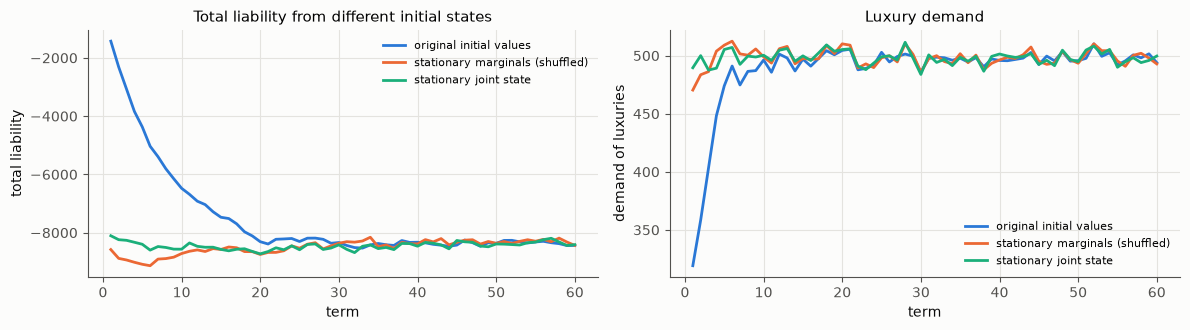

In [35]:
importlib.reload(dist2)
base = dict(sma1.V01, devaluation_of_intellprop=True)
snap = dist2.snapshot((999, base, 200))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
for j, (mode, lab) in enumerate((('default', 'original initial values'), ('marginal', 'stationary marginals (shuffled)'), ('joint', 'stationary joint state'))):
    R = pmap(dist2.run_from, [(s, base, 60, mode, snap) for s in range(n_seed)])
    L = np.array([r[0] for r in R]); Dm = np.array([r[1] for r in R])
    ax[0].plot(np.arange(1, 61), np.median(L, 0), color=PAL[j], label=lab)
    ax[1].plot(np.arange(1, 61), Dm.mean(0), color=PAL[j], label=lab)
    dev = np.abs(np.median(L, 0)[:10] - np.median(L, 0)[30:].mean()).mean()
    print(f'{lab:32s}: 1〜10 期の全 liability の、落ち着き先からのずれの平均 {dev:6.0f}、1〜5 期の需要の平均 {Dm[:, :5].mean():5.0f}')
ax[0].set(xlabel='term', ylabel='total liability', title='Total liability from different initial states'); ax[0].legend(fontsize=8)
ax[1].set(xlabel='term', ylabel='demand of luxuries', title='Luxury demand'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

- 元の初期値では、全 liability は最初の 20 期ほどで 0 から −8000 台へ大きく動き、贅沢品の需要も 300 台から 500 へ上がっていく。
- **分布の形だけを定常状態にそろえると、この過渡的な動きは、ほとんど消える。** 最初の 10 期の全 liability のずれは、元のままの 7 分の 1 になり、需要も最初から 500 近くで動く。人ごとの組み合わせ(誰が借金と知財を同時に持つか、など)までそろえると、ずれはさらに 4 分の 1 になる。全体の動きを決めているのは、主に各変数の分布の形(と、その合計)で、組み合わせの効き目は小さい。

作者の直感は正しかった。**初期値を定常状態の分布にすれば、モデルは最初から定常状態で動く。** ただし、その分布は指数分布でも正規分布でもなく、4.2 の形(ガンマ分布、一様分布、裾の重い山)である。そして、その形は、規則(ここでは贅沢品を買う条件の基準額や、知財の評価と切り下げ)から決まる。分布の形を先に決めて、それに合う規則を探すのではなく、規則から分布の形が出てくる。だから、作者が当時「どういう分布にしたらいいのか今ひとつよくわからない」と感じたのは、自然なことだった。分布は、規則を決めたあとに、走らせて求めるものなのである(物理でいう「緩和」)。

### 4.4 逆転のチャンス

作者は、その2 で、逆転のしやすさを **Rank Change Mean**(各人の、これまでの純資産の順位の最大と最小の差の、全員での平均)で測り、売り手と買い手の選び方を変えて比べた。

この指標は、時間がたつほど大きくなり(最大と最小の差は縮まない)、一時的な上下(順位がたまたま入れ替わってすぐ戻る)も数える。そこで、移動性を測るよく使われる指標も並べる。

- **順位の相関**: $t$ 期と $t + 10$ 期の純資産の順位の相関(スピアマン)。1 なら誰も動かず、0 なら完全に混ざる。
- **Shorrocks の指標**: 純資産で五つの組(五分位)に分け、10 期でどの組に移ったかの行列 $P$ から、$(5 - \mathrm{trace}\,P)/4$。0 なら誰も組を移らず、1 なら完全に混ざる(Shorrocks 1978)。

作者がその2 で比べた 8 通りの組み合わせ(第一「現実的」モデルを元に、知財の買い手と売り手の選び方を変える)を、乱数の種 20 通りで 50 期走らせる。

In [36]:
%%writefile -a dist2.py
def mobility(a):
    """(seed, オプション, 期数) → 移動性の指標:
    rank_change: 元のコードの Rank Change Mean(各人の、これまでの純資産の順位の最大と最小の差の平均。最後の期)。
    rho: 純資産の順位の、k 期離れた時点どうしの相関(スピアマン。k = 1, 5, 10, 20。後半の期で平均)。
    shorrocks: 純資産の五分位の、10 期での移り変わりの行列 P から、(5 − trace P)/4(0 なら誰も動かない、1 なら完全に混ざる)。
    part: 純資産の五分位ごとの、知財と土地の売り買いに加わった回数(一期一人あたり、後半の期)。"""
    seed, kw, T = a
    P_ = sma1.params(**dict(kw, trials=T))
    e = sma1.Economy(P_, seed); e.initialize()
    N = P_.population
    NW = np.zeros((T, N))
    part = {k: np.zeros(5) for k in ('ip_buy', 'ip_sell', 'land_buy', 'land_sell')}
    q_now = {}
    def log(kind, *a_):
        if kind in ('ip', 'land') and q_now:
            b, s = a_[0], a_[1]
            part[kind + '_buy'][q_now[b.num]] += 1
            part[kind + '_sell'][q_now[s.num]] += 1
    e.log = log
    rank_change = None
    for t in range(T):
        if t >= T // 2:
            nw = np.array([x.net_asset() for x in e.players]); nums = [x.num for x in e.players]
            qs = np.argsort(np.argsort(nw)) * 5 // N
            q_now.clear(); q_now.update(dict(zip(nums, qs)))
        else:
            q_now.clear()
        r = e.step()
        rank_change = r['rank_change']
        for x in e.players:
            NW[t, x.num] = x.net_asset()
    R = np.argsort(np.argsort(NW, axis=1), axis=1).astype(float)
    rho = {}
    for k in (1, 5, 10, 20):
        cs = [np.corrcoef(R[t], R[t + k])[0, 1] for t in range(T // 2, T - k)]
        rho[k] = float(np.mean(cs))
    Q = (R * 5 // N).astype(int)
    M = np.zeros((5, 5))
    for t in range(T // 2, T - 10):
        for a_, b_ in zip(Q[t], Q[t + 10]):
            M[a_, b_] += 1
    M /= M.sum(1, keepdims=True)
    shorrocks = (5 - np.trace(M)) / 4
    n_terms = T - T // 2
    return dict(rank_change=rank_change, rho=rho, shorrocks=shorrocks,
                part={k: v / (n_terms * N / 5) for k, v in part.items()})

Appending to dist2.py


In [37]:
importlib.reload(dist2)
b1 = dict(devaluation_of_intellprop=True, asset_rank='net', cash_on_hand='rigid', sort_of_land_buyer='cash', sort_of_land_seller='land',
          coeff_of_intellprop_buyer=0.3, coeff_of_intellprop_seller=0.8, coeff_of_land_buyer=0.8, coeff_of_land_seller=0.3)
GRID = [('知財の多い人', '知財の多い人', 'ascend', 'ascend', 656.367), ('知財の少ない人', '知財の多い人', 'descend', 'ascend', 687.057),
        ('知財の多い人', '知財の少ない人', 'ascend', 'descend', 722.907), ('知財の少ない人', '知財の少ない人', 'descend', 'descend', 750.252),
        ('現金のある人', '知財の多い人', 'cash', 'ascend', 663.106), ('現金のある人', '知財の少ない人', 'cash', 'descend', 743.453),
        ('借金のある人', '知財の多い人', 'liability', 'ascend', 688.839), ('借金のある人', '知財の少ない人', 'liability', 'descend', 716.653)]
print('知財の買い手        知財の売り手     Rank Change Mean: 記事 / 20 回の平均 [範囲]   順位の相関(10 期)   Shorrocks')
for bl, sl, b, s, art in GRID:
    M = pmap(dist2.mobility, [(sd, dict(b1, sort_of_intellprop_buyer=b, sort_of_intellprop_seller=s), 50) for sd in range(n_seed)])
    rc = np.array([m['rank_change'] for m in M])
    print(f'{bl:12s}  {sl:12s}   {art:6.1f} / {rc.mean():6.1f} [{rc.min():.0f}, {rc.max():.0f}]          {np.mean([m["rho"][10] for m in M]):.3f}           {np.mean([m["shorrocks"] for m in M]):.3f}')

知財の買い手        知財の売り手     Rank Change Mean: 記事 / 20 回の平均 [範囲]   順位の相関(10 期)   Shorrocks


知財の多い人        知財の多い人          656.4 /  665.6 [643, 679]          0.647           0.742


知財の少ない人       知財の多い人          687.1 /  675.9 [651, 691]          0.630           0.756


知財の多い人        知財の少ない人         722.9 /  724.2 [710, 739]          0.551           0.805


知財の少ない人       知財の少ない人         750.3 /  740.4 [722, 757]          0.530           0.816


現金のある人        知財の多い人          663.1 /  648.5 [635, 671]          0.673           0.732


現金のある人        知財の少ない人         743.5 /  737.6 [723, 756]          0.527           0.820


借金のある人        知財の多い人          688.8 /  694.4 [675, 709]          0.602           0.767


借金のある人        知財の少ない人         716.7 /  729.0 [711, 751]          0.548           0.803


- 記事の値(一回ずつの実行)は、どれも 20 回の範囲の中にある。
- 三つの指標は、ほぼ同じ順に並ぶ。Rank Change Mean が大きい組み合わせほど、10 期での順位の相関が低く、Shorrocks の指標が大きい(差のごく小さい組み合わせどうしで、順が入れ替わる所があるだけである)。作者の指標は、一時的な上下も数えるが、移動性の順位付けとしては正しかった。
- **効いているのは、主に売り手の側である。** 知財の少ない人が売り手になると、買い手が誰でも、逆転がはっきり増える(Rank Change Mean で 650〜690 から 720〜740 へ)。売った代金が、貧しい人に入るからである。買い手の側の違いは、それに比べて小さい。
- 作者の結論「貧しい者どうしで取引したほうが良い」「現金のある者が貧しい者から買えば良い」は、どちらも確かめられた。ただし、その中身は「**貧しい人が売り手になって、代金を受け取れること**」である。

### 4.5 永続する賭け

作者は、2026 年 1 月の「ひとこと」(cocolog:95815240)で、次のように書いている。

> 贋作が真作になるかどうかで「賭け」は成立する。しかし、それが永続する「賭け」になるためには、真作となって儲けたものが再び「賭け」にその資産を投じなければならない。そのとき負けた者も平等に「賭け」の対象にならなければ、それは永続しているとは言えない。ここに solid state … 格差固定社会の問題があるのかもしれない。

4.1 の交換の模型は、この直感をそのまま表している。誰もが等しく交換に加われば、順位は速く入れ替わる。豊かな人ほど交換に加わり、貧しい人が加われなければ、富は偏り、順位は固まる。作者の言う「solid state」(固体のように動かない状態)である。

2019 年のモデルでは、誰がどれだけ資産の売り買いに加わっているのか。基本の設定(その1 相当)で、純資産の五分位ごとに、一期一人あたりの売り買いへの参加の回数を数える。

In [38]:
M = pmap(dist2.mobility, [(sd, dict(sma1.V01, devaluation_of_intellprop=True), 100) for sd in range(n_seed)])
part = {k: np.mean([m['part'][k] for m in M], 0) for k in ('ip_buy', 'ip_sell', 'land_buy', 'land_sell')}
name = {'ip_buy': '知財を買う', 'ip_sell': '知財を売る', 'land_buy': '土地を買う', 'land_sell': '土地を売る'}
print('純資産の五分位        ' + '   '.join(f'{q}' for q in ('最下位', '第二', '第三', '第四', '最上位')))
for k, v in part.items():
    print(f'{name[k]:10s}       ' + '   '.join(f'{x:5.3f}' for x in v))
rho = {k: np.mean([m['rho'][k] for m in M]) for k in (1, 5, 10, 20)}
print('\n純資産の順位の相関(k 期離れた時点どうし):', '  '.join(f'k={k}: {v:.2f}' for k, v in rho.items()))
print(f'Shorrocks の指標(10 期): {np.mean([m["shorrocks"] for m in M]):.2f}')

純資産の五分位        最下位   第二   第三   第四   最上位
知財を買う            0.265   0.289   0.299   0.313   0.334
知財を売る            0.334   0.313   0.303   0.286   0.264
土地を買う            0.130   0.161   0.173   0.190   0.213
土地を売る            0.080   0.144   0.204   0.233   0.208

純資産の順位の相関(k 期離れた時点どうし): k=1: 0.93  k=5: 0.77  k=10: 0.65  k=20: 0.51
Shorrocks の指標(10 期): 0.74


- 最下位の五分位の人も、一期に 0.26 回ほど知財を買い、0.34 回ほど知財を売っている。知財の売り買いには、貧しい人もほぼ等しく加わっている(むしろ、売り手としては多く加わっている)。
- 土地の売り買いでは、最下位の人の参加は少ない(売る土地を持っていないことが多い)。
- 順位は速く入れ替わる。20 期離れると、順位の相関は 0.5 まで下がる。

2019 年のモデルは、作者の言う「永続する賭け」が成り立っている経済である。負けた人も、知財の売り手として賭けに加わり続け、代金を受け取って順位を上げる機会がある。それを支えているのは、2.2 で見た**知財の性質**(持っていなくても、土地があれば値が付き、売っても減らない)と、**知財の切り下げ**(勝った人の知財も、毎期同じ倍率で目減りする)である。

作者は、2026 年の同じ「ひとこと」で、日本の少子化と格差の固定を、「賭けが成立することが、相対的になくなっていった」ことと結び付けている。このモデルの言葉で言えば、それは、売り手として加われる人が偏り(4.4 の「知財の多い人が売る」)、勝った人の資産が目減りしない(知財の切り下げがない)方向への変化にあたる。4.4 で、売り手を知財の多い人に寄せると、逆転が減ることを見た。第 3 章で、知財の切り下げをしないと、富が際限なく膨らむことを見た。

### 4.6 この章のまとめ

1. ランダムな交換は指数分布を、貯める割合のある交換はガンマ分布を生む。豊かな人ほど交換に加わると、富は偏り、順位は固まる。
2. 2019 年のモデルの分布は、知財がガンマ分布(形の数 1.6。作者の言う「0 で少し下がる山型」)、貯蓄が「0 のかたまり + 5 の倍数のとがり + 0〜30 への広がり」、liability が裾の重い山、正味資産がガンマ分布に近い形である。どれも、規則から出てくる形である。
3. 初期値を定常状態の分布(の形)にそろえれば、過渡的な動きはほぼ消える。作者の直感は正しかったが、その分布は、規則を決めたあとに、走らせて求めるものだった。
4. 逆転のしやすさは、主に「誰が売り手になって代金を受け取るか」で決まる。貧しい人が売り手になれると、逆転が増える。作者の Rank Change Mean は、標準的な移動性の指標と同じ順位付けを与える。
5. 2019 年のモデルは、貧しい人も売り手として賭けに加わり続ける、「永続する賭け」の経済である。

## 第 5 章 土地と知財

作者は、資産の代表として、二つのものを選んだ。

> 資産として毎期総額を無理矢理一定にするために取引等がなければ自然に減価していく「知的財産」と減価のない「土地」を資産の代表として別々にとらえることにする。「土地」は減価しないかわりに増価しない。

この章では、この二つの資産を、それぞれ調べる。

1. 知財の「切り下げ」は、何を意味しているのか。定率の減耗や、ノート O の「資産減耗遷移」(枠組みの交代として、一挙に起こる減耗)と比べると、何が違うのか。
2. 土地に値段がないことは、何を意味しているのか。値段を動かすと、何が起こるのか。
3. 知財は、買うと得なのか、損なのか。誰が買っているのか。
4. 作者が 2020 年に、このモデルで考えた「免許と懲罰的罰金」の比べ方は、数で確かめると、どうなるか。

### 5.1 知財の切り下げは、内生的な減耗率

元のコードの切り下げは、毎期の終わりに、知財の総額が、その期のはじめの値に戻るように、全員の知財に同じ倍率をかける。第 2 章で見たとおり、一期に約 2 割が消える。この倍率は、その期にどれだけ知財が積まれたかで決まるので、**内生的に決まる減耗率**と読める。

では、減耗率を、外から一定の値に決めたらどうなるか。毎期、全員の知財を一定の率 $\delta$ で減らす。さらに、ノート O の「資産減耗遷移」にならって、ふだんは減らさず、知財の総額が最初の値の 2 倍(または 1.5 倍)を超えた期に、一挙に最初の値まで切り下げる版も試す。

In [39]:
%%writefile landip.py
"""landip.py -- 土地と知財: 知財の減耗のしかた、土地の値段、知財の損得、免許と懲罰的罰金。"""
import numpy as np
import sma1


def run_deval(a):
    """(seed, オプション, 減耗のしかた, パラメータ, 期数) → 期ごとの (知財の総額(切り下げ前), 全 liability, 贅沢品の需要) と、
    最後の期の Rank Change Mean。減耗のしかた:
    'endogenous'(元のコード。毎期、総額を前の期の値に戻す)、'fixed'(毎期、一定の率 x で減らす)、
    'transition'(ふだんは減らさず、総額が最初の x 倍を超えた期の終わりに、一挙に最初の総額まで切り下げる)。"""
    seed, kw, mode, x, T = a
    P = sma1.params(**dict(kw, trials=T, devaluation_of_intellprop=(mode == 'endogenous')))
    e = sma1.Economy(P, seed); e.initialize()
    ip0 = 0.0
    for p in e.players:
        ip0 += p.intellprop
    out = []
    for t in range(T):
        r = e.step()
        out.append((r['total'][0], r['total'][3], r['demand']))
        if mode == 'fixed':
            for p in e.players:
                p.intellprop *= (1 - x)
        elif mode == 'transition' and r['total'][0] > x * ip0:
            k = ip0 / r['total'][0]
            for p in e.players:
                p.intellprop *= k
    return np.array(out), r['rank_change']

Overwriting landip.py


減耗のしかた                知財の総額(切り下げ前、50・100・200・300 期の中央値)


元のコード(内生的)                    25953       25686       25550       25920


定率 0.18                       91465      138060      190263      198015


定率 0.20                       48630       50357       51608       50156


定率 0.22                       29105       27783       27486       26958


定率 0.24                       19358       18028       18018       17410


遷移(2 倍で一挙に)                   32787       33378       32638       39644


遷移(1.5 倍で一挙に)                 33177       32604       32833       32980


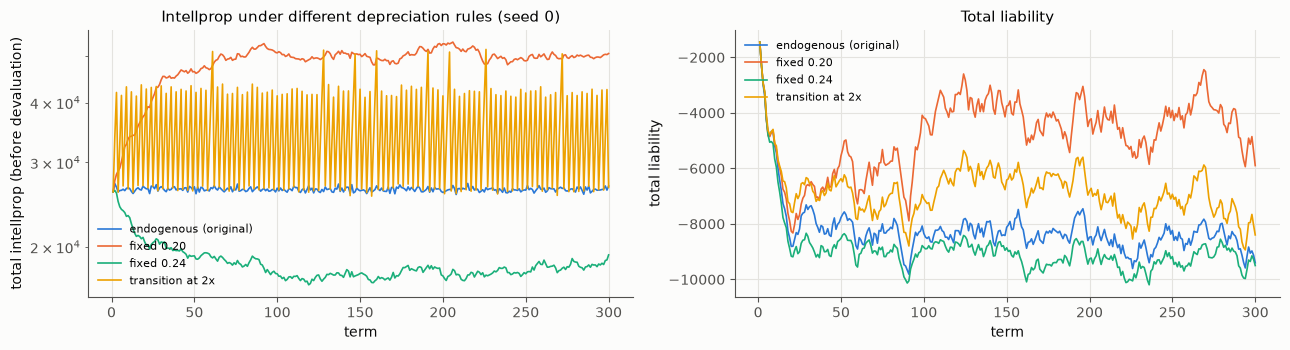


減耗のしかた                全 liability(後半)   その時間的な揺れ   贅沢品の需要   Rank Change Mean(300 期)
元のコード(内生的)                      -8529             485         500.3         910.9
定率 0.18                         36029            7395         510.7         919.8
定率 0.20                         -4136             909         500.2         928.2
定率 0.22                         -8422             538         500.4         914.7
定率 0.24                         -9261             368         500.4         890.8
遷移(2 倍で一挙に)                     -7242             653         500.4         926.1
遷移(1.5 倍で一挙に)                   -8039             556         500.3         920.2


In [40]:
import landip
importlib.reload(landip)
n_dv = 4 if FAST else 8
print('減耗のしかた                知財の総額(切り下げ前、50・100・200・300 期の中央値)')
DV = {}
for mode, x, lab in (('endogenous', 0, '元のコード(内生的)'), ('fixed', 0.18, '定率 0.18'), ('fixed', 0.20, '定率 0.20'), ('fixed', 0.22, '定率 0.22'),
                     ('fixed', 0.24, '定率 0.24'), ('transition', 2.0, '遷移(2 倍で一挙に)'), ('transition', 1.5, '遷移(1.5 倍で一挙に)')):
    R = pmap(landip.run_deval, [(s, dict(sma1.V01), mode, x, 300) for s in range(n_dv)])
    A = np.array([r[0] for r in R]); DV[lab] = (A, np.mean([r[1] for r in R]))
    print(f'{lab:22s}   ' + '  '.join(f'{v:10.0f}' for v in np.median(A[:, [49, 99, 199, 299], 0], 0)))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
for j, lab in enumerate(('元のコード(内生的)', '定率 0.20', '定率 0.24', '遷移(2 倍で一挙に)')):
    A = DV[lab][0]
    en = {'元のコード(内生的)': 'endogenous (original)', '定率 0.20': 'fixed 0.20', '定率 0.24': 'fixed 0.24', '遷移(2 倍で一挙に)': 'transition at 2x'}[lab]
    ax[0].plot(np.arange(1, 301), A[0, :, 0], color=PAL[j], lw=1.2, label=en)
    ax[1].plot(np.arange(1, 301), A[0, :, 1], color=PAL[j], lw=1.2, label=en)
ax[0].set(xlabel='term', ylabel='total intellprop (before devaluation)', title='Intellprop under different depreciation rules (seed 0)', yscale='log'); ax[0].legend(fontsize=8)
ax[1].set(xlabel='term', ylabel='total liability', title='Total liability'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print('\n減耗のしかた                全 liability(後半)   その時間的な揺れ   贅沢品の需要   Rank Change Mean(300 期)')
for lab, (A, rc) in DV.items():
    print(f'{lab:22s}   {A[:, 150:, 1].mean():12.0f}      {A[:, 150:, 1].std(1).mean():10.0f}      {A[:, 150:, 2].mean():8.1f}      {rc:8.1f}')

- **定率の減耗**でも、知財の総額は、ある水準で落ち着く。その水準は、率を下げるほど急に高くなる(0.24 で約 1.7 万、0.22 で約 2.7 万、0.20 で約 5 万、0.18 では 300 期で 20 万近く。元の 10 倍)。知財は、持っている知財に応じて積み上がるので、減耗の速さが積み上がる速さに近づくと、落ち着く水準が桁違いに大きくなり、それにつれて全 liability もプラスの側に大きく膨らむ(第 1 章の「切り下げなし」に近づく)。
- **元のコードの切り下げ**は、総額を最初の値(約 2 万)に保つ率を、毎期自動で選ぶ規則である。定率で言えば、0.22 前後にあたる。率が少し違うだけで、落ち着く水準が大きく変わる領域なので、作者が「無理矢理一定にする」と書いたのは、正しい判断だった。総額を決めてしまえば、率の選び方に悩まずに済む。
- **資産減耗遷移**(ふだんは減らさず、2 倍になったら一挙に戻す)では、知財は一期に 2 割ほど積み上がるので、数期で 2 倍になっては一挙に落ちる、速いのこぎりの刃になる。それでも、贅沢品の需要は変わらず(需要は第 3 章のとおり、所得で決まる)、全 liability も少しずれるだけである。変わるのは、知財の分布と、誰の財産が一挙に目減りするかである。ノート O で見たように、遷移は、なめらかな減耗とは違って、**目減りの時期と相手を、一挙に決める**。

### 5.2 土地には値段がない

第 2 章で見たとおり、2019 年のモデルの土地は、一単位 10 の値段が決まっていて、利子のつかない預金と同じである。土地の値段が上がって、持ち主の財産が増える、ということは起こらない。

土地に値段を付けてみる。土地の買い手は、借りずに払えるとき(貯蓄 − liability ≥ 値段)だけ買うことにし、毎期、払える買い手の数が、土地を持っている売り手の数より多ければ値段を上げ、少なければ下げる(手探りの値付け。ノート 1 の「模索過程」と同じ考え)。

In [41]:
%%writefile -a landip.py
def run_landprice(a):
    """(seed, オプション, 調整の速さ kappa, 期数) → 土地の値段を動かす版。土地の買い手は、借りずに払えるとき
    (貯蓄 − liability ≥ 値段)だけ買う。毎期、手元のお金が足りた買い手の数と、土地を持っていた売り手の数の差に応じて、
    値段を exp(kappa × (買い手 − 売り手) / 取引の数) 倍する。期ごとの (値段, 全 liability, 成立した数, 土地の時価の総額)。"""
    seed, kw, kappa, T = a
    P = sma1.params(**dict(kw, trials=T))
    e = sma1.Economy(P, seed); e.initialize()
    e.land_price, e.land_check = P.land_unit, True
    out = []
    for t in range(T):
        r = e.step()
        okb, oks, done = e.land_stat
        land_units = 0.0
        for p in e.players:
            land_units += p.land / P.land_unit
        out.append((e.land_price, r['total'][3], done, land_units * e.land_price))
        e.land_price *= np.exp(kappa * (okb - oks) / P.transactions_of_land)
    return np.array(out)

Appending to landip.py


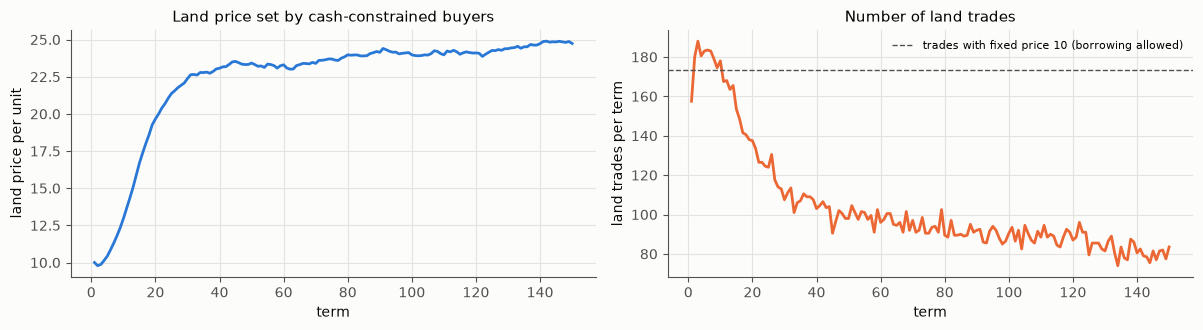

土地の値段: 10 期 12.9、50 期 23.4、150 期 24.7
成立した売り買い(一期、後半): 87 件、全 liability(後半): -8863、土地の時価の総額(150 期): 49138(値段 10 なら約 2 万)


In [42]:
importlib.reload(landip)
LP = np.array(pmap(landip.run_landprice, [(s, dict(sma1.V01, devaluation_of_intellprop=True), 0.2, 150) for s in range(n_dv)]))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
t_ = np.arange(1, 151)
ax[0].plot(t_, np.median(LP[:, :, 0], 0), color=PAL[0]); ax[0].set(xlabel='term', ylabel='land price per unit', title='Land price set by cash-constrained buyers')
ax[1].plot(t_, np.median(LP[:, :, 2], 0), color=PAL[1]); ax[1].axhline(np.mean([r['land_trans'][50:].mean() / 10 for r in RES['基本(知財の切り下げあり)']]), color=INK2, ls='--', lw=1, label='trades with fixed price 10 (borrowing allowed)')
ax[1].set(xlabel='term', ylabel='land trades per term', title='Number of land trades'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f'土地の値段: 10 期 {np.median(LP[:, 9, 0]):.1f}、50 期 {np.median(LP[:, 49, 0]):.1f}、150 期 {np.median(LP[:, 149, 0]):.1f}')
print(f'成立した売り買い(一期、後半): {LP[:, 75:, 2].mean():.0f} 件、全 liability(後半): {LP[:, 75:, 1].mean():.0f}、土地の時価の総額(150 期): {np.median(LP[:, -1, 3]):.0f}(値段 10 なら約 2 万)')

- 借りずに払える人だけが買うと、最初は買い手が多く、値段は上がっていく。値段が 24 前後になると、払える買い手と売り手の数が釣り合い、値段は落ち着く。売り買いの数は、借りて買える元のモデルの半分ほどになる。
- 土地の値段は、**人々の手元のお金(現金と貯蓄)の多さ**で決まる。土地の時価の総額は、約 2 万から 5 万近くに上がる。土地の数は変わらないのに、土地を持つ人の財産が 2.4 倍になる。ノート O の第 4 章で見た「評価の変化」(相手方のない、保有利得)である。

これは、第 6 章で扱う、作者の 2022 年の構想「担保としての土地」の入り口になる。土地の値段が手元のお金で決まり、土地を担保に借りられる額が土地の値段で決まるなら、借りたお金がまた土地の値段を押し上げる。その回路が、信用の増幅を生む(Kiyotaki and Moore 1997)。

### 5.3 知財は、得なのか、損なのか

作者は、その2 で、「これまでのところで知的財産を買うのは不利にしかならないことが明らかになってきた」と書き、それでも人が知財を買う理由として、「一発逆転」と「手元の現金」を考えた。

知財の市場全体で、何が起きているかを数える。後半の 50 期の、一期あたりの平均である。

In [43]:
%%writefile -a landip.py
def ip_returns(a):
    """(seed, オプション, 期数) → 知財の損得(後半の期の一期あたりの平均):
    stock: 切り下げのあとの知財の総額、sales: 知財の売り上げ(売り手が受け取った代金の合計)、
    premium: 買い手が払った値段を超えて積んだ評価額の合計、deval: 切り下げで消えた額、
    buyers_debtor: 知財の買い手のうち、買う前に借金のあった人の割合。"""
    seed, kw, T = a
    P = sma1.params(**dict(kw, trials=T))
    e = sma1.Economy(P, seed); e.initialize()
    acc = dict(sales=0.0, premium=0.0, deval=0.0, n_buy=0, n_debtor=0)
    def log(kind, *a_):
        if kind == 'ip':
            b, s, price, val = a_
            acc['sales'] += price; acc['premium'] += val - price
            acc['n_buy'] += 1; acc['n_debtor'] += (b.liability - price) > 0
        elif kind == 'ip_deval':
            acc['deval'] += a_[1]
    stock = []
    for t in range(T):
        if t == T // 2:
            for k in acc:
                acc[k] = 0
            e.log = log
        e.step()
        if t >= T // 2:
            s = 0.0
            for p in e.players:
                s += p.intellprop
            stock.append(s)
    n = T - T // 2
    return dict(stock=np.mean(stock), sales=acc['sales'] / n, premium=acc['premium'] / n, deval=acc['deval'] / n,
                buyers_debtor=acc['n_debtor'] / max(1, acc['n_buy']))

Appending to landip.py


In [44]:
importlib.reload(landip)
for lab, kw in (('その1 相当', dict(sma1.V01, devaluation_of_intellprop=True)), ('第四「現実的」', dict(devaluation_of_intellprop=True))):
    R = pmap(landip.ip_returns, [(s, kw, 100) for s in range(n_dv)])
    m = {k: np.mean([r[k] for r in R]) for k in R[0]}
    print(f'{lab}: 知財の総額(切り下げ後) {m["stock"]:7.0f}、売り上げ(買い手 → 売り手の現金) {m["sales"]:6.0f}(総額の {m["sales"] / m["stock"]:.0%})、'
          f'買い手が値段を超えて積んだ評価 {m["premium"]:6.0f}、切り下げで消えた額 {m["deval"]:6.0f}、買い手のうち買う前に借金のあった人 {m["buyers_debtor"]:.0%}')

その1 相当: 知財の総額(切り下げ後)   20078、売り上げ(買い手 → 売り手の現金)   4692(総額の 23%)、買い手が値段を超えて積んだ評価   1076、切り下げで消えた額   5768、買い手のうち買う前に借金のあった人 18%


第四「現実的」: 知財の総額(切り下げ後)   20078、売り上げ(買い手 → 売り手の現金)   6230(総額の 31%)、買い手が値段を超えて積んだ評価   1346、切り下げで消えた額   7576、買い手のうち買う前に借金のあった人 61%


知財の市場では、毎期、次のことが起きている。

1. 買い手は、知財の総額の 2〜3 割にあたる現金を、売り手に払う。
2. 買い手は、払った値段より 2 割ほど多い評価を、自分の知財に積む(買った瞬間の評価益)。
3. 期の終わりの切り下げで、その期に積まれた評価(値段 + 評価益)と、ちょうど同じ額が、全員の知財から消える。

つまり、**知財の評価は、積まれたのと同じ期のうちに、全体として消えてしまう**。知財の市場が経済全体に残すものは、買い手から売り手への現金の移動だけである。個人として見ると、知財を買う人は、確実に現金を払い、評価は毎期 2 割ずつ目減りしていく。知財を持つことの見返りは、あとで自分が売り手に選ばれたときに、持っている知財に応じた高い値段で売れることだけである。作者の言う「買うのは不利」は、平均としてはそのとおりで、知財は、**当たれば大きい、くじに近い資産**である(ノート O の第 3 章のペニーオークションや無尽講と同じ、くじと競りで集める仕組み)。

誰が買っているか。その1 相当の設定では、知財の買い手は現金のある人に偏っているので、買う前に借金のあった人は 2 割に満たない。第四「現実的」モデルでは、作者が「手元の現金を得るために、借金のある人が知財市場に参入する」と考えたとおり、買い手の 6 割が、買う前から借金を抱えている。

### 5.4 免許と懲罰的罰金

作者は、2020 年 2 月の「ひとこと」(cocolog:91702707)で、このモデルを使って、次の問いを考えた。

> 新自由主義的な国家資格・免許ではなく懲罰的罰金で十分だとする知識の蓄積への影響は、後者が最大級の蓄積者を出しうるが、平均的には前者のほうが平等的で新たな知見を生成しうるのではないか?

作者のモデル化は、次のとおりだった(その2 の版に、知財の買い手を「純資産の多い人」から選ぶオプションを足しただけ)。

- 基本: 純資産の多い人が、知財の多い人から買う。
- **懲罰的罰金**: 知財の価値がよくわからず、金に飽かせて買う。買い手の傾斜 0.8、売り手の傾斜 0.3。返済率 0.5(と 0.3)。
- **免許**: 貧しい人にも知財を得る機会があり、知財が吟味されて、高い知財が選ばれる。買い手の傾斜 0.3、売り手の傾斜 0.8。免許の取得に費用がかかるので、返済率を上げる。返済率 0.5(と 0.7)。

作者は、一回ずつ走らせてグラフを見比べ、「懲罰的罰金のほうが知財の最大値が大きそう」「免許のほうが知財の安い所が膨らんで平等そう」「知財の当期の増加は、免許のほうが大きい」「Liability は、免許のほうが現金の側の幅が大きい」と読み、「その根拠は薄く、はっきりとした数値ではなく、グラフの形をなんとなく見た結果からそう言っているだけである」と断っていた。

数で確かめる。乱数の種 20 通りで 50 期走らせ、作者が見た量を数える。

In [45]:
%%writefile -a landip.py
def gini(x):
    x = np.sort(np.asarray(x, float))
    n = len(x)
    return (2 * np.arange(1, n + 1) - n - 1).dot(x) / (n * x.sum())


def license_stats(a):
    """(seed, オプション, 期数) → 知財の分布と生成についての指標: 知財の Gini 係数、上位 1% の取り分、最大値、
    一期あたりの知財の生成(評価で積み上がった額の、切り下げ前の総額からの増分)、最も現金を持つ人の現金、
    贅沢品の購入数の平均、Rank Change Mean。"""
    seed, kw, T = a
    reps, e = sma1.simulate(seed, **dict(kw, trials=T))
    ip = np.array([p.intellprop for p in e.players])
    base = ip.sum()
    creation = np.mean([r['total'][0] - base for r in reps[T // 2:]])
    return dict(gini=gini(ip), top1=np.sort(ip)[-10:].sum() / ip.sum(), max=ip.max(), creation=creation,
                max_cash=-min(p.liability for p in e.players), lux=reps[-1]['lux_mean'], rank=reps[-1]['rank_change'])

Appending to landip.py


In [46]:
importlib.reload(landip)
pun = dict(devaluation_of_intellprop=True, sort_of_intellprop_buyer='rich', sort_of_intellprop_seller='ascend',
           coeff_of_intellprop_buyer=0.8, coeff_of_intellprop_seller=0.3, cash_on_hand='rigid')
lic = dict(pun, coeff_of_intellprop_buyer=0.3, coeff_of_intellprop_seller=0.8)
CASES = {'懲罰的罰金(返済率 0.5)': dict(pun, repayment_rate=0.5), '懲罰的罰金(返済率 0.3)': dict(pun, repayment_rate=0.3),
         '免許(返済率 0.5)': dict(lic, repayment_rate=0.5), '免許(返済率 0.7)': dict(lic, repayment_rate=0.7)}
n_lc = 8 if FAST else 20
print('設定                     知財の Gini   上位1%の取り分   知財の最大   知財の生成(一期)   最大の現金   贅沢品の購入数   Rank Change')
LC = {}
for lab, kw in CASES.items():
    R = pmap(landip.license_stats, [(s, kw, 50) for s in range(n_lc)])
    LC[lab] = R
    f = lambda k: (np.mean([r[k] for r in R]), np.std([r[k] for r in R]) / np.sqrt(len(R)))
    row = [f(k) for k in ('gini', 'top1', 'max', 'creation', 'max_cash', 'lux', 'rank')]
    print(f'{lab:20s}  ' + '  '.join(f'{m:.3g}±{s:.2g}' for m, s in row))

設定                     知財の Gini   上位1%の取り分   知財の最大   知財の生成(一期)   最大の現金   贅沢品の購入数   Rank Change


懲罰的罰金(返済率 0.5)        0.493±0.0015  0.0502±0.0008  125±3.8  6.84e+03±31  316±19  24.2±0.1  708±2


懲罰的罰金(返済率 0.3)        0.487±0.0022  0.0492±0.00058  125±3.6  6.84e+03±33  285±10  24.6±0.1  683±1.5


免許(返済率 0.5)           0.46±0.0023  0.0478±0.0011  127±5.1  7.41e+03±33  298±12  24.3±0.098  701±1.7


免許(返済率 0.7)           0.464±0.0023  0.0478±0.0005  124±4.2  7.43e+03±33  311±14  24.1±0.099  722±2.4


(± の後ろは、20 回の平均の標準誤差。)

- **知財の平等さ**: 免許のほうが、知財の Gini 係数がはっきり低い(0.46 前後と 0.49 前後)。作者の「免許のほうが平等そう」は、確かめられた。
- **新しい知見の生成**: 一期に評価として積まれる知財は、免許のほうが 1 割近く多い。作者の「知財の当期の増加は、免許のほうが大きい」も、確かめられた。高い知財を持つ人が売り手に選ばれやすいので、知財の値段が高くなり、評価として積まれる額も大きくなるからである。
- **最大級の蓄積者**: 知財の最大値と上位 1% の取り分には、差が見えない。作者の「懲罰的罰金のほうが最大値が大きそう」は、確かめられなかった。
- **現金の側の幅**: 最大の現金にも、はっきりした差はない。
- **贅沢品**: 差はほとんどない。作者の「違いがほとんどない」のとおりである。第 3 章で見たとおり、贅沢品の需要は所得で決まるので、知財の市場の作り方では変わらない。

作者の結論のうち、「免許のほうが平等で、新しい知見を多く生む」は、数で確かめても残る。「懲罰的罰金が最大級の蓄積者を出す」は、このモデルでは見えない。ただし、作者自身が書いたとおり、免許と懲罰的罰金の違いが、「誰が誰から知財を買うか」の傾斜の違いになる、というモデル化には、かなりの飛躍がある。このモデルで言えるのは、「**知財を吟味して高い知財を選ぶ市場のほうが、金に飽かせて買う市場より、知財が平等に行き渡り、評価の生成も大きい**」というところまでである。

### 5.5 この章のまとめ

1. 知財の切り下げは、総額を一定に保つ減耗率(定率で言えば 0.22 前後)を、毎期自動で選ぶ規則である。定率の減耗では、率を下げるほど、落ち着く水準が急に高くなる(0.18 で元の 10 倍)。資産減耗遷移(一挙の切り下げ)にしても、全体の流れはほとんど変わらず、変わるのは誰がいつ目減りするかである。
2. 土地に値段はなく、利子のつかない預金と同じである。借りずに払える人だけが買うようにして値段を動かすと、値段は手元のお金の多さで決まり、土地を持つ人に保有利得が生まれる。
3. 知財の評価は、積まれたのと同じ期のうちに、全体として消える。知財の市場が残すのは、買い手から売り手への現金の移動だけである。知財は、当たれば大きい、くじに近い資産である。
4. 2020 年の「免許と懲罰的罰金」の比較は、「免許(知財を吟味する市場)のほうが平等で、新しい知見を多く生む」という部分は確かめられ、「懲罰的罰金が最大級の蓄積者を出す」という部分は確かめられなかった。

### 5.6 Lean: 減耗する資産の定常の量と、値打ち

5.1 節で、知財の総額が減耗率のわずかな違いで大きく変わることを見た。毎期 I だけ新しく生まれ、割合 δ で減耗する資産の定常の量は I / δ で、δ の減る関数である(δ が小さいほど、わずかな違いが大きく効く)。資産の値打ちを「利回りの元 ÷ (金利 + 減耗)」と見れば、減耗しない土地は、減耗する知財より値打ちが高い。

In [47]:
%%writefile -a asset_market.lean
/-! ## 第 5 章 土地と知財: 減耗する資産の定常の量

毎期 I だけ新しく生まれ、割合 δ で減耗する資産(知財)の量 X_{t+1} = (1 − δ) X_t + I の定常の量は I / δ。 -/
theorem stock_steady {I δ : ℝ} (hδ : δ ≠ 0) : (1 - δ) * (I / δ) + I = I / δ := by
  field_simp; ring

/-- 定常の量 I / δ は、減耗が速いほど小さい(I ≥ 0)。減耗率のわずかな違いで、知財の総額が大きく変わる。 -/
theorem stock_steady_antitone {I δ₁ δ₂ : ℝ} (hI : 0 ≤ I) (h1 : 0 < δ₁) (h12 : δ₁ ≤ δ₂) : I / δ₂ ≤ I / δ₁ :=
  div_le_div_of_nonneg_left hI h1 h12

/-- 資産の値打ち = 利回りの元 ÷ (金利 + 減耗)。土地(δ = 0)は、減耗する知財(δ > 0)より値打ちが高い。 -/
theorem capitalized_value_antitone {y r δ : ℝ} (hy : 0 ≤ y) (hr : 0 < r) (hδ : 0 ≤ δ) : y / (r + δ) ≤ y / r :=
  div_le_div_of_nonneg_left hy hr (by linarith)

Appending to asset_market.lean


## 第 6 章 2021〜22 年の構想を式にする

作者は、2021 年 11 月 25 日から 2022 年 1 月 1 日にかけて、「ひとこと」(cocolog:93150989)に、2019 年の資産市場のモデルと `micro_economy_*.py` をどう統合するかの構想を、ブレインストーミングとして書き続けた。考えは、書きながら何度も向きを変えている。この章では、その流れに沿って、主な考えを一つずつ、次の四段で説明する。

1. 作者は何を言おうとしたか。
2. 経済学では、何にあたるか。
3. 式にすると、どうなるか(2019 年のモデルで試せるものは試す)。
4. 正しいところと、直すところ。

### 6.1 構想のあらまし

| 日付 | 考え |
|---|---|
| 2021-11-25 | **資本主義の基礎等式**: 株価の総額 = (全販売用在庫 + 投資による在庫) × 貯蓄率 × C。企業の優位性 = 在庫の多さが株価の根拠で、優位性の根拠は知財なので、**知財の総額 = 株価の総額**。2019 年のモデルでは、返済率が貯蓄率の代わりになる |
| 2021-11-27 | 日本のデフレと株安。貯蓄率ではなく「1/貯蓄率」ではないかと反転し、同じ日に「やはり修正前のほうが合っているかもしれない」と戻す。直接投資と間接投資の比 $q$ で、二つをつなぐ関数 $J$ を考える |
| 2021-11-30 | 基礎等式を、株価の総額 = G × (k1 + k2 J) + k3 と書き直す($G$ = 在庫 + 投資) |
| 2021-12-05 | 株価の総額 $R$ = 知財の総額 $R_2$ + α(「資本の力」)。結局、$R_2 = K_1' G + K_2'$。ピケティの $r > g$ との関係 |
| 2021-12-06〜07 | インフレを入れる: $R + M = K_1 G + K_2$($M$ は貨幣の供給)。災害の損失 $L$。そして、$M$ は**担保としての土地**の総額だ、と読み替える |
| 2021-12-09 | 江戸時代: 取引できる土地を増やすことが、貨幣を供給したのと同じになったのではないか。株価を維持するために利益を無理に出すことが「搾取」ではないか。知財を買った額の「1 割」を売った人が受け取る、という形 |
| 2021-12-09〜13 | **教育目的金融税**(金融所得課税の強化分を大学の研究費に充てる)。知財は「**自主研究**」で、知財の受け取りは**国庫**(国が吸い上げた企業の利益)から、知財の支払いは贅沢品の購入として扱う |
| 2021-12-14〜15 | 「変動資産」としての株式。配当と損失の分担。税率を動かして帳尻を合わせる。最後の手段としての「**現金税**」。そして、**micro_economy では商品市場の現金バランスを見ていなかった** |
| 2022-01-01 | 株主の必需品の購入は「公共事業」として、労働者一人あたりの必要量に足す |

### 6.2 資本主義の基礎等式

**1. 作者は何を言おうとしたか。** 株式の値打ちの総額は、経済が作り出して積み上げているもの(販売用の在庫と、投資で作られた設備)の大きさに比例する。そして、人々がお金を資産の側に回す割合(貯蓄率)が大きいほど、株価は高くなる。作者は、2019 年のモデルでは、賃金からの返済(商品市場から資産市場へお金が戻る流れ)が、貯蓄率の代わりになると考えた。

**2. 経済学では何にあたるか。** 最初の形(貯蓄率に比例)は、**ピケティの「資本主義の第二基本法則」**そのものである(Piketty 2014; Piketty and Zucman 2014)。

$$
\beta = \frac{W}{Y} = \frac{s}{g}
$$

長い目で見ると、富の総額 $W$ と所得 $Y$ の比 $\beta$ は、貯蓄率 $s$ を成長率 $g$ で割った値に近づく。作者の $C$ は $1/g$ にあたる。作者が「基礎等式」という言葉を選んだのも、ピケティが「基本法則」と呼んだのと、偶然重なっている(作者はこのとき、ピケティの本をまだ読んでいなかった)。

作者が 11 月 27 日に考えた反転(貯蓄率が大きいと株安)にも、経済学の対応物がある。**短い目で見ると**、人々が消費を減らして貯蓄を増やすと、企業の売り上げと利益が減り、株価が下がる。カレツキの利潤方程式(利潤 = 資本家の消費 + 投資 − 労働者の貯蓄、などの形。Kalecki 1942)や、「節約のパラドックス」である。作者の言う日本のデフレ(借金を返すことを優先して、株安になった)は、リチャード・クーの「バランスシート不況」(Koo 2008)にあたる。

つまり、二つの向きは、どちらかが間違いなのではなく、**時間の長さが違う**。長い目では、貯蓄が多いほど富は積み上がる($s/g$)。短い目では、貯蓄(返済)を急ぐと需要が減り、利益と株価が下がる。作者が直接投資と間接投資の比 $J$ で二つをつなごうとしたのは、この時間の長さの違いを、別の変数で表そうとしたものと読める。

**3. 式にすると。** 成長がなく($g = 0$)、資産が毎期 $\delta$ の割合で目減りするなら、ピケティの式は

$$
W = \frac{\text{資産に流れ込むお金(一期)}}{\delta}
$$

になる。2019 年のモデルで、知財の減耗を定率 $\delta = 0.22$ にして確かめる(第 5 章)。資産に流れ込むお金は、知財の売り買いの額(と、買い手が払った額を超えて積む評価益)である。賃金、返済率、贅沢品の値段を変えて、知財の総額と流れの比を見る。

In [48]:
%%writefile idea2021.py
"""idea2021.py -- 2021〜22 年の構想を、2019 年のモデルで試す: 基礎等式、担保としての土地、自主研究への国庫からの受け取り。"""
import numpy as np
import sma1


def ip_level(a):
    """(seed, オプション, 知財の定率の減耗 delta, 期数) → 後半の期の、知財の総額(切り下げ前)の平均と、知財の売り買いの額の平均。
    知財の総額(資産の値打ち)が、賃金や返済率(作者の言う貯蓄率の代わり)で変わるかを見る。"""
    seed, kw, delta, T = a
    P = sma1.params(**dict(kw, trials=T, devaluation_of_intellprop=False))
    e = sma1.Economy(P, seed); e.initialize()
    ip, tr = [], []
    for t in range(T):
        r = e.step()
        for p in e.players:
            p.intellprop *= (1 - delta)
        if t >= T // 2:
            ip.append(r['total'][0]); tr.append(r['ip_trans'])
    return np.mean(ip), np.mean(tr)

Overwriting idea2021.py


In [49]:
import idea2021
importlib.reload(idea2021)
print('設定                 知財の総額(資産の値打ち)   知財の売り買いの額(一期)   比(値打ち / 流れ)')
for lab, kw in (('基本', {}), ('賃金 40', dict(price_of_wages=40.0)), ('返済率 0.2', dict(repayment_rate=0.2)),
                ('返済率 0.9', dict(repayment_rate=0.9)), ('贅沢品の値段 10', dict(price_of_luxuries=10.0))):
    R = pmap(idea2021.ip_level, [(s, dict(sma1.V01, **kw), 0.22, 200) for s in range(n_dv)])
    W = np.mean([r[0] for r in R]); F = np.mean([r[1] for r in R])
    print(f'{lab:14s}        {W:10.0f}                {F:10.0f}                {W / F:6.2f}')

設定                 知財の総額(資産の値打ち)   知財の売り買いの額(一期)   比(値打ち / 流れ)


基本                         27177                      4844                  5.61


賃金 40                      17332                      3070                  5.65


返済率 0.2                    24887                      4444                  5.60


返済率 0.9                    27395                      4881                  5.61


贅沢品の値段 10                  21171                      3770                  5.62


- 資産の値打ちと、資産に流れ込むお金の比は、どの設定でも 5.6 前後で一定である。$(1 + \text{評価益の割合}) / \delta \approx 1.23 / 0.22 \approx 5.6$ で、ピケティの式の形がそのまま成り立つ。**作者の最初の形「値打ち = 流れ × 定数」は、2019 年のモデルの中でも正しい。**
- ところが、流れの大きさは、作者の考えたようには返済率(貯蓄率)で決まらない。返済率を 0.2 から 0.9 に変えると、流れは 1 割ほど増えるが、それより賃金や贅沢品の値段の効き方のほうが大きい。しかも、賃金を 30 から 40 に上げると、資産への流れは 3 分の 2 に**減る**(誰が借金を抱え、誰が売り手に選ばれるかが変わり、知財の値段が変わるため)。作者の基礎等式では、生産($G$)が大きいほど株価は高くなるはずだが、2019 年のモデルでは、その向きにはなっていない。2019 年のモデルの知財の値段は、売り手の持つ知財と土地だけで決まり、商品市場(作者の言う $G$)とは、間接にしかつながっていない。

**4. 正しいところと、直すところ。**

- 正しいところ: 資産の値打ちは、資産に流れ込むお金を、目減りの速さ(と成長率)で割ったものになる。作者の最初の直感は、ピケティの第二基本法則と同じである。
- 直すところ: 「1/貯蓄率」への反転は、短い目の需要の効果で、長い目の法則と混ぜないほうがよい。$J$ のような補間の関数を作るより、**長い目の式(ストック)と、短い目の式(フロー)を分けて書く**ほうが筋がよい。そして、2019 年のモデルには、生産($G$)から資産への流れをつなぐ規則がない。基礎等式を成り立たせたいなら、その規則を足す必要がある(作者は「株価は基礎等式で求めてコントロールする」と書いており、規則として足すつもりだった)。

### 6.3 知財の総額 = 株価の総額

**1. 作者は何を言おうとしたか。** 企業の株価は、その企業の優位性(他より多く作り、多く在庫を持てること)で決まり、優位性の根拠は知財にある。だから、知財の総額が、株価の総額そのものである。ただし、12 月 5 日には、株価には知財で説明できない部分 α(「資本の力」)があると考え直し、それも在庫 $G$ に比例するとすれば、結局 $R_2 = K_1' G + K_2'$(知財の総額は在庫で決まる)になる、と結論した。

**2. 経済学では何にあたるか。** 企業の市場での値打ちのうち、帳簿の上の有形の資本で説明できない部分は、**無形資本**(研究開発、ソフトウェア、ブランド、組織の知識)と呼ばれる。Hall(2001)は、株式市場の値打ちと有形資本の差から、無形資本の大きさを測った。Corrado, Hulten and Sichel(2009)は、アメリカの無形資本への投資が、有形資本への投資に並ぶ大きさであることを示した。Haskel and Westlake(2018)は、無形資本が中心になった経済を「資本なき資本主義」と呼んだ。作者の「知財の総額 = 株価の総額」は、**株価の総額 = 有形資本 + 無形資本(知財)**のうち、無形資本の側を強調した形である。

作者が気にしていた「知財を作った研究者は、固定給 + α しか受け取れない」(ビル・ゲイツと技術者)は、**知識の専有可能性**の問題である(Arrow 1962)。知識は、作った人が値打ちのすべてを手にすることが難しい。作者の言う「バッファ」は、知識の値打ちが、作った人ではなく、それを使う企業(と株主)に入る仕組みのことである。

**3. 式にすると。** 作者の 12 月 5 日の式は、

$$
R = \alpha(G) + R_2, \qquad R = K_1 G + K_2 \quad\Longrightarrow\quad R_2 = (K_1 - K_4) G + K_2
$$

($\alpha = K_4 G$)である。作者自身が注意したとおり、この式は、α の $G$ に対する比 $K_4$ が一定である限りで意味を持ち、$K_4$ が大きく揺れるなら、$R_2$ は $G$ から決まらなくなる。

**4. 正しいところと、直すところ。**

- 正しいところ: 株価の総額のうち、有形資本で説明できない大きな部分を、知財(無形資本)が占める、という見方は、今の実証とも合う。知財を作った人が値打ちを手にできない、という問題意識も正しい。
- 直すところ: 「知財の総額 = 株価の総額」を等式にするのは強すぎる。株価の総額 = 有形資本の値打ち + 無形資本の値打ち + 期待(将来の利益の見込み)とし、知財は無形資本の一部、と置くのがよい。2019 年のモデルの知財は、6.2 で見たとおり、売り手の持つ知財と土地で値段が決まり、企業の利益とはつながっていない。作者が 12 月 13 日にたどり着いた「知財の受け取りは、国が吸い上げた企業の利益から」という形(6.5)が、そのつながりを作る試みだった。

### 6.4 担保としての土地

**1. 作者は何を言おうとしたか。** 基礎等式にインフレ(貨幣の供給 $M$)を入れようとして、作者は、$M$ はどれだけ借金できるかにかかわる量で、それは担保としての資産、つまり土地の総額だと読み替えた(12 月 7 日)。そして、江戸時代に、米の増産がデフレではなく経済成長を生んだのは、取引できる土地が増えて、それが担保になり、貨幣を供給したのと同じことになったからではないか、と考えた(12 月 9 日)。

**2. 経済学では何にあたるか。** 土地を担保に借りる経済では、土地の値段が上がると借りられる額が増え、借りたお金で土地が買われて、値段がさらに上がる。Kiyotaki and Moore(1997)の「信用循環」の模型である。1980 年代後半の日本の土地バブルは、その典型として知られる。作者の「土地 = 貨幣の供給」は、担保が信用を生み、信用が(銀行の預金として)お金になる、という信用創造の仕組みを、土地の側から言ったものである。

**3. 式にすると。** 第 5 章の、土地の値段を動かす版に、担保を入れる。土地も知財も、買ったあとの正味の借り(liability − 貯蓄 + 値段)が、持っている土地の時価 × 掛け目 $\theta$ 以下のときだけ買える。$\theta = 0$ なら、借りずに払えるときだけ買える(第 5 章と同じ)。$\theta$ を 0、0.5、1 にして、次の二つを試す。

- 60 期目に、全員から一律に 10 を取る(全員の liability に 10 を足す)。土地の値段は、どう動くか。
- 60 期目に、土地を持たない人のうち 200 人に、土地を一単位ずつ配る(取引できる土地を増やす。作者の江戸時代の考え)。借金の合計は、どう変わるか。

In [50]:
%%writefile -a idea2021.py
def run_collateral(a):
    """(seed, オプション, 担保掛け目 theta, ショック, 期数) → 土地を担保にした借入の版。
    土地の値段は第 5 章のとおり、払える買い手と売り手の数の差で動く。土地も知財も、買ったあとの正味の借り
    (liability − 貯蓄 + 値段)が、土地の時価 × theta 以下のときだけ買える(theta = 0 なら、借りずに払えるときだけ)。
    ショック: (期, 種類, 大きさ)。種類 'tax' は全員の liability に大きさを足す(全員から一律に取る)、
    'land' は土地を持たない人のうち大きさ人に一単位ずつ土地を配る(取引できる土地を増やす)。
    期ごとの (土地の値段, 全 liability, 借金の合計, 成立した土地の売り買い, 知財の売り買いの額) を返す。"""
    seed, kw, theta, shock, T = a
    P = sma1.params(**dict(kw, trials=T))
    e = sma1.Economy(P, seed); e.initialize()
    e.land_price = P.land_unit
    unit = P.land_unit
    def ok(kind, b, price):
        return b.liability - b.savings + price <= theta * e.land_price * b.land / unit
    e.buy_ok = ok
    rng = np.random.default_rng(seed)
    out = []
    for t in range(T):
        if shock and t == shock[0]:
            if shock[1] == 'tax':
                for p in e.players:
                    p.liability += shock[2]
            elif shock[1] == 'land':
                cand = [p for p in e.players if p.land < unit]
                for k in rng.permutation(len(cand))[:shock[2]]:
                    cand[k].land += unit
        r = e.step()
        okb, oks, done = e.land_stat
        debt = 0.0
        for p in e.players:
            debt += max(p.liability, 0.0)
        out.append((e.land_price, r['total'][3], debt, done, r['ip_trans']))
        e.land_price *= np.exp(0.2 * (okb - oks) / P.transactions_of_land)
    return np.array(out)

Appending to idea2021.py


掛け目 θ   土地の値段(後半)   借金の合計(後半)   土地の売り買い   課税ショック後の値段(ショックなしとの比: 65・80・100 期)   土地を増やした後の借金の増加(65・80・100 期)


  0.0          20.2                944            157          0.891 / 0.979 / 1.004                                 -43 /   -42 /   -36


  0.5          31.6               3125             72          0.967 / 0.983 / 1.006                                 582 /   180 /   284


  1.0          34.7               3648             61          0.974 / 0.952 / 0.977                                 752 /   484 /   417


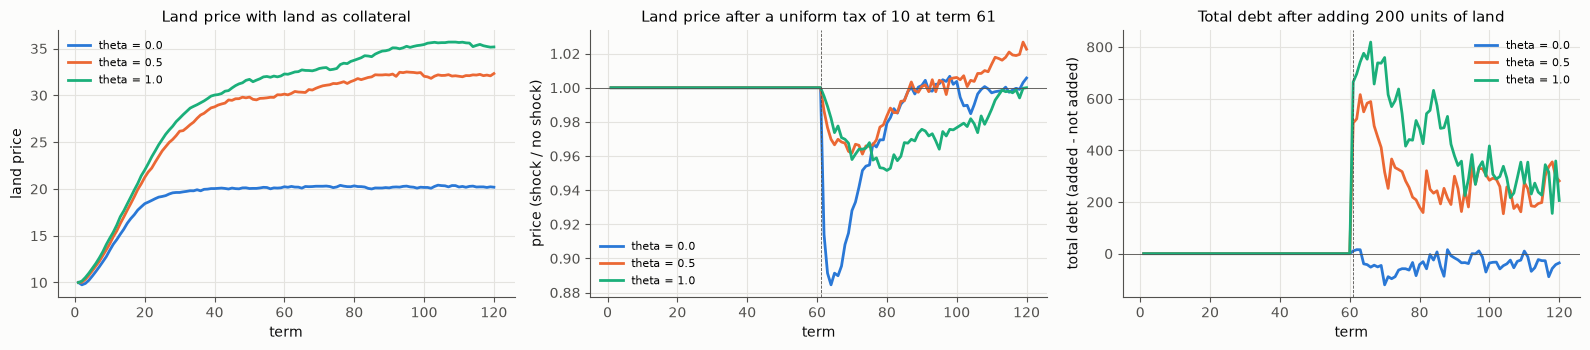

In [51]:
importlib.reload(idea2021)
b2 = dict(sma1.V01, devaluation_of_intellprop=True)
fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
t_ = np.arange(1, 121)
print('掛け目 θ   土地の値段(後半)   借金の合計(後半)   土地の売り買い   課税ショック後の値段(ショックなしとの比: 65・80・100 期)   土地を増やした後の借金の増加(65・80・100 期)')
for j, th in enumerate((0.0, 0.5, 1.0)):
    R0 = np.array(pmap(idea2021.run_collateral, [(s, b2, th, None, 120) for s in range(n_seed)]))
    R1 = np.array(pmap(idea2021.run_collateral, [(s, b2, th, (60, 'tax', 10.0), 120) for s in range(n_seed)]))
    R2 = np.array(pmap(idea2021.run_collateral, [(s, b2, th, (60, 'land', 200), 120) for s in range(n_seed)]))
    ax[0].plot(t_, np.median(R0[:, :, 0], 0), color=PAL[j], label=f'theta = {th}')
    ratio = np.median(R1[:, :, 0] / R0[:, :, 0], 0); ddebt = np.median(R2[:, :, 2] - R0[:, :, 2], 0)
    ax[1].plot(t_, ratio, color=PAL[j], label=f'theta = {th}')
    ax[2].plot(t_, ddebt, color=PAL[j], label=f'theta = {th}')
    print(f'  {th:3.1f}        {np.median(R0[:, 60:, 0]):6.1f}            {np.median(R0[:, 60:, 2]):7.0f}          {R0[:, 60:, 3].mean():5.0f}          '
          f'{ratio[64]:.3f} / {ratio[79]:.3f} / {ratio[99]:.3f}                               {ddebt[64]:5.0f} / {ddebt[79]:5.0f} / {ddebt[99]:5.0f}')
ax[0].set(xlabel='term', ylabel='land price', title='Land price with land as collateral'); ax[0].legend(fontsize=8)
ax[1].axhline(1, color=INK2, lw=0.6); ax[1].axvline(61, color=INK2, lw=0.6, ls='--')
ax[1].set(xlabel='term', ylabel='price (shock / no shock)', title='Land price after a uniform tax of 10 at term 61'); ax[1].legend(fontsize=8)
ax[2].axhline(0, color=INK2, lw=0.6); ax[2].axvline(61, color=INK2, lw=0.6, ls='--')
ax[2].set(xlabel='term', ylabel='total debt (added - not added)', title='Total debt after adding 200 units of land'); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

- **担保は、土地の値段と借金を押し上げる。** 掛け目を 0 から 0.5、1 に上げると、土地の値段は約 20 から 30 台に、借金の合計は約 1000 から 3000 台に上がる。借りて土地を買えるので、買い手が増え、値段が上がり、値段が上がると、さらに借りられる。
- **取引できる土地を増やすと、担保のある経済でだけ、借金が増える。** 掛け目 0 では、土地を配っても借金は増えない。掛け目 0.5、1 では、配った直後から借金が数百増え、その後も増えたままである。作者の「取引可能な土地を増やすことで、それが担保たりうることになり、貨幣供給したのと同じになった」は、この模型でも、その形のとおりに現れる。
- **ショックへの反応は、教科書の「増幅」とは少し違う。** 一律の課税のあと、掛け目 0 の経済では、土地の値段が一度に 1 割ほど下がり、20 期ほどで戻る。担保のある経済では、最初の下がり方は小さいが、掛け目 1 では下がり方が遅れて長引く。Kiyotaki and Moore の模型では、担保の値下がりが借入を減らし、それがさらに値下がりを呼ぶ増幅が中心にある。この簡単な版では、借入の制約にかかっている人が少なく、増幅は「大きく下がる」より「長く続く」形で現れる。どれだけ増幅するかは、借入の上限にかかっている人の割合(てこの大きさ)で決まる。

**4. 正しいところと、直すところ。**

- 正しいところ: 土地が担保になると、土地は信用(お金)を生む。取引できる土地を増やすことは、担保のある経済では、貨幣の供給を増やすのに近い。作者の江戸時代の読みは、この意味で筋が通っている(ただし、歴史としての検証は、ここではしていない)。
- 直すところ: 作者の式では、$M$(土地の総額)を、株価の総額と同じ側に足している。担保の効果は、値打ちの足し算ではなく、**借りられる上限**として効く。式としては、$R + M = \ldots$ より、「借金 ≤ 掛け目 × 土地の時価」という**不等式の制約**として書くほうがよい。第 3 章の「自然な借入制約」(毎期返せる額 ÷ 利率)と並ぶ、もう一つの借入の上限である。

### 6.5 自主研究と、国庫からの受け取り

**1. 作者は何を言おうとしたか。** 2019 年のモデルの知財の売り買いは、現実には観察しにくい。作者は 12 月 13 日に、こう組み替えた。知財の購入は「自主研究」という贅沢品の購入であり、知財の売り手は、買い手からではなく、**国庫**(国が吸い上げた企業の利益)から、知財の値打ちに応じて受け取る。そして、その政策的な示唆として、金融所得課税の強化分を大学の研究費に充てる「**教育目的金融税**」を提案した。さらに、作者は、国庫からの持ち出しが企業から吸い上げた利益を超えれば、その分はシステムの中の「純現金増」になり、それを打ち消すには税(最後は「現金税」)が要る、と見抜いていた。

**2. 経済学では何にあたるか。** 知識は、使っても減らず、作った人が値打ちを専有しにくい公共財に近い。だから、市場に任せると、研究は過小になる(Arrow 1962)。公的な研究費は、その補正である。作者の「教育目的金融税」は、知識が生んだ企業の利益(株価)の一部を、知識を生む側(大学)に戻す、**目的税による循環**の提案である。

そして、作者が見抜いた「純現金増」は、ストック・フロー一貫モデルの基本の恒等式、**政府の赤字 = 民間の黒字**(海外がなければ)そのものである(Godley and Lavoie 2007)。

**3. 式にすると。** 2019 年のモデルでは、第 2 章で見たとおり、FIRM(企業)は毎期、失業手当の分だけ黒字になり、そのお金を使わずに貯めていた。そこで、毎期、FIRM の黒字の一定の割合を、その期に知財を売った人に、売った額に比例して配る(国が企業の利益を吸い上げて、自主研究の成果に払う)。割合を 0、0.5、1 にする。

In [52]:
%%writefile -a idea2021.py
def run_research(a):
    """(seed, オプション, 割合 share, 期数) → 自主研究への国庫からの受け取りの版。毎期、FIRM の黒字
    (必需品 + 失業手当 + 贅沢品 − 賃金。国が吸い上げる企業の利益)の share の割合を、その期に知財を売った人に、
    売った額に比例して配る(配った分だけ、受け取った人の liability が減る)。期ごとの (贅沢品の需要, 全 liability, 正味の金融資産 A)と、
    最後の期の正味資産の Gini 係数。"""
    seed, kw, share, T = a
    P = sma1.params(**dict(kw, trials=T))
    e = sma1.Economy(P, seed); e.initialize()
    N = P.population
    sales = {}
    def log(kind, *a_):
        if kind == 'ip':
            s = a_[1]
            sales[s] = sales.get(s, 0.0) + a_[2]
    e.log = log
    out = []
    for t in range(T):
        sales.clear()
        r = e.step()
        need = P.price_of_necessaries * P.needs_of_necessaries
        profit = need * N + e.luxuries * r['demand'] - e.wages * r['working']
        tot = sum(sales.values())
        if tot > 0 and share > 0:
            for s, v in sales.items():
                s.liability -= share * profit * v / tot
        L, S = 0.0, 0.0
        for p in e.players:
            L += p.liability; S += p.savings
        out.append((r['demand'], L, S - L))
    nw = np.sort([p.net_asset() for p in e.players])
    nw = nw - min(0.0, nw.min())
    g = (2 * np.arange(1, N + 1) - N - 1).dot(nw) / (N * nw.sum())
    return np.array(out), g

Appending to idea2021.py


配る割合   贅沢品の需要(後半)   正味の金融資産 A の一期の増え方   全 liability(最後)   正味資産の Gini 係数


  0.0          494.6                   -1.2                     -8262          0.163


  0.5          776.6                  463.5                    -87493          0.418


  1.0          943.2                 5163.7                   -518795          0.436


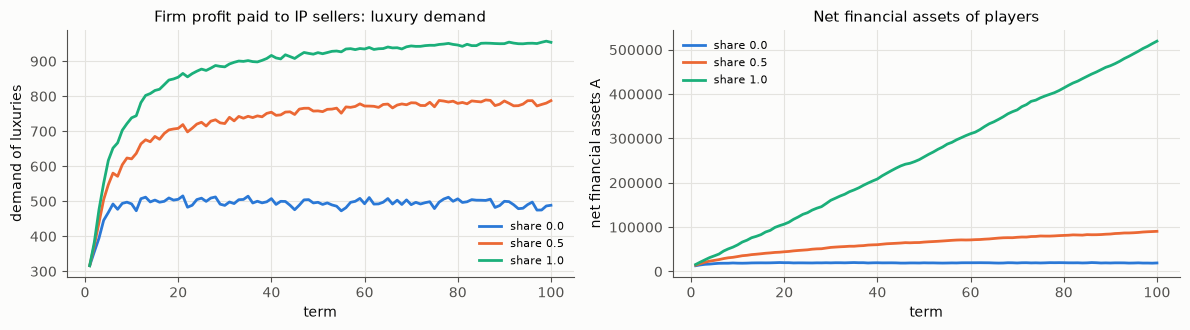

In [53]:
importlib.reload(idea2021)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
t_ = np.arange(1, 101)
print('配る割合   贅沢品の需要(後半)   正味の金融資産 A の一期の増え方   全 liability(最後)   正味資産の Gini 係数')
for j, sh in enumerate((0.0, 0.5, 1.0)):
    R = pmap(idea2021.run_research, [(s, b2, sh, 100) for s in range(n_dv)])
    A = np.array([r[0] for r in R]); g = np.mean([r[1] for r in R])
    ax[0].plot(t_, A[:, :, 0].mean(0), color=PAL[j], label=f'share {sh}')
    ax[1].plot(t_, np.median(A[:, :, 2], 0), color=PAL[j], label=f'share {sh}')
    print(f'  {sh:3.1f}        {A[:, 50:, 0].mean():7.1f}               {np.mean((A[:, -1, 2] - A[:, 50, 2]) / 49):8.1f}                {np.median(A[:, -1, 1]):10.0f}          {g:.3f}')
ax[0].set(xlabel='term', ylabel='demand of luxuries', title='Firm profit paid to IP sellers: luxury demand'); ax[0].legend(fontsize=8)
ax[1].set(xlabel='term', ylabel='net financial assets A', title='Net financial assets of players'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

- 企業の利益を自主研究の成果に配ると、そのお金は人々の手に戻り、**贅沢品の需要が増える**(割合 0.5 で約 780)。第 2 章で見た「FIRM が黒字を使わずに貯める」漏れが、ふさがれるからである。ただし、割合 0.5 でも、正味の金融資産 $A$ は少しずつ増え続ける。お金を受け取るのは知財を売った人に偏っていて、その人たちは一人一期に一つという贅沢品の上限にかかり、受け取ったお金を使いきれないからである。
- 全額を配ると、正味の金融資産 $A$ は、毎期 5000 ほど増え続ける。これは、ちょうど失業手当(国の赤字)の額である。第 3 章の恒等式で、配る前は $\Delta A = 10W - 15D$ だったものが、全額を配ると $\Delta A = 10W - 15D + (\text{企業の黒字}) = 20 \times (\text{失業者の数})$ になる。**国の赤字が、そのまま人々の黒字になる。** 作者の「国庫からの持ち出しは、システム内に純現金増となる」は、正確だった。
- 増えたお金は、贅沢品の需要を押し上げるが、需要には上限がある(一人一期に一つ)。需要が上限に近づくと、それ以上のお金は、使われずに現金として積み上がる(全 liability が大きくマイナスになる)。作者が 2026 年に書いた「在庫だけが積み上がる = デフレ = あるのに買えない」とは向きが逆だが、**お金が積み上がっても、買えるものがなければ流れは増えない**、という同じ構造である。
- 配られるのは知財を売った人だけなので、正味資産の格差(Gini 係数)は大きく広がる。

**4. 正しいところと、直すところ。**

- 正しいところ: 企業の利益(知識が生んだ値打ち)を、知識を生む側に戻すという循環の発想は、知識の専有可能性の問題への、筋のよい答えである。国庫からの持ち出しが民間の現金になる、という指摘は、ストック・フロー一貫の恒等式そのもので、正しい。
- 直すところ: 戻したお金が、どこで、何に使われるかまで、帳簿で追う必要がある。この模型では、配られた人の手元で現金が積み上がり、格差が広がった。作者が考えた「現金税」(現金と借金の合計が偏れば、多いほうを減らす)は、2019 年のモデルにすでにある `devaluation_of_liability`(Erosion と返済の差を、借金か現金から按分して消す)と同じものである。目的税で集めて配るなら、どこから取るか(金融所得)と、どこに配るか(研究)の両方を、同じ帳簿の上で釣り合わせることになる。

### 6.6 地代、利子、配当、変動資産、現金税

作者は、12 月 13〜15 日に、2019 年のモデルに足すべきものとして、地代、利子、配当(と損失の分担)、「変動資産」としての株式、税率の調整、現金税を考えた。

- **地代と利子は、資産市場の中で完結する**(作者)。土地を持つ人が皆から地代を受け取り、借金に利子が付き、現金に利子が付いても、それは人々のあいだの移転で、商品市場には直接関係しない。これは正しい。第 3 章の恒等式で言えば、人々のあいだの移転は正味の金融資産 $A$ の合計を変えないので、**贅沢品の需要の水準は変わらない**。変わるのは、分配と、誰が借金を返しきれなくなるかである。第 3.6 節で見たとおり、利子を付けると、「毎期返せる額 ÷ 利率」を超えた借金は返しきれなくなる。
- **変動資産**としての株式は、信用循環モデル(credit_simulation_v6)の「株式的な富」 E(期待利潤を金利で割った値)にあたる。作者が考えた「配当は企業の利益の分配、損失も株主が分け合う」は、v6 の E の作り方と同じ向きである。この接続は、第 7 章で小さく扱い、本格的には別のノート(資産市場つきの v6)で扱う。
- **一本の税率を動かして帳尻を合わせる**(作者)のは、財政のルール(税率を、ある目標に合わせて自動的に動かす)である。信用循環モデルの財政ルールと同じ発想である。

### 6.7 この章のまとめ

| 構想 | 経済学では | 正しいところ | 直すところ |
|---|---|---|---|
| 資本主義の基礎等式 | ピケティの第二基本法則 $\beta = s/g$。反転した形は、カレツキの利潤と節約のパラドックス(短い目) | 資産の値打ち = 流れ ÷(減耗 + 成長)。2019 年のモデルでも成り立つ | 長い目と短い目を分けて書く。生産から資産への流れの規則を足す |
| 知財の総額 = 株価の総額 | 無形資本(Hall、Corrado ほか)、知識の専有可能性(Arrow) | 株価の多くを無形資本が占める | 等式ではなく、株価 = 有形 + 無形 + 期待 |
| 担保としての土地 | Kiyotaki–Moore の信用循環 | 土地を増やすと、担保のある経済でだけ信用が増える(江戸時代の読み) | 値打ちの足し算ではなく、借入の上限の不等式 |
| 自主研究と国庫 | 公共財としての知識、目的税、政府の赤字 = 民間の黒字 | 企業の利益を知識に戻す循環。国庫の持ち出しが純現金増になる指摘 | 戻したお金の行き先と、格差まで帳簿で追う |
| 地代・利子・配当・現金税 | 資産市場の中の移転、財政ルール | 移転は需要の水準を変えない | 利子には借入の上限と貸倒れが要る |

作者は、このブレストを「実際のシミュレーションのプログラムを書くのは、相当先になりそう」と結んでいた。この章の模型は、そのプログラムの、ごく小さな最初の一歩である。

## 第 7 章 信用循環モデルとつなぐ

作者は、2019 年の資産市場のモデルを `micro_economy_*.py` と組み合わせるつもりだった。その後、作者は 2026 年に、信用創造の模型(信用循環モデル、credit_simulation_v6。以下 v6)を作った。この章では、2019 年のモデルと v6 を、小さくつなぐ。本格的な「資産市場つきの v6」は、別のノートで扱う(作者の方針)。ここでは、次の三つをする。

1. v6 の「株式的な富」 E を、作者の 2021 年の構想(知財の総額 = 株価の総額)の目で読む。
2. v6 に、土地を担保として足した小さな版を作り、作者の「担保としての土地」(第 6.4 節)が、v6 の景気の循環をどう変えるかを見る。
3. 2019 年のモデルと v6 の違いを整理し、別のノートでの設計の方針を書く。

### 7.1 v6 のおさらい

v6 は、企業・労働者・金利生活者・銀行・政府の五つの部門からなる、信用創造の模型である。この章にかかわる部分は、次の三つである。

- **株式的な富** $E$: 企業の期待利潤を、貸出金利とリスクプレミアムの和で割った値(期待利潤の資本還元)。株価の総額にあたる。$E$ と資本 $K$ の比 $q = E/K$ は、トービンの $q$ である。
- **担保制約**: 企業が借りられる上限は、$\lambda\,(E + K)$。借入がこれを超えると、返済を迫られる。
- **在庫維持能力の喪失**($\kappa$): $E$ が縮むと、資本(在庫・設備・知識)の目減りが速くなる。評価の目減りが、実物を壊す。

v6 のノートでは、投資が $q$ に反応する設定($g_q = 0.03$)で、「10 年目から 10 年かけてリスクプレミアムが下がる(ユーフォリア)、25 年目に政策金利を 6% に上げる」というシナリオで、好況と崩れを示した。この章でも、同じシナリオを使う。

### 7.2 v6 を取ってきて、土地を足す

v6 の Python の参照実装(`python/sims.py`)を、GitHub から決まった版(commit)で取ってきて、sha256 を確かめて読み込む。その `simulate_cm` に、土地を足した版 `simulate_land` を作る。

- 土地の量は一定で、減価しない。土地は、所得の一定の割合(5%)を生むと見なし、その期待値を割引率(貸出金利 + リスクプレミアム)で割った値を、**基礎的な値段**とする。
- 土地には**泡**が乗りうる。基礎的な値段の伸びを外挿して泡の倍率が膨らみ、時間とともに萎む(ノート O の第 6 章の泡と同じ形)。
- 土地は、担保として借入の上限に加わる: $\lambda\,(E + K) + \lambda_T V_T$。
- 土地は生産にも所得の流れにも入らない(地代は、すでに利潤の中にある帰属分と見なす)。だから、$\lambda_T = 0$ なら、v6 とぴったり同じ計算になる。

まず、それを確かめる。

In [54]:
%%writefile cm_land.py
"""cm_land.py -- 信用循環モデル v6(credit_simulation_v6 の simulate_cm)に、土地を担保として足した小さな版。"""
import os, hashlib, importlib.util, urllib.request
import numpy as np

V6_COMMIT = 'b73a367a647bc611a2b14fb8cf75d7cb5bb58b0b'
V6_SHA256 = 'aea5e3b3464edfc3252a8ab8c54281899e7471e521feda6d185a20ba3a41c5ab'


def load_v6(cache='orig_cache'):
    """credit_simulation_v6 の python/sims.py を、決まった版で取ってきて(sha256 を確かめて)、モジュールとして読み込む。"""
    os.makedirs(cache, exist_ok=True)
    path = os.path.join(cache, 'sims_v6.py')
    if not os.path.exists(path):
        url = f'https://raw.githubusercontent.com/JRF-2018/credit_simulation_v6/{V6_COMMIT}/python/sims.py'
        with urllib.request.urlopen(url, timeout=60) as r:
            open(path, 'wb').write(r.read())
    if hashlib.sha256(open(path, 'rb').read()).hexdigest() != V6_SHA256:
        raise ValueError('sims.py: sha256 が違う')
    spec = importlib.util.spec_from_file_location('sims_v6', path)
    m = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(m)
    return m

Overwriting cm_land.py


In [55]:
%%writefile -a cm_land.py
V6 = load_v6()
LAND_DEFAULT = dict(V6.CM_DEFAULT,
                    lam_T=0.0,      # 土地の担保の掛け目: 借入上限 = lam·(E + K) + lam_T·V_T
                    rho_T=0.05,     # 土地の地代(帰属家賃のように、所得 Y のこの割合を土地のおかげと見なす。所得の流れには足さない)
                    phi_T=0.0,      # 土地の泡: 基礎的な値段の伸びを外挿して、泡の倍率 exp(b_T) が膨らむ強さ
                    tau_T=3.0)      # 土地の泡が萎む時定数(年)
LAND_KEYS = V6.CM_KEYS + ['V_T', 'b_T']


def simulate_land(**kw):
    """v6 の simulate_cm と同じ計算に、土地を足したもの。土地の値段 V_T = 基礎的な値段 × exp(b_T)。
    基礎的な値段 = 期待地代 / (r_L + prem)、期待地代 = rho_T × 期待所得。泡 b_T は、基礎的な値段の伸びを外挿して膨らみ
    (phi_T × 伸び)、時定数 tau_T で萎む(ノート 1.5 の泡と同じ形)。
    土地は担保として借入上限に加わるだけで、生産にも所得の流れにも入らない(地代は帰属分として、すでに利潤の中にあると見なす)。
    lam_T = 0 なら、v6 の simulate_cm とぴったり同じ計算になる。"""
    p = {**LAND_DEFAULT, **kw}
    dt = p['dt']
    n = int(round(p['T'] / dt))
    K, L, B = float(p['K0']), float(p['L0']), float(p['B0'])
    omega = p['omega']
    r_L0 = (p['r_cb'] + p['spread']) / (1 - p['rho'])
    Pi_e = (1 - omega) * K / p['v'] * 0.9 - p['d0'] * K - r_L0 * L
    Y_e, b_T, F_prev = 0.9 * K / p['v'], 0.0, None
    if p['init'] == 'steady':
        pre = simulate_land(**{**kw, 'init': None, 'kappa': 0.0, 'shocks': (), 'T': 300.0,
                               'regime': 'rate', 'phillips': 0.0})
        f = K / pre['K'][-1]
        L, B, Pi_e = pre['L'][-1] * f, pre['B'][-1] * f, pre['Pi'][-1] * f
        Y_e, b_T = pre['Y'][-1] * f, pre['b_T'][-1]
    Pi_prev, loss_rate, delta, E_prev = Pi_e, 0.0, p['d0'], None
    g_e = pre['g'][-1] if p['init'] == 'steady' else 0.0
    a, Pop = 1.0, (0.9 * K / p['v']) / p['emp0']
    H = (L + B) * (p['rho'] + p['cu0']) / (1 - p['rho'])
    out = {k: np.empty(n) for k in LAND_KEYS}
    shocks = [(sh[0], sh[1], sh[2] if len(sh) > 2 else 0.0, {}) for sh in p['shocks']]
    softmin = V6.softmin
    for i in range(n):
        t = i * dt
        for ts, ch, dur, base in shocks:
            if t >= ts - dt / 2 and t <= ts + dur + dt / 2:
                if not base:
                    base.update({k: p[k] for k in ch})
                w = 1.0 if dur <= 0 else min(1.0, (t - ts + dt / 2) / dur)
                for k, v in ch.items():
                    p[k] = base[k] + w * (v - base[k]) if isinstance(v, float) else v
                if 'omega' in ch:
                    omega = p['omega']
        Y_k = K / p['v']
        Y_n = a * Pop
        Y_p = softmin(p['u_max'] * Y_k, Y_n, 0.01 * Y_n) if p['labor_cap'] else p['u_max'] * Y_k
        r_L = (p['r_cb'] + p['spread']) / (1 - p['rho']) + p['spread_loss'] * min(loss_rate, 0.1)
        r_B = p['r_cb']
        disc = r_L + p['prem'] - p['g_exp'] * g_e
        wE = 0.001 * K
        E = wE * np.logaddexp(0.0, Pi_e / wE) / (0.005 * np.logaddexp(0.0, disc / 0.005) + 0.005)
        if E_prev is not None:
            stress = max(0.0, -(E - E_prev) / max(E_prev, 1e-9)) / dt
            delta = p['d0'] * (1 + p['kappa'] * stress)
        E_prev = E
        # 土地: 期待地代を割引率で資本還元した基礎的な値段に、泡の倍率をかける
        F_T = p['rho_T'] * Y_e / (0.005 * np.logaddexp(0.0, disc / 0.005) + 0.005)
        V_T = F_T * np.exp(b_T)
        u_prev = out['u'][i - 1] if i > 0 else 0.9
        g_net = (p['g0'] + p['g1'] * Pi_prev / K + p['g2'] * (u_prev - 0.85)
                 + p['g_q'] * (E / K - p['q_ref']))
        I_des = K * max(0.0, p['d0'] + g_net)
        retained = (1 - p['payout']) * Pi_prev + p['d0'] * K
        dL_des = I_des - retained
        if p['lam_T'] == 0.0:
            dL_col = (p['lam'] * (E + K) - L) / p['T_adj']
        else:
            dL_col = (p['lam'] * (E + K) + p['lam_T'] * V_T - L) / p['T_adj']   # 土地も担保になる
        cu = p['cu0'] + p['cu_loss'] * loss_rate
        credit_cap = (1 - p['rho']) * H / (p['rho'] + cu)
        w = 0.01 * K
        dL = softmin(dL_des, dL_col, w)
        if p['regime'] == 'quantity':
            dL = softmin(dL, (credit_cap - L - B) / p['T_adj'], w)
        I = max(0.0, dL + retained)
        dL = I - retained
        G = p['gG'] * Y_p / p['u_max']
        Yl = out['Y'][i - 1] if i > 0 else 0.9 * Y_p
        tau = min(max(p['tau'] + p['fiscal'] * (B / Yl - p['b_target']), 0.0), 0.8)
        pi_sh = 1 - omega
        ct = 1 - tau
        dom = 1 - p['foreign']
        auto = (p['c_r'] * ct * dom * (r_L * L + r_B * B + p['payout'] * (-p['d0'] * K - r_L * L))
                + p['c_v'] * dom * (L + B) + I + G)
        mult = 1 - p['c_w'] * ct * omega - p['c_r'] * ct * dom * p['payout'] * pi_sh
        Yd = auto / mult
        Y = max(softmin(Yd, Y_p, 0.01 * Y_p), 1e-9)
        for _ in range(200):
            Y_new = max(softmin(auto + (1 - mult) * Y, Y_p, 0.01 * Y_p), 1e-9)
            if abs(Y_new - Y) < 1e-12 * Y:
                Y = Y_new
                break
            Y = 0.5 * Y + 0.5 * Y_new
        gap = auto + (1 - mult) * Y - Y
        Pi = pi_sh * Y - p['d0'] * K - r_L * L
        div = p['payout'] * Pi
        W = omega * Y
        rent_inc = r_L * L + r_B * B + div
        cons_w = p['c_w'] * ct * W
        cons_r = p['c_r'] * ct * dom * rent_inc + p['c_v'] * dom * (L + B)
        if gap > 0:
            f_c = 1 - gap / (cons_w + cons_r)
            cons_w, cons_r = cons_w * f_c, cons_r * f_c
        tax = tau * (W + dom * rent_inc)
        CF = pi_sh * Y - r_L * L
        default = min(p['default_share'] * max(0.0, -CF), 0.5 * L)
        loss_rate = default / max(L, 1e-6)
        op_cf = pi_sh * Y - p['d0'] * K
        emp = (Y / a) / Pop
        rec = dict(t=t, Y=Y, Yd=Yd, K=K, L=L, B=B, E=E, Pi=Pi, Phi=r_L * L / Y, theta_star=op_cf / Y,
                   u=Y / Y_k, I=I, cons_w=cons_w, cons_r=cons_r, G=G, tax=tax, r_L=r_L, cu=cu,
                   rho_eff=p['rho'] + cu, s_agg=1 - (cons_w + cons_r) / max(W + rent_inc - tax, 1e-9),
                   loss_rate=loss_rate, emp=emp, omega=omega, delta=delta,
                   minsky=2 if op_cf >= r_L * L + L / 10 else (1 if op_cf >= r_L * L else 0),
                   credit_cap=credit_cap, tau=tau, rent_share=rent_inc / Y, g=(I - delta * K) / K,
                   B_Y=B / Y, L_Y=L / Y, g_e=g_e, q=E / K, V_T=V_T, b_T=b_T)
        for k, val in rec.items():
            out[k][i] = val
        K = max(K + (I - delta * K) * dt, 1e-3)
        L = max(L + (dL - default) * dt, 0.0)
        B = B + (G + r_B * B - tax) * dt
        Pi_e += (Pi - Pi_e) / p['tau_e'] * dt
        Pi_prev = Pi
        g_e += ((I - delta * K) / K - g_e) / p['tau_g'] * dt
        Y_e += (Y - Y_e) / p['tau_e'] * dt
        if F_prev is not None:
            b_T += (p['phi_T'] * np.log(F_T / F_prev) / dt - b_T / p['tau_T']) * dt
        F_prev = F_T
        H *= np.exp(p['gH'] * dt)
        a *= np.exp(p['a_growth'] * dt)
        Pop *= np.exp(p['pop_growth'] * dt)
        if p['phillips'] > 0:
            omega = min(max(omega * (1 + p['phillips'] * (emp - p['e_star']) * dt), 0.3), 0.95)
    return out


def same_as_v6(kw):
    """lam_T = 0 のとき、v6 の simulate_cm と全期・全変数で同じかを確かめる(差の最大を返す)。"""
    a = V6.simulate_cm(**kw)
    b = simulate_land(**dict(kw, lam_T=0.0))
    return max(float(np.max(np.abs(a[k] - b[k]))) for k in V6.CM_KEYS)

Appending to cm_land.py


In [56]:
import cm_land
importlib.reload(cm_land)
euph = [(10, dict(prem=0.008), 10.0)]
hike = [(25, dict(r_cb=0.06), 1.0)]
for lab, kw in (('基準(100 年)', dict(T=100)), ('ユーフォリアと利上げ(g_q = 0.03、80 年)', dict(T=80, g_q=0.03, shocks=euph + hike))):
    print(f'{lab}: v6 の simulate_cm との、全期・全変数の差の最大 {cm_land.same_as_v6(kw):.1e}')

基準(100 年): v6 の simulate_cm との、全期・全変数の差の最大 0.0e+00


ユーフォリアと利上げ(g_q = 0.03、80 年): v6 の simulate_cm との、全期・全変数の差の最大 0.0e+00


差は 0 である。土地を足した版は、土地の担保を使わない限り、v6 そのものである。

### 7.3 株式的な富 E を、知財の総額と読む

作者の 2021 年の構想は、「知財の総額 = 株価の総額」だった。v6 の $E$ は株価の総額にあたるので、その構想の目で読めば、$E$ のうち資本 $K$ を超える部分($E - K$、$q > 1$ のときの上乗せ)が、知財(無形資本)の値打ちにあたる(第 6.3 節)。ユーフォリアと利上げのシナリオで、$q$ と所得がどう動くかを見る。

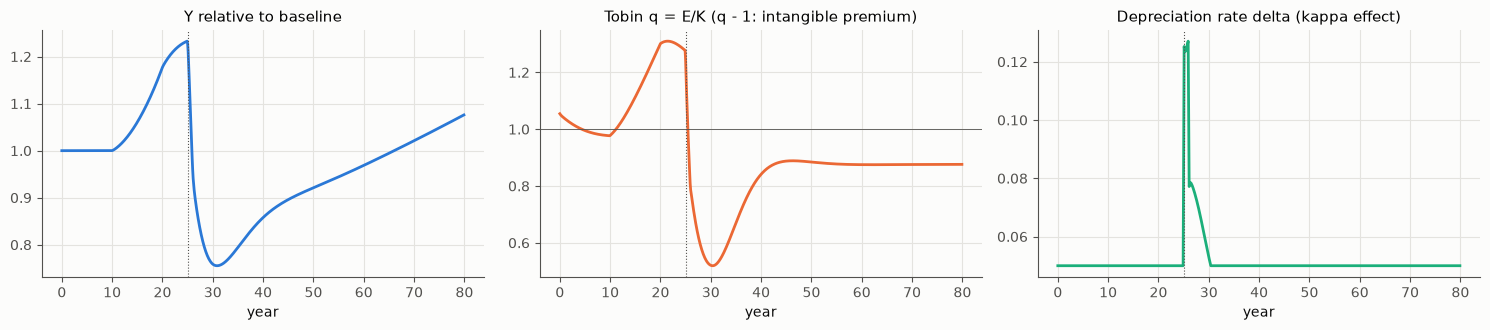

q: 10 年 0.98、20 年 1.30、24 年 1.29、27 年 0.67、35 年 0.67
損耗率 δ の最大 0.127(平時 0.05)


In [57]:
i_ = lambda x: int(round(x / 0.1))
base = cm_land.simulate_land(T=80, g_q=0.03)
sc = cm_land.simulate_land(T=80, g_q=0.03, shocks=euph + hike)
t_ = sc['t']
fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
ax[0].plot(t_, sc['Y'] / base['Y'], color=PAL[0]); ax[0].set(title='Y relative to baseline', xlabel='year')
ax[1].plot(t_, sc['q'], color=PAL[1]); ax[1].axhline(1, color=INK2, lw=0.6); ax[1].set(title='Tobin q = E/K (q - 1: intangible premium)', xlabel='year')
ax[2].plot(t_, sc['delta'], color=PAL[2]); ax[2].set(title='Depreciation rate delta (kappa effect)', xlabel='year')
for a_ in ax:
    a_.axvline(25, color=INK2, lw=0.8, ls=':')
plt.tight_layout(); plt.show()
print(f"q: 10 年 {sc['q'][i_(10)]:.2f}、20 年 {sc['q'][i_(20)]:.2f}、24 年 {sc['q'][i_(24)]:.2f}、27 年 {sc['q'][i_(27)]:.2f}、35 年 {sc['q'][i_(35)]:.2f}")
print(f"損耗率 δ の最大 {sc['delta'].max():.3f}(平時 {cm_land.LAND_DEFAULT['d0']})")

- ユーフォリアのあいだ、$q$ は 1 を大きく超えて上がる。作者の言葉で言えば、「知財の評価」が膨らむ。利上げで、$q$ は一挙に下がる。
- $q$ が下がると、$\kappa$ の効き目で損耗率 $\delta$ が跳ね上がり、資本そのものが壊れる。

これは、第 5 章で見た 2019 年のモデルの知財の動き(評価として積まれ、同じ期のうちに切り下げで消える)と、同じ「評価の生成と消滅」の型である。違うのは、v6 では、評価の消滅が実物(資本)の目減りを呼ぶことである。2019 年のモデルの知財の切り下げは、実物に何も影響しなかった(贅沢品の需要は所得で決まっていた。第 3 章)。

### 7.4 土地を担保にする

v6 の標準の設定では、担保の上限($\lambda = 0.6$)は、ほとんどかからない。企業の借入は、担保より、投資の意欲(利潤と $q$)で決まっている。だから、土地を担保に足しても、景気の循環は変わらない。

土地の担保が効くのは、**担保の上限にかかっている経済**である。そこで、担保の掛け目 $\lambda$ を小さくした経済で、土地の担保を足す。比べるのは、次の六つである。

- $\lambda = 0.2$、0.15、0.1(土地の担保なし)
- $\lambda = 0.1$ + 土地($\lambda_T = 0.77$。平時の担保の総額が $\lambda = 0.2$ と同じになるように選んだ)
- 同じく、土地に泡が乗る場合($\phi_T = 1$)
- $\lambda = 0.05$ + 土地($\lambda_T = 1.15$。平時の担保の総額が $\lambda = 0.2$ と同じ)

経済                              好況の山(基準比)   崩れの底   山からの落ち込み   借入/所得の最大   担保の上限にかかった期間の割合


lam 0.2                             1.233         0.753        38.9%          0.92            0.00


lam 0.15                            1.205         0.708        41.3%          0.95            0.09


lam 0.1                             1.095         0.801        26.9%          0.64            0.07


lam 0.1 + land 0.77                 1.233         0.752        39.0%          0.92            0.00


lam 0.1 + land 0.77, bubble         1.233         0.743        39.8%          0.94            0.05


lam 0.05 + land 1.15                1.233         0.751        39.0%          0.92            0.00


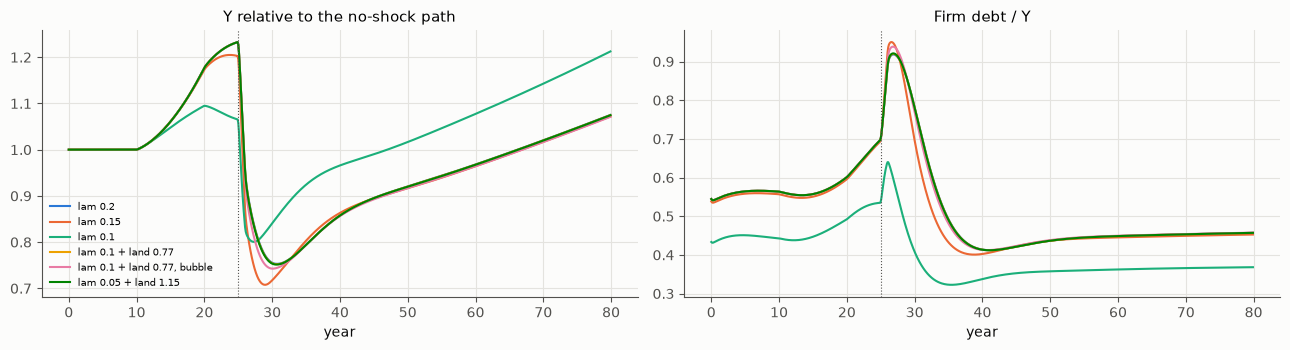

In [58]:
CASES7 = [('lam 0.2', dict(lam=0.2)), ('lam 0.15', dict(lam=0.15)), ('lam 0.1', dict(lam=0.1)),
          ('lam 0.1 + land 0.77', dict(lam=0.1, lam_T=0.77)), ('lam 0.1 + land 0.77, bubble', dict(lam=0.1, lam_T=0.77, phi_T=1.0)),
          ('lam 0.05 + land 1.15', dict(lam=0.05, lam_T=1.15))]
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
print('経済                              好況の山(基準比)   崩れの底   山からの落ち込み   借入/所得の最大   担保の上限にかかった期間の割合')
for j, (lab, kw) in enumerate(CASES7):
    o = cm_land.simulate_land(T=80, g_q=0.03, shocks=euph + hike, **kw)
    b_ = cm_land.simulate_land(T=80, g_q=0.03, **kw)
    r = o['Y'] / b_['Y']
    cap = kw['lam'] * (o['E'] + o['K']) + kw.get('lam_T', 0.0) * o['V_T']
    bind = np.mean(o['L'][i_(5):i_(60)] > 0.97 * cap[i_(5):i_(60)])
    ax[0].plot(o['t'], r, color=PAL[j], label=lab, lw=1.5)
    ax[1].plot(o['t'], o['L_Y'], color=PAL[j], label=lab, lw=1.5)
    print(f'{lab:30s}      {r[:260].max():.3f}         {r[250:].min():.3f}       {1 - r[250:].min() / r[:260].max():6.1%}          {o["L_Y"].max():.2f}            {bind:.2f}')
for a_ in ax:
    a_.axvline(25, color=INK2, lw=0.8, ls=':')
ax[0].set(title='Y relative to the no-shock path', xlabel='year'); ax[0].legend(fontsize=7)
ax[1].set(title='Firm debt / Y', xlabel='year')
plt.tight_layout(); plt.show()

- 担保の掛け目を小さくすると($\lambda = 0.1$)、好況のあいだに借入が担保の上限にかかり、好況が抑えられる(所得の山は基準の 1.1 倍どまり)。その分、崩れも浅い(山からの落ち込みは 3 割弱)。**担保の上限は、好況と崩れの両方を抑える安定装置**として働く。ただし、中くらいの制約($\lambda = 0.15$)では、好況の途中で一時的に上限にかかるだけで、崩れはむしろ少し深くなる(約 41%)。上限がいつ、どれだけかかるかで、効き方は変わる。
- そこに土地の担保を足すと、上限がゆるみ、好況も崩れも、担保の制約のない経済と同じ大きさに戻る(山は 1.23 倍、落ち込みは約 4 割)。土地に泡が乗ると、崩れはさらに少し深くなる。
- 担保の総額をそろえたまま、中身を資本から土地に替えても($\lambda = 0.2$、$\lambda = 0.1$ + 土地、$\lambda = 0.05$ + 土地)、結果はほとんど変わらない。この模型で効いているのは、**担保の中身より、担保の総額が上限にかかるかどうか**である。

作者の構想「担保としての土地」は、v6 の中では、こう言える。**土地を担保にできると、信用の上限がゆるみ、好況も崩れも大きくなる。** 第 6.4 節で、2019 年のモデルの中で「取引できる土地を増やすと、担保のある経済でだけ信用が増える」ことを見たのと、同じ向きである。

ただし、この小さな版の土地の値段は、所得と金利で決まり、**借りたお金で土地が買われて値段が上がる**という回路を持っていない。Kiyotaki and Moore(1997)の増幅の核心はその回路にあり、第 6.4 節の 2019 年のモデルの版(値段が、借りて払える買い手の数で決まる)には、それがあった。v6 に入れるには、土地の市場(誰が土地を買い、値段がどう決まるか)を、v6 の部門の中に作る必要がある。それは、別のノートの仕事である。

### 7.5 2019 年のモデルと v6 のあいだ

二つのモデルを並べると、互いに足りないものを補い合っていることがわかる。

| | 2019 年の資産市場のモデル | v6(信用循環モデル) |
|---|---|---|
| 主体 | 1000 人の個人 | 五つの部門(個人はいない) |
| お金 | 現金 = マイナスの負債。利子なし、借入の上限なし | 銀行の貸出が預金を作る。金利、準備率、担保制約 |
| 資産の値打ち | 知財は売り手の知財と土地で値が付き、評価で積まれ、毎期切り下げられる。土地は値段 10 で固定 | 株式的な富 E = 期待利潤の資本還元。土地はない |
| 所得 | 賃金と値段は外から与えられる | 需要で決まる(乗数) |
| 何が落ち着きを生むか | 流れがストックに応じて変わる負のフィードバック(第 3 章) | 担保と金利、期待の適応 |
| 何が崩れを生むか | (崩れはない) | 評価の目減りが資本を壊す($\kappa$) |
| 分配 | 個人の分布、移動性(第 4 章) | 部門のあいだの分配(賃金と利子・配当) |

別のノート(資産市場つきの v6)では、次の方針で、二つを統合することを考える。

1. **土地の市場を、v6 の中に作る**: 土地の値段が、借りて払える買い手と売り手の釣り合いで決まり(第 5.2、6.4 節)、土地が担保になる。Kiyotaki–Moore の増幅の回路が入る。
2. **知財を、無形資本として v6 の E とつなぐ**: 知財の評価は利潤の見込みから生まれ、陳腐化で目減りする(第 5.1 節の切り下げ)。知財の売り手への支払いは、企業の利益から(第 6.5 節の自主研究と国庫)。
3. **個人の分布の層を足す**: v6 の部門の中に、2019 年のモデルのような個人を置き、誰が借り、誰が持ち、誰が逆転するかを見る(第 4 章)。
4. **恒等式で検算する**: 第 3 章の二つの恒等式(全 liability の変化 = Erosion − 返済、正味の金融資産の変化 = 所得 − 支出)と、第 2 章の帳簿(相手方の部門を置いて閉じる)を、毎期の検算に使う。作者が 2022 年に「商品市場の現金バランスを見ていなかった」と反省したことを、最初から組み込む。
5. **借入の上限を二つ持つ**: 自然な借入制約(毎期返せる額 ÷ 利率。第 3.6 節)と、担保の制約(掛け目 × 担保の値打ち。第 6.4 節)。

そして、そこから、作者がもともと考えていた `micro_economy_*.py`(価格を最適化で決める商品市場。ノート 1)との統合に進む。

## 第 8 章 まとめと、続くノートへ

### 8.1 問いへの答え

**問い 1: 2019 年のモデルは何をしていたのか。どこが筋が良く、どこが足りなかったのか。**

- 土地と知財の資産市場と、賃金と贅沢品だけの商品市場を、取り崩し(Erosion)と返済の二つの流れでつないだモデルである(第 1・2 章)。
- 筋が良かったのは、次の三つである。
  - 2011 年からの「現金はマイナスの負債」の書き方が、資産市場の中の保存を保証していた。
  - 知財を「売っても減らず、何度でも売れる」ものとし、評価で積み上がるものとして表した。
  - 知財の総額を毎期もとに戻す切り下げで、モデルを発散させずに保った(第 5 章で、これが内生的な減耗率であり、正しい判断だったことを見た)。
- 足りなかったのは、次の三つである。
  - 商品市場の相手方(企業・国)がモデルの外にいて、企業が失業手当の分だけ黒字を貯め込み、お金が漏れていた(第 2 章)。
  - 土地に値段がなかった(第 5 章)。
  - 戦術を比べる基準(利得)がなく、売り手と買い手の選び方が「中庸」の勘で決まっていた(第 2 章)。

**問い 2: 全 Erosion と全返済は、なぜ、どういう額で釣り合うのか。借金の合計は、なぜ際限なく増えないのか。**

- 全 liability の変化は、毎期、Erosion − 返済にちょうど等しい(第 3 章)。
- 全 liability を留め置いて測ると、Erosion は全 liability について右下がり、返済は右上がりの曲線になる。全 liability は、その交点で釣り合う。返済率 0.5 で約 −8400、0.9 で約 −11900、0.1 でも約 +2 万に交点があり、増加はいずれ終わる。
- 釣り合いを生むのは、平均への回帰ではなく、**流れがストックに応じて変わる負のフィードバック**である。ショックからの戻りの速さ(約 6 期で半分)も、交点での曲線の傾きで決まる。

**問い 3: 返済率を変えても、なぜ贅沢品の需要が変わらないのか。**

- 正味の金融資産(全貯蓄 − 全 liability)の変化は、毎期、「10 × 働く人数 − 15 × 需要」に等しい。これが落ち着く限り、需要は「(賃金 − 必需品)× 働く人数 ÷ 贅沢品の値段」= 500 に決まる(第 3 章)。
- 返済率や手元の借り入れの余地は、ストック(誰がどれだけ借り、持っているか)を動かすだけで、流れの水準は変えない。ストックを動かしているあいだだけ、一時的に需要が変わる。値段(賃金、贅沢品の値段)は流れを変えるので、効果が続く。
- これは、ストック・フロー一貫モデルの定常状態の性質の、作者による偶然の再発見だった。

**問い 4: 富の分布は、どういう形に落ち着くのか。初期値と同じ形に戻る分布は、どういうものか。**

- 落ち着く形は、次のとおりである(第 4 章)。
  - 知財は、形の数 1.6 のガンマ分布(作者の言う「0 で少し下がる山型」)。
  - 貯蓄は、0 のかたまり、5 の倍数のとがり、0〜30 への広がりの三つからなる。
  - liability は、裾の重い山。
  - 正味資産は、ガンマ分布に近い。
- 初期値の分布の形をこれにそろえれば、最初の過渡的な動きはほぼ消える。作者の直感は正しかったが、その形は、規則を決めたあとに走らせて求めるものだった。
- 逆転のしやすさは、主に「誰が売り手になって代金を受け取るか」で決まる。このモデルは、貧しい人も売り手として加わり続ける「永続する賭け」の経済である。

**問い 5: 土地と知財は、何が違うのか。知財を買うのは誰か。免許と懲罰的罰金は、知識の蓄積をどう変えるか。**

- 知財の切り下げは、総額を保つ減耗率を毎期自動で選ぶ規則で、定率で言えば 0.22 前後にあたる(第 5 章)。
- 知財の評価は、積まれたのと同じ期のうちに全体として消える。知財の市場が経済に残すのは、買い手から売り手への現金の移動だけで、知財は当たれば大きい、くじに近い資産である。
- 土地は、値段が 10 に固定された、利子のつかない預金である。値段を動かすと、手元のお金の多さで値段が決まる。
- 2020 年の「免許と懲罰的罰金」の比較は、「免許(知財を吟味する市場)のほうが平等で、知見を多く生む」の部分は確かめられた。「懲罰的罰金が最大級の蓄積者を出す」の部分は、確かめられなかった。

**問い 6: 2021〜22 年の構想は、どう式にできるのか。v6 の株式的な富を、土地と知財に分けると何が見えるのか。**

- 「資本主義の基礎等式」の最初の形は、ピケティの第二基本法則($\beta = s/g$)と同じ構造で、2019 年のモデルの中でも「資産の値打ち = 流れ ÷ 減耗率」として成り立つ(第 6 章)。反転した形(1/貯蓄率)は、短い目の需要の効果(カレツキ、節約のパラドックス)にあたる。
- 「知財の総額 = 株価の総額」は、無形資本の考え方にあたる。
- 「担保としての土地」は、取引できる土地を増やすと、担保のある経済でだけ信用が増える形で現れる(江戸時代の読み)。
- 「国庫からの持ち出しは純現金増になる」は、政府の赤字 = 民間の黒字の恒等式そのものである。
- v6 に土地を担保として足すと、担保の上限という安定装置が外れ、好況も崩れも大きくなる(第 7 章)。

### 8.2 2019 年の発想を、どう発展させればよかったか

1. **商品市場の相手方を、部門として置く。** 企業と国を帳簿に載せ、企業の利益の行き先(配当、税、研究への支払い)を決める。作者の 2022 年の反省と、第 6.5 節の「自主研究への国庫からの受け取り」が、その方向である。
2. **恒等式で検算する。** 全 liability の変化 = Erosion − 返済、正味の金融資産の変化 = 所得 − 支出、を毎期確かめる。
3. **借入に上限を付ける。** 利子を入れるなら、自然な借入制約(毎期返せる額 ÷ 利率)が要る。担保を入れるなら、担保の制約(掛け目 × 担保の時価)が要る。作者の 2011 年の「BI を担保にした貸付」の考えが、前者そのものである。
4. **土地に値段を付ける。** 値段が手元のお金(と借りられる額)で決まるようにすれば、担保と信用の回路が入る。
5. **選び方を、利得から決める。** 「中庸」の勘で売り手と買い手の選び方を決めるのではなく、各人が何を良しとするかを決めて、その結果として選び方が出てくるようにする(ノート O の 2.5 節のトーナメントと同じ方向)。
6. **分布は、規則から求める。** 初期値は、規則を決めて走らせた定常状態から取る。

### 8.3 贅沢品・嗜好品・知財の別

このシリーズのモデルでは、「贅沢品」「嗜好品」「知財」という言葉が、モデルごとに違う役割で使われてきた。

| モデル | 言葉 | 実際の役割 |
|---|---|---|
| 2011 年の外作用モデル(ノート O) | 嗜好品 | 買うと減らずに「文化資本」として積み上がる。**資産** |
| micro_economy(ノート 1) | 贅沢品 | 必需品を超えた分の消費。余った労働の受け皿。**消費** |
| 2019 年の資産市場(この文書) | 贅沢品 / 知財 | 贅沢品は値段 15 の**消費**。知財は売り買いされ、評価で積まれ、切り下げられる**資産** |
| 2021〜22 年の構想(第 6 章) | 知財 = 「自主研究」という贅沢品 | 買い手には**消費**、売り手には**資産の収入**。二つの役割を一つの取引で表そうとしている |
| 必需品と贅沢品の宇宙的独立関係(2025〜26) | 贅沢品(知的財産) | 当たり外れのわからない**探索** |

混ざるのには理由がある。作者の直感の核は、「**必要を超えた余剰を、どう使うか**」である。余剰の使い道は三つある。

- **使い切る**: 贅沢品の消費。
- **貯めて残す**: 嗜好品・文化資本・土地などの資産。
- **探す**: 研究・自主研究。当たれば知財になり、新しい財や、新しい経済(ノート O)を生む。

そして、この三つは、現実には一つの行為の中で重なる。教育は、受ける人にとっての消費であり、同時に人的資本(資産)への投資である。凝った嗜好品の消費は、新しい市場を開く探索でもありうる。

そこで、言葉としては、次の三つの軸で切り分けるのがよい。

1. 使えば消えるか(消費)、残るか(資産)。
2. 一人が使うと他の人が使えなくなるか(競合的な財)、使えるか(非競合的な知識)。
3. 所得が増えたとき、所得以上に増やすか(経済学の言う「贅沢財」)、あまり増やさないか(必需財)。

| | 消えるか | 競合的か | 必需か贅沢か | 例 |
|---|---|---|---|---|
| 必需品 | 消える | 競合的 | 必需 | 食料 |
| 贅沢品 | 消える | 競合的 | 贅沢 | 外食、旅行 |
| 嗜好品・文化資本 | 残る(資産) | 競合的 | 贅沢 | 美術品、蔵書。値打ちは好みと地位で決まる(Veblen の誇示的消費、Bourdieu の文化資本) |
| 知財 | 残る(資産) | 非競合的 | ― | 発明、ソフトウェア、作品の原本 |
| 株式(と債券などの金融資産) | 残る(資産) | ― | ― | 企業の将来の利益への請求権。値打ちは期待の資本還元で、知財と同じく評価で膨らみ、縮む。ただし、**相手方のある請求権**で、経済全体で足すと、企業の側の資産と打ち消し合う(ノート O の第 4 章) |

株式も、この仲間に入る。株式は、知財と同じく、期待によって値打ちが決まり、評価で膨らんで縮む(第 7.3 節の v6 の $E$)。違うのは、知財が実物の資産(しかも非競合的な知識)であるのに対し、株式は企業への**請求権**で、経済全体で足すと、企業の側の資産(有形資本と知財)と打ち消し合うことである。作者の「知財の総額 = 株価の総額」(第 6.3 節)は、この二つを同じものと見た式で、請求権(株式)と、その裏付けとなる実物(知財と有形資本)を区別すると、より正確になる。

国民経済計算(SNA 2008)も、研究開発・ソフトウェア・娯楽作品の原本を「知的財産生産物」として、消費ではなく固定資本への投資に数えている。モデルでは、余剰の三つの使い道を別の勘定で書き(消費は消え、資産は帳簿に載って減耗と評価の変化を受け、探索は費用として払って当たったものだけが知財として資産に載る)、一つの取引が二つの役割を持つ場合(教育、自主研究)は、二つの仕訳に分けて書くのがよい。そうすれば、作者の 2021 年の苦心(知財の代金の 1 割は売り手へ、残りは贅沢品の購入へ)も、帳簿の上で筋が通る。

(この区別は、シリーズ全体にかかわる。ノート 1 の 5.2 節(贅沢品は労働の受け皿)、ノート O の 2.3 節(嗜好品 = 文化資本)、ノート I の第 6 章(贅沢品 = 探索)、ノート 4 の第 11 章(文化と多様性)から、この表を参照する。)

### 8.4 続くノートへ

- **ノート 4(2026年の経済モデル統合)**: 第 7.5 節の設計方針(土地の市場、知財と無形資本、個人の分布の層、恒等式による検算、二つの借入の上限)で、2019 年のモデルと v6 を統合した「資産市場つきの v6」(v6a、そして家計を標本にした v6b)を作り、`micro_economy_*.py`(ノート 1)の立て直し(me_c)と合わせた(ノート 4 第 1・4 章)。
- **ノート P(ポイントと年金と信用)**: 作者が 2006〜2011 年に考えた、はてなポイントの制度設計(投げ銭予約、分配の基金とペンション、BI が否認されたときのポイントの返し方)。第 3.6 節の自然な借入制約と、マイナス金利で貸倒れの判断ができなくなる問題は、そこで改めて扱った(ノート P 第 8 章)。
- **ノート I(必需品と贅沢品の宇宙的独立関係)**: 8.3 節の「探索としての贅沢品」を、探索と活用の問題として書いた(ノート I 第 6 章)。
- **ノート 3(シミュレーション仏教の経済)**: 死蔵資産、大バクチ、生活保護。第 4 章の富の分布と移動性、第 3 章の恒等式との対応を見た。

### 8.5 残る問い

- **輸出入**: 作者は 2019 年に、次は交易をモデル化したいと書き、「最適化を一本にするか、複数本回すか」と迷っていた(cocolog:91037236)。信用循環モデルの「信用の世界経済は一つか」の縮約の考えが、その答えの一つになる。
- **失業と資産**: 作者は、「資産があるほうが失業する可能性が高い」ことを組み込むべきではないかと書いた。今のモデルでは、誰が失業するかは資産と無関係で、失業は続きやすい(第 2.3 節)。
- **選び方の内生化**: 売り手と買い手の選び方を、各人の利得から決める。
- **贅沢品の上限**: 一人一期に一つという贅沢品の上限が、お金が積み上がっても流れが増えない理由になっていた(第 6.5 節)。贅沢品の量や種類を連続にすれば、どう変わるか。

---

### 8.6 Lean による一括の確かめ

章ごとに書き足してきた `asset_market.lean` の最後に、名前空間を閉じる行を足し、Lean に一括して確かめさせる(Lean 4 v4.34.1 と Mathlib の入った lake のプロジェクトの場所を、このノートと同じディレクトリの `.leandir` に一行で書いておく)。

In [59]:
%%writefile -a asset_market.lean
end AssetMarket

Appending to asset_market.lean


In [60]:
import os, shutil, subprocess
LEANDIR = open('.leandir').read().strip() if os.path.exists('.leandir') else None
if LEANDIR:
    lake = shutil.which('lake') or os.path.expanduser('~/.elan/bin/lake')
    env = dict(os.environ, PATH=os.path.dirname(lake) + ':' + os.environ.get('PATH', ''))
    path = os.path.abspath('asset_market.lean')
    r = subprocess.run([lake, 'env', 'lean', path], cwd=LEANDIR, capture_output=True, text=True, env=env)
    print(r.stdout[-3000:], r.stderr[-3000:])
    n_thm = sum(1 for line in open(path) if line.startswith('theorem '))
    print(f'=== asset_market.lean: {n_thm} 個の定理を確かめた。終了コード {r.returncode}(0 なら、すべての証明が通った) ===')
    assert r.returncode == 0
else:
    print('Lean のプロジェクトがない(.leandir がない)ので飛ばす。Lean 4(v4.34.1)と Mathlib の入った lake のプロジェクトの場所を .leandir に一行で書く')

 
=== asset_market.lean: 5 個の定理を確かめた。終了コード 0(0 なら、すべての証明が通った) ===


## 付録 A: 再現のために

### A.1 このノートが書き出すファイル

このノートは、実行すると、作業ディレクトリに次のファイルを書き出す。どれも `%%writefile` のセルの中身そのものである。

| ファイル | 中身 | 章 |
|---|---|---|
| `sma1_orig.py` | 2019 年の元のコードの取得(sha256 の確認)と、表示を止めて乱数の種を固定した実行 | 1.2 |
| `sma1.py` | 元のコード(その2 の版)の書き直し。元とぴったり同じ計算をする。帳簿・土地の値段・担保のための差し込み口(既定では計算に影響しない) | 1.3 |
| `anat2.py` | 帳簿(相手方の部門)、傾斜のついた選び方の確率、雇用の続き方 | 2 |
| `stockflow.py` | 全 liability の留め置きの実験、ショックからの戻り、利子を付けた版 | 3 |
| `dist2.py` | ランダムな交換の模型、分布、初期値の比較、移動性の指標 | 4 |
| `landip.py` | 知財の減耗のしかた、土地の値段を動かす版、知財の損得、免許と懲罰的罰金 | 5 |
| `idea2021.py` | 基礎等式、担保としての土地、自主研究への国庫からの受け取り | 6 |
| `cm_land.py` | 信用循環モデル v6 の取得(sha256 の確認)と、土地を担保に足した版 | 7 |
| `orig_cache/` | GitHub から取ってきた元のコード(`simple_market_a1_01.py`、`_02.py`、`exp_01_01.py`)と、v6 の `sims.py` | 1.2、7.2 |

### A.2 実行環境

In [61]:
import platform
print('Python', sys.version.split()[0], '/', platform.platform())
print('numpy', np.__version__, '/ scipy', scipy.__version__, '/ matplotlib', matplotlib.__version__)
print('2019 年のコード: JRF-2018/simple_market_a1 commit', sma1_orig.COMMIT)
print('信用循環モデル: JRF-2018/credit_simulation_v6 commit', cm_land.V6_COMMIT)
print('FAST =', FAST, '/ 並列', N_JOBS)

Python 3.14.4 / Linux-6.6.114.1-microsoft-standard-WSL2-x86_64-with-glibc2.43
numpy 2.5.4 / scipy 1.18.1 / matplotlib 3.11.2
2019 年のコード: JRF-2018/simple_market_a1 commit 563669b3e0ddee2e02473f0a1b0705b7e10fd157
信用循環モデル: JRF-2018/credit_simulation_v6 commit b73a367a647bc611a2b14fb8cf75d7cb5bb58b0b
FAST = False / 並列 8


元のコードは、Python の `random`(メルセンヌ・ツイスタ)だけで乱数を引いている。書き直しとの一致(第 1 章)は、元のコードと書き直しを同じ環境で走らせて確かめたもので、浮動小数点数の足し算の順序も、元のコードと同じにしてある。Python の版が大きく違うと、`random` の一部の関数の作り方が変わって、同じ乱数の種でも数字が変わることはありうる。

## 付録 B: 用語集

| 用語 | 意味 |
|---|---|
| liability | 2019 年のモデルの、借金と現金をまとめた量。プラスなら借金、マイナスなら現金(2011 年のモデルからの書き方) |
| Erosion(取り崩し) | 貯蓄が足りないとき、現金を取り崩すか借りて払うこと。お金が資産市場の側から商品市場へ流れ出る |
| 返済 | 働く人が、賃金から必需品を引いた残りの一定割合(返済率)で、借金を返すこと。お金が商品市場から資産市場の側へ戻る |
| 知財の切り下げ | 毎期、知財の総額をその期のはじめの値に戻すように、全員の知財に同じ倍率をかけること |
| 傾斜(coeff) | 売り手・買い手を選ぶときの、順位による選ばれやすさの差の大きさ |
| Rank Change Mean | 各人の、これまでの純資産の順位の最大と最小の差の、全員での平均。作者の逆転のしやすさの指標 |
| ストック・フロー一貫モデル | すべての流れとストックに、払う側と受け取る側を書くモデル。部門の収支の和は 0 になる |
| 正味の金融資産 | ここでは、全員の貯蓄 − 全 liability |
| 留め置きの実験 | 毎期、全員の liability に同じ額を足し引きして、全 liability を決まった値に保ち、そのときの流れを測る実験 |
| 負のフィードバック | ストックが動くと、それを元に戻す向きに流れが変わる仕組み |
| 自然な借入制約 | 毎期返せる額を利率で割った値。それを超える借金は、利子だけで返せる額を上回る |
| 担保の制約 | 借りられる額を、担保の時価 × 掛け目までに限ること |
| 指数分布・ガンマ分布 | ランダムな交換が生む富の分布。貯める割合があると、0 の近くが少ない山の形(ガンマ分布)になる |
| 移動性 | 順位の入れ替わりやすさ。順位の相関や Shorrocks の指標で測る |
| 内生的な減耗率 | モデルの中の状態から決まる、資産の目減りの率 |
| 保有利得 | 持っているあいだに値段が変わったことによる得(取引によらない、評価の変化) |
| 資本主義の第二基本法則 | ピケティの $\beta = s/g$。長い目で見た、富と所得の比 |
| 無形資本 | 研究開発、ソフトウェア、ブランド、組織の知識など、形のない資本 |
| トービンの q | 企業の市場での値打ちと、資本を作り直す費用の比 |
| 信用循環(Kiyotaki–Moore) | 担保の値上がりが借入を増やし、借入が担保の値段をさらに押し上げる、増幅の回路 |
| 贅沢財(経済学) | 所得が増えると、所得以上の割合で増える財 |
| 知的財産生産物(SNA) | 研究開発・ソフトウェア・娯楽作品の原本など。国民経済計算では固定資本への投資に数える |

## 付録 C: 過去の議論

この文書の材料になった作者の記事と「ひとこと」を、古い順に挙げる。「ひとこと」の ID(cocolog:…)は、http://jrockford.s1010.xrea.com/cocolog_helper/id2url.cgi?q=cocolog:… で URL に直せる。

- **2011 年 1〜3 月**: 「外作用的簡易経済シミュレーションのアイデアと Perl による実装」(ノート O)。現金をマイナスの負債として書く。借金がいくらでもでき、働くのはランダムに選ばれた者だけ(ベーシックインカム論の影響)。
- **2011 年 3 月**(aboutme:137725): BI を担保にした貸付の考え(第 3.6 節)。
- **2019 年 5 月 31 日**: 「資産市場の簡易シミュレーション」(その1)。同じ日の「ひとこと」(cocolog:91037236)で、2011 年のモデルから失われたもの(入れ子、カタストロフィックな遷移、BI 論の影響)、次は輸出入、と書いた。6 月の追記で、greed も失われたこと、価格がモデルに大きく効いていたことに気づいた。
- **2019 年 6 月 11 日**: 「その2 論理的モデル進化」。四つの「現実的」モデル、逆転のチャンス、インパクト実験、返済率の謎。
- **2020 年 2 月 24 日**: バージョン 0.0.3(知財の買い手を「純資産の多い人」から選ぶオプション)。同じ日の「ひとこと」(cocolog:91702707)で、免許と懲罰的罰金を比べた(第 5.4 節)。
- **2020 年 4 月 8 日**: GitHub に登録。
- **2021 年 11 月〜2022 年 1 月**(cocolog:93150989): 資本主義の基礎等式、知財の総額 = 株価の総額、担保としての土地、江戸時代、自主研究と国庫、教育目的金融税、変動資産、現金税、商品市場の現金バランス(第 6 章)。
- **2026 年 1 月**(cocolog:95815240): 永続する賭けと格差の固定(第 4.5 節)、マイナス金利で貸倒れの判断ができなくなる問題(第 3.6 節)。

---

## 参考文献

### 作者の記事・コード・ノート

- JRF「資産市場の簡易シミュレーション」(2019 年 5 月)、ブログ『JRF の私見:税・経済・法』: http://jrf.cocolog-nifty.com/society/2019/05/post-9da6e7.html
- JRF「資産市場の簡易シミュレーション その2 論理的モデル進化」(2019 年 6 月): http://jrf.cocolog-nifty.com/society/2019/06/post-4e7664.html
- JRF, simple_market_a1(Python のコード、public domain): https://github.com/JRF-2018/simple_market_a1 (このノートは commit `563669b` を使う)
- JRF「外作用的簡易経済シミュレーションのアイデアと Perl による実装」(2011 年): http://jrf.cocolog-nifty.com/society/2011/01/post.html
- JRF「価格を最適化で決める経済 ── 2020年までの micro_economy モデルの解剖」(ノート 1)、「経済の中で経済が育つ ── 2011年の外作用モデルと『埋め込み』の遷移」(ノート O)、2026 年。
- JRF「信用創造はどこで止まるのか」「信用の世界経済は一つか」(2026 年)、https://github.com/JRF-2018/credit_simulation_v6 (このノートは commit `b73a367` の `python/sims.py` を使う)
- 「富の分布について」、駒澤大学学術機関リポジトリ: http://repo.komazawa-u.ac.jp/opac/repository/all/33054/ (作者が 2019 年に参照したもの)
- 和泉潔『人工市場 ── 市場分析の複雑系アプローチ』森北出版、2003 年(作者が参照。シミュレーションが「ヤッてみたらコーなった」式になりがちだという批判)。

### 富の分布と移動性

- Dragulescu, A. and Yakovenko, V. M. (2000), "Statistical Mechanics of Money", *European Physical Journal B* 17, 723–729.
- Chakraborti, A. and Chakrabarti, B. K. (2000), "Statistical Mechanics of Money: How Saving Propensity Affects Its Distribution", *European Physical Journal B* 17, 167–170.
- Patriarca, M., Chakraborti, A., and Kaski, K. (2004), "Statistical Model with a Standard Γ Distribution", *Physical Review E* 70, 016104.
- Shorrocks, A. F. (1978), "The Measurement of Mobility", *Econometrica* 46(5), 1013–1024.

### 貨幣・信用・ストックとフロー

- Godley, W. and Lavoie, M. (2007), *Monetary Economics: An Integrated Approach to Credit, Money, Income, Production and Wealth*, Palgrave Macmillan.
- Kiyotaki, N. and Moore, J. (1997), "Credit Cycles", *Journal of Political Economy* 105(2), 211–248.
- Aiyagari, S. R. (1994), "Uninsured Idiosyncratic Risk and Aggregate Saving", *Quarterly Journal of Economics* 109(3), 659–684(自然な借入制約)。
- Kalecki, M. (1942), "A Theory of Profits", *Economic Journal* 52(206/207), 258–267.
- Koo, R. C. (2008), *The Holy Grail of Macroeconomics: Lessons from Japan's Great Recession*, Wiley.
- Tobin, J. (1969), "A General Equilibrium Approach to Monetary Theory", *Journal of Money, Credit and Banking* 1(1), 15–29.

### 資本と無形資本

- Piketty, T. (2014), *Capital in the Twenty-First Century*, Belknap Press of Harvard University Press.
- Piketty, T. and Zucman, G. (2014), "Capital is Back: Wealth-Income Ratios in Rich Countries 1700–2010", *Quarterly Journal of Economics* 129(3), 1255–1310.
- Hall, R. E. (2001), "The Stock Market and Capital Accumulation", *American Economic Review* 91(5), 1185–1202.
- Corrado, C., Hulten, C., and Sichel, D. (2009), "Intangible Capital and U.S. Economic Growth", *Review of Income and Wealth* 55(3), 661–685.
- Haskel, J. and Westlake, S. (2018), *Capitalism without Capital: The Rise of the Intangible Economy*, Princeton University Press.
- Arrow, K. J. (1962), "Economic Welfare and the Allocation of Resources for Invention", in Nelson, R. R. (ed.), *The Rate and Direction of Inventive Activity*, Princeton University Press, 609–626.
- European Commission, IMF, OECD, United Nations, and World Bank (2009), *System of National Accounts 2008*, New York.

### 贅沢品・嗜好品・余剰

- Veblen, T. (1899), *The Theory of the Leisure Class*, Macmillan.
- Bourdieu, P. (1979), *La Distinction: Critique sociale du jugement*, Éditions de Minuit.
- Bataille, G. (1949), *La Part maudite*, Éditions de Minuit.